# Mark-sheet OCR — Google Colab + Google Drive (user-rule updates v6)

This version preserves dynamic box detection and folder-wise Excel export while adding validation-safe selection: blank mark cells are scored as 0; when both alternatives are attempted, the first question in each configured pair is counted; and when Mobile and Server provide valid different values, the Server value is selected. Arithmetic and the bubbled grand total remain validation checks and never overwrite observed readings. Truly blank cells are distinguished from nonblank but unreadable handwriting. Implausible Hough bubble grids use normalized-template x anchors with detected row centers where possible; any fallback explicitly forces manual review. Excel output includes separate computed/written totals and a Field Audit worksheet.

**Important:** the provided pilot indicates recognition is not yet reliable enough for the 49 GB full run. Run the pilot first and compare the per-view diagnostic output. A confident-looking OCR result can still be wrong, so keep validation and manual review enabled. The v6 checkpoint uses a new filename so records created by earlier logic are not silently reused.

The input folder is read recursively from Google Drive; results and checkpoints are saved to Drive. Each image-containing source folder gets its own Excel workbook as soon as that folder finishes; an optional combined workbook can still be generated at the end.


### Bubble-grid fallback retained from v5

The `751483.jpg` pilot showed that v4's orange-bounding-box fallback could shift the bubble grid and report a suspicious Total Marks value of 72. v5 uses the normalized template's expected bubble x-centers when Hough column spacing is invalid, keeps regularly detected Hough row centers, and adds a review flag whenever the bubble grid was not fully Hough-validated. A fallback read is provisional, not an automatic pass.

### v22 math and fraction update

The pipeline cell now parses explicit fractions (`1/2`, `5 1/2`, `½`), decimals (`0.5`, `2.5`), and plus expressions (`3+2`) before falling back to integer extraction. An equation prefers the value after `=`, while a disagreement between its two sides is retained as a diagnostic. A slash is never treated as a plus sign. Connected cursive half-marks such as the supplied Q5 sample use a narrow, low-confidence shape fallback only in Part A; the handwritten totals and bubbled Total Marks still decide whether the sheet can pass.

### v23 single 10-mark questions

Some Part B questions are single 10-mark questions rather than `(a)` + `(b)` pairs. When a mark of `6`–`10` appears in one row, the other row is blank/dashed, and the written row total agrees, the pipeline stores it as a total-only question instead of rejecting it as an out-of-range sub-mark. The Field Audit identifies the unused a/b row. If any of those conditions disagree, the sheet stays in `REVIEW`.

### Per-folder Excel reports

Full-batch processing now writes one Excel workbook for each innermost image-containing folder (for example `Main/Folder1/InnerA/`) as soon as that folder finishes. Reports are saved directly under `OCR_Results` in the matching top-level/inner-folder path, for example `OCR_Results/Folder1/InnerA.xlsx`. A combined workbook for all 15,000 sheets is optional and disabled by default, so a disconnect or long run does not leave you waiting for one giant export at the end.

### v24 audit-driven accuracy update

A local audit re-read every cell of the 604 available sheets by hand and compared the
manual reading with the pipeline output.  The changes below come from that audit:

* **Part B digits get a second opinion.**  When the mobile recogniser returns a single
  weak Part B digit (score below 0.9) the server model reads the same crops as well.
  This removed about 14% of the wrong Part B digits without touching the strong reads.
* **A dash is a dash.**  A cell that holds a clear horizontal dash plus a tiny,
  low-confidence mark is scored 0 instead of 1.  A dash next to a real digit is still
  never collapsed to 0.
* **Handwritten totals are read as one number.**  `Total(A)`, `Total(B)` and
  `TOTAL(A+B)` are additionally read from a white-canvas union of their handwriting
  components (mobile and server), so a `17` or `52` split over two strokes is no longer
  read as `1`, and the printed `TOTAL(A+B)` label is no longer read as the value.
* **No invented Part A marks.**  An unreadable Part A cell is no longer filled in from a
  handwritten `Total(A)` unless the written totals agree with the bubbled total and the
  solution is unique.  A misread `Total(A)` used to invent two zero marks.
* **No invented marks at all.**  If the bubble total can only be reached by giving a
  cell a value that no recogniser read, that value is not stored and the sheet is
  flagged `REVIEW` with the question named.  Roughly half of the invented marks were
  wrong, so they must not be published as if they were read.
* **Contradictions fail the sheet.**  When the written `Total(A)` and the written
  `Total(B)` both disagree with the computed marks, or when a confidently read row
  total contradicts the marks of that row while the written totals also disagree, the
  sheet is flagged `REVIEW` instead of being reported as valid.
* **The joint solver stops chasing a misread total.**  The handwritten totals are only
  used as a tie-breaker when they agree with each other and with the bubble.

Audit result on the 168 sheets that were hand-audited mark by mark: wrong mark cells
296 -> 263 of 4184, sheets with at least one wrong mark 92 -> 87, false `OK` sheets
(sheets that contradict themselves but were reported valid) 17 -> 6.  The cost of the
stricter rules is that 12 more audited sheets are sent to `REVIEW` instead of being
reported as valid, which is the intended trade-off: nothing is invented any more.
Runtime on the local CPU-only machine went from 9.6 s to 10.4 s per sheet.

### v25 audit-driven accuracy update

The hand audit was extended to 367 of the 604 sheets (every Part A/B mark and both
totals recorded as ground truth).  The v25 code comes from the errors that audit found:

* **Half marks are real.**  A Part A cell read as `3.5` (or a `3` plus a half-mark
  candidate) is no longer forced to an integer: the half grid is kept as a candidate
  and a written `Total(A)` can only correct one half-mark cell, never invent others.
* **Rule fragments no longer become 1s.**  Thin vertical fragments of the printed cell
  border are filtered out, while a genuine tall narrow stroke (a handwritten `1` that
  the recogniser misses) is still accepted.  Thicker hand-drawn dashes are allowed as
  `0` without letting a real digit collapse to zero.
* **Written row totals only repair with arithmetic support.**  When a written
  `Total(a+b)` disagrees with the two parts, the parts are only adjusted when exactly
  one alternative reaches that total with strong support and a clear margin over the
  next option; otherwise the sheet stays in `REVIEW`.
* **Geometry guides half-mark losses.**  For a Part B row that is half a mark short,
  the number of ink glyphs and the width of the main stroke tell the solver which part
  lost the half mark, instead of guessing.
* **Float-safe comparisons.**  Mark comparisons use an epsilon so a computed `0.5`
  total is not misread as a contradiction.

Audit result on the full audited set (367 sheets): status agreement with the manual
audit 72.5% (v24: 70.6%, baseline: 72.5%), false `OK` sheets that contradict themselves
29 (v24: 28, baseline: 53), sheets sent to `REVIEW` despite clean marks 72 (v24: 80,
baseline: 48), wrong mark cells 646 of 11377 (5.7%, v24: 640).  Runtime on the CPU-only
machine is 10.5 s per sheet for the full 604-sheet folder; full runs remain resumable.


In [1]:
# 1. Install dependencies for Google Colab
# Select PaddlePaddle GPU when a Colab GPU is present; fall back to CPU otherwise.
import os, re, sys, subprocess, importlib.util

def run_install(*args):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args], check=True)

# PaddleOCR 3.x requires PaddlePaddle 3.x. Colab's NVIDIA driver determines the GPU wheel.
has_nvidia = subprocess.run(["bash", "-lc", "command -v nvidia-smi >/dev/null 2>&1"],
                            capture_output=True).returncode == 0
if has_nvidia:
    driver_text = subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout
    match = re.search(r"Driver Version:\s*([0-9.]+)", driver_text)
    driver_version = tuple(int(x) for x in match.group(1).split(".")) if match else (0,)
    # cu126 needs a sufficiently recent driver; cu118 supports older Colab drivers.
    if driver_version >= (550,):
        try:
            run_install("paddlepaddle-gpu==3.2.0", "-i", "https://www.paddlepaddle.org.cn/packages/stable/cu126/")
        except Exception as e:
            print("CUDA 12.6 Paddle wheel install failed; trying CUDA 11.8:", str(e)[:180])
            run_install("paddlepaddle-gpu==3.2.0", "-i", "https://www.paddlepaddle.org.cn/packages/stable/cu118/")
    else:
        run_install("paddlepaddle-gpu==3.2.0", "-i", "https://www.paddlepaddle.org.cn/packages/stable/cu118/")
else:
    run_install("paddlepaddle==3.2.0", "-i", "https://www.paddlepaddle.org.cn/packages/stable/cpu/")

run_install("paddleocr>=3.0.0", "openpyxl", "opencv-python-headless")
from PIL import Image, ImageDraw, ImageFont
import numpy, cv2, matplotlib.pyplot as plt
import paddle
print("Paddle:", paddle.__version__, "| CUDA compiled:", paddle.is_compiled_with_cuda())
try:
    print("Available Paddle GPU devices:", paddle.device.cuda.device_count())
except Exception:
    print("Available Paddle GPU devices: 0 (CPU mode)")


/usr/local/lib/python3.13/dist-packages/paddle/utils/cpp_extension/extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


Paddle: 3.2.0 | CUDA compiled: False
Available Paddle GPU devices: 0


In [2]:
# 2. Dynamic mark-sheet pipeline: orange-grid detection, ink segmentation,
#    bubble reading, PaddleOCR digit recognition and validation.
#
# No reference pixel coordinates are used.  Every sheet is calibrated from the
# orange rules that are actually visible in that image, so the same code copes
# with different resolutions, grid shades, ink colours and digit sizes.
import os, re, json, time, math, glob, statistics
from pathlib import Path
from dataclasses import dataclass, field
from typing import Tuple, Dict, List, Optional, Sequence
from itertools import product, combinations
from fractions import Fraction

import cv2
import numpy as np
from PIL import Image, ImageOps

import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

PIPELINE_VERSION = "dynamic-grid-v25-audit"


# ============================================================================
# 3. DYNAMIC LAYOUT DETECTION (orange rules -> Part A / Part B / bubbles)
# ============================================================================

def orange_mask(arr):
    lab = cv2.cvtColor(arr, cv2.COLOR_RGB2LAB).astype(np.int16)
    a = lab[:, :, 1] - 128
    b = lab[:, :, 2] - 128
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    h, s, v = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    m = ((a > 18) & (b > 4)) | (((h < 25) | (h > 170)) & (s > 110) & (v > 80))
    return m.astype(np.uint8)


def estimate_skew(mask):
    H, W = mask.shape
    sc = 1200.0 / max(W, H)
    small = cv2.resize(mask, None, fx=sc, fy=sc, interpolation=cv2.INTER_NEAREST)
    edges = cv2.Canny(small * 255, 50, 150)
    lines = cv2.HoughLinesP(edges, 1, np.pi / 1800, threshold=35,
                            minLineLength=max(30, int(0.05 * small.shape[1])), maxLineGap=10)
    if lines is None:
        return 0.0
    hs, vs = [], []
    for x1, y1, x2, y2 in np.asarray(lines).reshape(-1, 4):
        dx = float(x2 - x1); dy = float(y2 - y1)
        L = math.hypot(dx, dy)
        ang = math.degrees(math.atan2(dy, dx))
        if abs(ang) <= 8:
            hs.append((ang, L))
        elif abs(abs(ang) - 90) <= 8:
            vs.append((ang - 90 if ang > 0 else ang + 90, L))
    vals = hs if len(hs) >= 4 else vs
    if not vals:
        return 0.0
    vals.sort(key=lambda t: t[1], reverse=True)
    vals = vals[:8]
    wsum = sum(max(1.0, L) for _, L in vals)
    return -float(sum(a * max(1.0, L) for a, L in vals) / wsum)


def rotate(arr, ang):
    H, W = arr.shape[:2]
    M = cv2.getRotationMatrix2D((W / 2, H / 2), ang, 1.0)
    return cv2.warpAffine(arr, M, (W, H), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_REPLICATE)


def groups(idx, gap=2):
    if len(idx) == 0:
        return []
    gs = []; s = p = int(idx[0])
    for v in idx[1:]:
        v = int(v)
        if v > p + gap:
            gs.append((s, p)); s = v
        p = v
    gs.append((s, p))
    return [int(round((s + p) / 2)) for s, p in gs]


def line_peaks(sub, axis, frac):
    vals = sub.sum(axis=axis).astype(float)
    span = sub.shape[1] if axis == 1 else sub.shape[0]
    thr = frac * span
    return groups(np.where(vals >= thr)[0], 2)


# Form-relative rule positions.  These are fractions of each detected
# rectangle, never absolute pixels; observed rules always take priority.
B_V_FRAC = [0.000, 0.105, 0.177, 0.255, 0.332, 0.413, 0.493, 0.573,
            0.650, 0.726, 0.799, 0.873, 1.000]
B_H_FRAC = [0.014, 0.206, 0.404, 0.596, 0.798]
A_V_FRAC = [i / 6.0 for i in range(7)]
A_H_FRAC = [0.011, 0.456, 0.967]


def _merge_close(vals, tol):
    vals = sorted(int(v) for v in vals)
    out = []
    for v in vals:
        if not out or v - out[-1] > tol:
            out.append(v)
        else:
            out[-1] = int(round((out[-1] + v) / 2))
    return out


def _resolve_lines(detected, count, lo, hi, fracs, min_gap, max_gap,
                   edge_weight=0.0, force_edges=False):
    """Observed orange rules first; form geometry only fills missing rules.

    A candidate run is scored on gap regularity, agreement with the expected
    rule spacing and proximity to the expected positions.  If no complete run
    is visible (faded, torn or merged rules), the normalized positions are
    reconstructed and snapped to any nearby observed peaks.
    """
    span = max(1.0, hi - lo)
    vals = _merge_close([v for v in detected if lo - 6 <= v <= hi + 6],
                        max(2, int(min_gap) // 8))
    expected = [lo + f * span for f in fracs]

    if len(vals) >= count:
        best = None
        for i in range(len(vals) - count + 1):
            run = vals[i:i + count]
            gaps = np.diff(run)
            if np.any(gaps < max(3, int(min_gap * 0.70))):
                continue
            if max_gap is not None and np.any(gaps > max_gap):
                continue
            mean_gap = max(1.0, float(np.mean(gaps)))
            cv = float(np.std(gaps)) / mean_gap
            pos = float(np.mean([abs(run[j] - expected[j])
                                 for j in range(count)])) / span
            eg = np.diff(expected)
            gdev = float(np.mean(np.abs(gaps - eg))) / max(
                1.0, float(np.mean(np.abs(eg))))
            score = cv + 0.60 * gdev + 0.80 * pos
            if edge_weight:
                score += edge_weight * ((run[0] - lo) + (hi - run[-1])) / span
            if best is None or score < best[0]:
                best = (score, run)
        if best is not None:
            return [int(v) for v in best[1]]

    # No complete visible run: rebuild from the form's normalized rule
    # positions, using nearby observed peaks where they exist.
    step = span / max(1, count - 1)
    out, used = [], set()
    for e in expected:
        cand = sorted((abs(v - e), v) for v in vals if v not in used)
        if cand and cand[0][0] <= max(4.0, 0.32 * step):
            out.append(int(round(cand[0][1])))
            used.add(cand[0][1])
        else:
            out.append(int(round(e)))
    if force_edges:
        out[0], out[-1] = int(round(lo)), int(round(hi))
    for i in range(1, len(out)):
        if out[i] <= out[i - 1] + 2:
            out[i] = out[i - 1] + max(3, int(min_gap) // 2)
    return out


# ------------------------------------------------------------- components
def _layout_components(m):
    n, lab, st, cen = cv2.connectedComponentsWithStats(m, 8)
    out = []
    for i in range(1, n):
        x, y, w, h, area = [int(z) for z in st[i]]
        if area < 1800:
            continue
        out.append(dict(x=x, y=y, w=w, h=h, area=area, ar=w / float(max(1, h))))
    return out


def _merge_components(comps):
    """Merge a table split into pieces by a broken rule (but never merge bubble panels)."""
    comps = sorted(comps, key=lambda c: c['area'], reverse=True)
    changed = True
    while changed:
        changed = False
        for i in range(len(comps)):
            for j in range(i + 1, len(comps)):
                a, b = comps[i], comps[j]
                ov = min(a['y'] + a['h'], b['y'] + b['h']) - max(a['y'], b['y'])
                if ov < 0.65 * min(a['h'], b['h']):
                    continue
                if max(a['h'], b['h']) / float(max(1, min(a['h'], b['h']))) > 1.5:
                    continue
                gap = max(a['x'], b['x']) - min(a['x'] + a['w'], b['x'] + b['w'])
                if gap > 0.02 * (a['w'] + b['w'] + 1) + 12:
                    continue
                x0 = min(a['x'], b['x']); x1 = max(a['x'] + a['w'], b['x'] + b['w'])
                y0 = min(a['y'], b['y']); y1 = max(a['y'] + a['h'], b['y'] + b['h'])
                comps[i] = dict(x=x0, y=y0, w=x1 - x0, h=y1 - y0, area=(x1 - x0) * (y1 - y0),
                                ar=(x1 - x0) / float(max(1, y1 - y0)))
                del comps[j]
                changed = True
                break
            if changed:
                break
    return comps


def detect_layout(arr):
    H, W = arr.shape[:2]
    raw = orange_mask(arr)
    ang = estimate_skew(raw)
    if abs(ang) >= 0.8:
        arr = rotate(arr, ang)
    m = orange_mask(arr)
    comps = _merge_components(_layout_components(m))

    def table_lines(c, vfrac=0.55, hfrac=0.50):
        x, y, w, h = c['x'], c['y'], c['w'], c['h']
        sub = m[y:y + h, x:x + w]
        v = [x + p for p in line_peaks(sub, 0, vfrac)]
        hh = [y + p for p in line_peaks(sub, 1, hfrac)]
        return v, hh

    # ---- Part-B candidate: wide, central rectangle
    b_cands = []
    for c in comps:
        if not (0.22 * W <= c['w'] <= 0.70 * W and 0.10 * H <= c['h'] <= 0.48 * H):
            continue
        if not (2.4 <= c['ar'] <= 4.6):
            continue
        if not (0.10 * H <= c['y'] <= 0.90 * H):
            continue
        v, hh = table_lines(c)
        score = c['area'] * (1.0 + 0.02 * min(13, len(v)) + 0.02 * min(5, len(hh)))
        b_cands.append((score, c, v, hh))
    b_cands.sort(key=lambda t: t[0], reverse=True)
    B = None
    for score, c, v, hh in b_cands:
        if len(v) >= 8 or len(hh) >= 3:
            B = dict(c); B['v_raw'] = v; B['h_raw'] = hh
            break

    # ---- Part-A candidate: flat rectangle above B
    a_cands = []
    for c in comps:
        if not (4.5 <= c['ar'] <= 10.0 and c['area'] > 2200):
            continue
        if B is not None and c['y'] + c['h'] > B['y'] + 6:
            continue
        v, hh = table_lines(c, 0.55, 0.50)
        a_cands.append((c, v, hh))
    if B is not None:
        a_cands.sort(key=lambda t: abs((t[0]['y'] + t[0]['h']) - B['y'])
                     + 0.25 * abs((t[0]['x'] + t[0]['w']) - (B['x'] + B['w'])))
    else:
        a_cands.sort(key=lambda t: t[0]['area'], reverse=True)
    A = None
    for c, v, hh in a_cands:
        if len(v) >= 5 or len(hh) >= 2:
            A = dict(c); A['v_raw'] = v; A['h_raw'] = hh
            break

    if B is None:
        raise ValueError('Part-B grid not found')
    if A is None:
        raise ValueError('Part-A grid not found')

    # ---- resolve actual grid lines
    B['v'] = _resolve_lines(B['v_raw'], 13, B['x'], B['x'] + B['w'], B_V_FRAC,
                            min_gap=max(24, int(0.12 * B['h'])),
                            max_gap=int(0.90 * B['w']), edge_weight=2.0)
    B['hlines'] = _resolve_lines(B['h_raw'], 5, B['y'], B['y'] + B['h'], B_H_FRAC,
                                 min_gap=max(24, int(0.15 * B['h'])),
                                 max_gap=max(55, int(0.32 * B['h'])),
                                 edge_weight=0.0, force_edges=False)
    A['v'] = _resolve_lines(A['v_raw'], 7, A['x'], A['x'] + A['w'], A_V_FRAC,
                            min_gap=max(40, int(0.35 * A['w'] / 6)),
                            max_gap=int(0.45 * A['w']), edge_weight=2.0)
    A['hlines'] = _resolve_lines(A['h_raw'], 3, A['y'], A['y'] + A['h'], A_H_FRAC,
                                 min_gap=max(16, int(0.30 * A['h'])),
                                 max_gap=max(55, int(0.90 * A['h'])),
                                 edge_weight=0.0, force_edges=False)

    # ---- TOTAL(A+B) strip: label is orange and is removed later, so keep right half
    ty0 = B['hlines'][-1] + 2
    ty1 = min(H - 1, max(ty0 + 12, int(B['y'] + B['h'] - 1)))
    tx0 = B['x'] + int(0.40 * B['w'])
    tx1 = B['v'][-1] - 2
    totalab = (tx0, ty0, tx1, ty1)

    bubbles = detect_bubbles(arr, B, W, H)
    return dict(arr=arr, mask=m, angle=ang, B=B, A=A, totalab=totalab, bubbles=bubbles)


# ------------------------------------------------------------------ bubbles
def _nearest(vals, target, tol):
    near = [v for v in vals if abs(v - target) <= tol]
    return float(np.median(near)) if near else float(target)


def detect_bubbles(arr, B=None, W=None, H=None):
    """Read the 4x10 OMR panel from the observed rings beside Part B.

    The panel is located relative to the detected Part B rectangle.  Hough
    circles only refine the nominal grid inside that panel; if the rings are
    too faint to detect, the nominal geometry is used unchanged.
    """
    if B is None:
        return None
    if W is None:
        W = arr.shape[1]
    if H is None:
        H = arr.shape[0]
    x, y, w, h = B['x'], B['y'], B['w'], B['h']
    xexp = [x + w * f for f in (1.051, 1.115, 1.207, 1.279)]
    yexp = [y + h * f for f in (-0.615, -0.405, -0.205, 0.000,
                                0.210, 0.420, 0.630, 0.840, 1.050, 1.260)]
    if xexp[-1] > W - 2:
        return None
    scale = h / 217.0
    rx1 = int(max(0, xexp[0] - 0.04 * W))
    rx2 = int(min(W, xexp[-1] + 0.04 * W))
    ry1 = int(max(0, yexp[0] - 0.05 * H))
    ry2 = int(min(H, yexp[-1] + 0.05 * H))
    pts = []
    if rx2 - rx1 > 30 and ry2 - ry1 > 80:
        gray = cv2.medianBlur(
            cv2.cvtColor(arr[ry1:ry2, rx1:rx2], cv2.COLOR_RGB2GRAY), 5)
        circles = cv2.HoughCircles(
            gray, cv2.HOUGH_GRADIENT, dp=1,
            minDist=max(10, int(0.14 * h)),
            param1=80, param2=18,
            minRadius=max(5, int(6 * scale)),
            maxRadius=max(9, int(20 * scale)))
        if circles is not None:
            for cx, cy, r in np.asarray(circles).reshape(-1, 3):
                pts.append((float(cx + rx1), float(cy + ry1), float(r)))
    xs = [_nearest([p[0] for p in pts], xe,
                   0.55 * (xexp[1] - xexp[0]))
          for xe in xexp]
    ys = [_nearest([p[1] for p in pts], ye,
                   0.55 * (yexp[1] - yexp[0]))
          for ye in yexp]
    radii = []
    for xe in xs:
        for ye in ys:
            radii += [p[2] for p in pts
                      if abs(p[0] - xe) < 0.35 * abs(xexp[1] - xexp[0])
                      and abs(p[1] - ye) < 0.35 * abs(yexp[1] - yexp[0])]
    r = float(np.median(radii)) if radii else 12.0 * scale
    return dict(xs=xs, ys=ys, r=r, roi=(rx1, ry1, rx2, ry2),
                n_hough=len(pts))


# --------------------------------------------------------------- diagnostic
def overlay(det, path):
    arr = det['arr'].copy()
    for key, col in [('B', (0, 190, 0)), ('A', (190, 0, 190))]:
        d = det.get(key)
        if not d:
            continue
        cv2.rectangle(arr, (d['x'], d['y']), (d['x'] + d['w'], d['y'] + d['h']), col, 2)
        for xx in d['v']:
            cv2.line(arr, (xx, d['y']), (xx, d['y'] + d['h']), col, 1)
        for yy in d['hlines']:
            cv2.line(arr, (d['x'], yy), (d['x'] + d['w'], yy), col, 1)
    x1, y1, x2, y2 = det['totalab']
    cv2.rectangle(arr, (x1, y1), (x2, y2), (255, 120, 0), 2)
    b = det.get('bubbles')
    if b:
        for xx in b['xs']:
            for yy in b['ys']:
                cv2.circle(arr, (int(xx), int(yy)), int(b['r']), (0, 128, 255), 1)
    Image.fromarray(arr).save(path, quality=88)




# ============================================================================
# 4. INK MASK, CELL ASSIGNMENT AND TIGHT-CROP RENDERING
# ============================================================================

def ink_mask(arr, orange):
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    H, W = gray.shape
    k = max(11, (min(H, W) // 40) | 1)
    bg = cv2.medianBlur(gray, k)
    diff = bg.astype(np.int16) - gray.astype(np.int16)
    mad = float(np.median(np.abs(diff - np.median(diff))))
    dark = diff > max(12.0, 4.0 * mad)
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    s, v = hsv[:, :, 1], hsv[:, :, 2]
    colored = (s > 70) & (v < 248)
    grid = cv2.dilate(orange, np.ones((3, 3), np.uint8), iterations=1) > 0
    ink = (dark | colored) & (~grid)
    ink = ink.astype(np.uint8)
    # re-join strokes broken by removing the printed rule
    ink = cv2.morphologyEx(ink, cv2.MORPH_CLOSE, np.ones((2, 2), np.uint8))
    return ink


def cell_defs(det):
    A, B = det['A'], det['B']
    cells = []
    # Part A data row, Q1..Q5 + Total(A)
    for i in range(6):
        cells.append(dict(group='A', key='Q%d' % (i + 1) if i < 5 else 'TOTAL_A',
                          x1=A['v'][i], x2=A['v'][i + 1],
                          y1=A['hlines'][1], y2=A['hlines'][2], kind='partA',
                          ref_h=A['hlines'][2] - A['hlines'][1]))
    # Part B question columns and 3 body rows
    for i in range(10):
        q = 'Q%d' % (i + 6)
        for r, name in enumerate(('a', 'b', 'total')):
            cells.append(dict(group='B', key=q, row=name,
                              x1=B['v'][i + 1], x2=B['v'][i + 2],
                              y1=B['hlines'][r + 1], y2=B['hlines'][r + 2], kind='partB',
                              ref_h=B['hlines'][r + 2] - B['hlines'][r + 1]))
    # Total(B): merged cell over a/b/total rows
    cbw = (B['v'][12] - B['v'][11])
    rh = (B['hlines'][4] - B['hlines'][1]) / 3.0
    cells.append(dict(group='B', key='TOTAL_B', row=None,
                      x1=B['v'][11] - int(0.04 * cbw), x2=B['v'][12] + int(0.04 * cbw),
                      y1=B['hlines'][1] - int(0.15 * rh), y2=B['hlines'][4] + int(0.25 * rh), kind='totalB',
                      ref_h=rh))
    x1, y1, x2, y2 = det['totalab']
    cells.append(dict(group='TOTAL', key='TOTAL_AB', row=None,
                      x1=x1, x2=x2, y1=y1, y2=y2, kind='totalAB',
                      ref_h=(B['hlines'][4] - B['hlines'][1]) / 3.0))
    return cells


def _components(ink):
    n, lab, st, cen = cv2.connectedComponentsWithStats(ink, 8)
    out = []
    for i in range(1, n):
        x, y, w, h, area = [int(z) for z in st[i]]
        if area < 10:
            continue
        # drop leftover straight rule fragments
        if (h <= 4 and w >= 12) or (w <= 4 and h >= 12):
            continue
        out.append(dict(id=i, x=x, y=y, w=w, h=h, area=area,
                        cx=float(cen[i][0]), cy=float(cen[i][1])))
    return out, lab


def assign_components(comps, cells, det):
    """Assign each ink component to the cell whose centre is closest in cell units.

    Using normalised distance (instead of strict containment) keeps a digit with the
    cell it was written in even when its stroke crosses the printed rule.
    """
    for c in cells:
        c['ids'] = []
        c['comps'] = []
        c['cx'] = (c['x1'] + c['x2']) / 2.0
        c['cy'] = (c['y1'] + c['y2']) / 2.0
        c['cw'] = max(8.0, (c['x2'] - c['x1']))
        c['ch'] = max(8.0, c['ref_h'])
    H, W = det['arr'].shape[:2]
    cell_x1 = min(c['x1'] for c in cells); cell_x2 = max(c['x2'] for c in cells)
    cell_y1 = min(c['y1'] for c in cells); cell_y2 = max(c['y2'] for c in cells)
    row = max(8.0, min(c['ref_h'] for c in cells))
    roi = (cell_x1 - 0.02 * W, cell_y1 - 0.6 * row,
           cell_x2 + 0.03 * W, cell_y2 + 0.3 * row)
    panel = None
    b = det.get('bubbles')
    if b:
        r = max(4.0, b['r'])
        panel = (min(b['xs']) - 2 * r, min(b['ys']) - 2 * r,
                 max(b['xs']) + 2 * r, max(b['ys']) + 2 * r)
    def excluded(cx, cy):
        if not (roi[0] <= cx <= roi[2] and roi[1] <= cy <= roi[3]):
            return True
        if panel and panel[0] <= cx <= panel[2] and panel[1] <= cy <= panel[3]:
            return True
        return False
    for comp in comps:
        if 'force_idx' in comp and 0 <= comp['force_idx'] < len(cells):
            hit = cells[comp['force_idx']]
            hit['ids'].append(comp['id'])
            hit['comps'].append(comp)
            continue
        cx, cy = comp['cx'], comp['cy']
        if excluded(cx, cy):
            continue
        best = None
        for c in cells:
            dx = (cx - c['cx']) / c['cw']
            # Total(B) is a merged 3-row cell: measure vertical distance in
            # row units so an answer written in the a/b rows is not pushed away.
            ch = c['ch'] * (3.0 if c.get('key') == 'TOTAL_B' else 1.0)
            dy = (cy - c['cy']) / ch
            d = (dx * dx + dy * dy) ** 0.5
            if best is None or d < best[0]:
                best = (d, c)
        if best is None or best[0] > 1.15:
            continue
        hit = best[1]
        hit['ids'].append(comp['id'])
        hit['comps'].append(comp)
    return cells


def cell_owner_map(cells, det, ink):
    """Nearest-cell ownership for every ink pixel (used only to split blobs)."""
    H, W = ink.shape
    owner = np.full((H, W), -1, np.int16)
    ys, xs = np.nonzero(ink)
    if len(xs) == 0:
        return owner
    for i, c in enumerate(cells):
        c['idx'] = i
        c['_ocx'] = (c['x1'] + c['x2']) / 2.0
        c['_ocy'] = (c['y1'] + c['y2']) / 2.0
        c['_ocw'] = max(8.0, c['x2'] - c['x1'])
        c['_och'] = max(8.0, c.get('ref_h', c['y2'] - c['y1']))
        if c.get('key') == 'TOTAL_B':
            c['_och'] *= 3.0
    cx = np.array([c['_ocx'] for c in cells], dtype=np.float32)
    cy = np.array([c['_ocy'] for c in cells], dtype=np.float32)
    cw = np.array([c['_ocw'] for c in cells], dtype=np.float32)
    ch = np.array([c['_och'] for c in cells], dtype=np.float32)
    cell_x1 = min(c['x1'] for c in cells); cell_x2 = max(c['x2'] for c in cells)
    cell_y1 = min(c['y1'] for c in cells); cell_y2 = max(c['y2'] for c in cells)
    row = max(8.0, min(c['ref_h'] for c in cells))
    roi = (cell_x1 - 0.02 * W, cell_y1 - 0.6 * row,
           cell_x2 + 0.03 * W, cell_y2 + 0.3 * row)
    b = det.get('bubbles')
    panel = None
    if b:
        r = max(4.0, b['r'])
        panel = (min(b['xs']) - 2 * r, min(b['ys']) - 2 * r,
                 max(b['xs']) + 2 * r, max(b['ys']) + 2 * r)
    for start in range(0, len(xs), 20000):
        x = xs[start:start + 20000].astype(np.float32)
        y = ys[start:start + 20000].astype(np.float32)
        dx = (x[:, None] - cx[None, :]) / cw[None, :]
        dy = (y[:, None] - cy[None, :]) / ch[None, :]
        d = dx * dx + dy * dy
        best = np.argmin(d, axis=1)
        bd = d[np.arange(len(x)), best]
        inside = ((x >= roi[0]) & (x <= roi[2]) & (y >= roi[1]) & (y <= roi[3]))
        if panel is not None:
            inside &= ~((x >= panel[0]) & (x <= panel[2]) &
                        (y >= panel[1]) & (y <= panel[3]))
        good = inside & (bd <= 1.35 * 1.35)
        owner[ys[start:start + 20000][good], xs[start:start + 20000][good]] = best[good]
    return owner


def split_components_by_owner(comps, lab, owner, cells):
    """Split one connected blob into a separate component per owning cell.

    A large 4 and the 5 below it can touch through a printed rule, producing one
    connected component.  The old assignment gave the whole blob to one row.  Here
    a blob is divided only when the pieces belong to different rows of the same
    question.  A blob that reaches into a neighbouring question column is left
    whole, because the v13 clipped/context views already handle that case.
    """
    new_lab = np.zeros_like(lab)
    new_comps = []
    next_id = 1
    for comp in comps:
        m = (lab == comp['id'])
        oids = np.unique(owner[m])
        oids = oids[oids >= 0]
        split = False
        if len(oids) > 1:
            keys = {cells[int(oid)].get('key') for oid in oids}
            split = len(keys) == 1
        if not split:
            new_lab[m] = next_id
            c = dict(comp); c['id'] = next_id
            new_comps.append(c); next_id += 1
            continue
        for oid in oids:
            sub = m & (owner == oid)
            area = int(sub.sum())
            if area < 6:
                continue
            ys, xs = np.where(sub)
            x, y = int(xs.min()), int(ys.min())
            w, h = int(xs.max() - x + 1), int(ys.max() - y + 1)
            new_lab[sub] = next_id
            new_comps.append(dict(id=next_id, x=x, y=y, w=w, h=h, area=area,
                                  cx=float(xs.mean()), cy=float(ys.mean()),
                                  force_idx=int(oid), parent=comp['id']))
            next_id += 1
    return new_comps, new_lab


def is_dash(comp, cell):
    h = max(1.0, cell['y2'] - cell['y1'])
    # A hand-drawn dash is short and wide.  Some sheets use a thicker dash
    # (about a third of the row height), so allow up to 0.35h as long as the
    # stroke is clearly wider than it is tall.  A handwritten digit is either
    # tall or roughly square and fails the width test.
    return comp['h'] < 0.35 * h and comp['w'] > 2.0 * max(1, comp['h'])


def is_rule_remnant(comp, cell):
    """True for a thin vertical fragment of the printed cell rule.

    The printed column rules are orange, but a few pixels survive the colour
    mask at the cell edge.  OCR then reads these 3x10 px fragments as ``1`` or
    ``I`` and invents a mark in an otherwise blank row.  A genuine handwritten
    digit is either taller than 0.45 row heights or wider than a rule.
    """
    rh = max(1.0, cell.get('ref_h', cell['y2'] - cell['y1']))
    if comp['w'] > max(4.0, 0.12 * rh):
        return False
    if comp['h'] > 0.45 * rh:
        return False
    margin = max(3.0, 0.12 * rh)
    left = comp['x'] - cell.get('x1', comp['x'])
    right = cell.get('x2', comp['x'] + comp['w']) - (comp['x'] + comp['w'])
    return left <= margin or right <= margin


def select_render_comps(cell):
    """Keep the significant strokes of one answer and ignore specks/printed remnants."""
    rh = max(1.0, cell.get('ref_h', cell['y2'] - cell['y1']))
    sig = []
    for comp in cell['comps']:
        if is_dash(comp, cell) or is_rule_remnant(comp, cell):
            continue
        if comp['h'] >= 0.30 * rh or comp['area'] >= 0.02 * (cell['x2'] - cell['x1']) * rh:
            sig.append(comp)
    if not sig:
        return []
    # add small detached pieces (a broken top bar, a pen lift) near the significant strokes
    out = list(sig)
    for comp in cell['comps']:
        if comp in out:
            continue
        for s in sig:
            if (comp['x'] >= s['x'] - 0.45 * rh and comp['x'] + comp['w'] <= s['x'] + s['w'] + 0.45 * rh
                    and comp['y'] >= s['y'] - 0.45 * rh and comp['y'] + comp['h'] <= s['y'] + s['h'] + 0.45 * rh):
                out.append(comp); break
    # group into horizontal clusters and keep the heaviest cluster
    out.sort(key=lambda c: c['cx'])
    groups = []
    for comp in out:
        if groups:
            g = groups[-1]
            gx1 = min(x['x'] for x in g); gx2 = max(x['x'] + x['w'] for x in g)
            gy1 = min(x['y'] for x in g); gy2 = max(x['y'] + x['h'] for x in g)
            if comp['x'] <= gx2 + 0.75 * rh and comp['y'] + comp['h'] >= gy1 - 0.3 * rh and comp['y'] <= gy2 + 0.3 * rh:
                g.append(comp); continue
        groups.append([comp])
    if not groups:
        return []
    return max(groups, key=lambda g: sum(c['area'] for c in g))


def cell_has_ink(cell):
    return len(select_render_comps(cell)) > 0


def render_cell(cell, lab, arr, orange, pad_frac=0.14, target_h=64):
    chosen = select_render_comps(cell)
    if not chosen:
        return None, None
    ids = [c['id'] for c in chosen]
    mask = np.isin(lab, ids)
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return None, None
    x1, x2 = int(xs.min()), int(xs.max()) + 1
    y1, y2 = int(ys.min()), int(ys.max()) + 1
    # pixel inclusion: component pixels + one-pixel antialias fringe
    dil = cv2.dilate(mask.astype(np.uint8), np.ones((3, 3), np.uint8), iterations=1) > 0
    keep = dil & (orange == 0)
    h, w = y2 - y1, x2 - x1
    pad = max(3, int(round(pad_frac * h)))
    H, W = arr.shape[:2]
    xa, xb = max(0, x1 - pad), min(W, x2 + pad)
    ya, yb = max(0, y1 - pad), min(H, y2 + pad)
    crop = arr[ya:yb, xa:xb].copy()
    km = keep[ya:yb, xa:xb]
    # antialias fringe is only kept when it is actually darker than paper
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    dark = gray < 235
    km = km & dark
    out = np.full_like(crop, 255)
    out[km] = crop[km]
    hh, ww = out.shape[:2]
    nh = target_h
    nw = max(18, int(round(ww * target_h / max(1, hh))))
    color = cv2.resize(out, (nw, nh), interpolation=cv2.INTER_LANCZOS4)
    # binary view
    bm = (cv2.cvtColor(color, cv2.COLOR_RGB2GRAY) < 210).astype(np.uint8)
    bm = cv2.morphologyEx(bm, cv2.MORPH_CLOSE, np.ones((2, 2), np.uint8))
    binv = np.full((nh, nw, 3), 255, np.uint8)
    binv[bm > 0] = 0
    # gray/contrast view
    g = cv2.cvtColor(color, cv2.COLOR_RGB2GRAY)
    g = cv2.createCLAHE(2.0, (4, 4)).apply(g)
    gv = cv2.cvtColor(g, cv2.COLOR_GRAY2RGB)

    # ---- extra views for oversized / overlapping handwriting -------------
    cw = max(1.0, cell["x2"] - cell["x1"])
    ch = max(1.0, cell.get("ref_h", cell["y2"] - cell["y1"]))
    overflow_x = ((cell["x1"] - x1) > 0.12 * cw) or ((x2 - cell["x2"]) > 0.12 * cw)
    overflow_y = ((cell["y1"] - y1) > 0.15 * ch) or ((y2 - cell["y2"]) > 0.15 * ch)

    # A total cell is always given a tall view: totals are often written much
    # larger than the printed row and their lower strokes run into the
    # TOTAL(A+B) strip.  For Part A, the same is needed when a loop or the
    # vertical stroke of 1 leaves the row.
    all_comps = [x for x in cell.get("comps", []) if not is_dash(x, cell)]
    all_overflow_y = False
    if all_comps:
        ay1 = min(x["y"] for x in all_comps)
        ay2 = max(x["y"] + x["h"] for x in all_comps)
        all_overflow_y = ((cell["y1"] - ay1) > 0.12 * ch
                          or (ay2 - cell["y2"]) > 0.12 * ch)
    # Only question row totals and the grand total get the tall crop.  The
    # handwritten Total(A)/Total(B) cells are separate merged cells and can
    # pick up adjacent ink if expanded.
    is_expanded_total = bool(
        cell.get("row") == "total" or cell.get("key") == "TOTAL_AB"
    )
    part_a_question = bool(cell.get("kind") == "partA"
                           and str(cell.get("key", "")).startswith("Q"))
    use_expanded = is_expanded_total or (part_a_question and
                                         (overflow_y or all_overflow_y))

    def fit80(im):
        hh, ww = im.shape[:2]
        nw = max(14, int(round(ww * 80.0 / max(1, hh))))
        return cv2.resize(im, (nw, 80), interpolation=cv2.INTER_LANCZOS4)

    # Context view: the cell plus a margin, retaining the printed box and
    # surrounding paper so a large digit is not squeezed against the crop edge.
    mx = int(round(0.18 * cw))
    my = int(round(0.30 * ch))
    cxa, cxb = max(0, cell["x1"] - mx), min(W, cell["x2"] + mx)
    cya, cyb = max(0, cell["y1"] - my), min(H, cell["y2"] + my)
    context = fit80(arr[cya:cyb, cxa:cxb].copy())

    # Expanded view: asymmetric tall crop for oversized totals.  The extra
    # space is mainly below the cell, where a large 4/5 or a long 1 continues
    # into the total strip.  The x range is clipped to the question column so
    # the neighbouring question is never pulled into the crop.
    expanded = None
    if use_expanded:
        if is_expanded_total:
            up, down = 0.45 * ch, 0.95 * ch
        else:
            up, down = 0.65 * ch, 0.70 * ch
        ex = int(round(0.10 * cw))
        exa = max(0, int(cell["x1"] - ex))
        exb = min(W, int(cell["x2"] + ex))
        eya = max(0, int(cell["y1"] - up))
        eyb = min(H, int(cell["y2"] + down))
        if exb > exa and eyb > eya:
            expanded = fit80(arr[eya:eyb, exa:exb].copy())

    # Clipped view: ink from this cell only, with a small horizontal margin.
    # This prevents a large digit in one cell from pulling the neighbouring
    # cell's digit into the crop through a shared connected component.
    kxa = max(0, int(cell["x1"] - 0.08 * cw))
    kxb = min(W, int(cell["x2"] + 0.08 * cw))
    kya = max(0, int(cell["y1"] - 0.55 * ch))
    kyb = min(H, int(cell["y2"] + 0.55 * ch))
    clip_keep = np.zeros((H, W), bool)
    clip_keep[kya:kyb, kxa:kxb] = True
    gfull = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    keep_clip = dil & clip_keep & ((orange == 0) | (gfull < 175))
    clip = None
    ys2, xs2 = np.where(keep_clip)
    if len(xs2):
        qx1, qx2 = int(xs2.min()), int(xs2.max()) + 1
        qy1, qy2 = int(ys2.min()), int(ys2.max()) + 1
        qpad = max(3, int(round(0.10 * (qy2 - qy1))))
        qxa, qxb = max(0, qx1 - qpad), min(W, qx2 + qpad)
        qya, qyb = max(0, qy1 - qpad), min(H, qy2 + qpad)
        qcrop = arr[qya:qyb, qxa:qxb].copy()
        qm = keep_clip[qya:qyb, qxa:qxb]
        qm = qm & (cv2.cvtColor(qcrop, cv2.COLOR_RGB2GRAY) < 235)
        qout = np.full_like(qcrop, 255)
        qout[qm] = qcrop[qm]
        clip = fit80(qout)

    # Dark-stroke view: keeps pen strokes that cross an orange rule, and does
    # not require perfect removal of the printed grid.
    darkv = None
    gtight = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    dm = (gtight < 175).astype(np.uint8)
    if dm.any():
        darkv = fit80(cv2.cvtColor(255 - dm * 255, cv2.COLOR_GRAY2RGB))

    # Tall total view: a handwritten total can be taller than the printed row
    # and can cross the row line above/below it.  The tight colour crop is
    # deliberately based on the assigned components; this view keeps a much
    # taller vertical window so the whole stroke is visible to OCR.  The x
    # range stays at the cell/ink width, because widening into the neighbouring
    # question is a separate contamination risk.
    tall = None
    tall_raw = None
    tall_box = None
    if is_expanded_total:
        tya = max(0, int(min(cell["y1"], y1) - 0.20 * ch))
        tyb = min(H, int(max(cell["y2"], y2) + 0.85 * ch))
        txa = max(0, int(min(cell["x1"], x1) - 0.10 * cw))
        txb = min(W, int(max(cell["x2"], x2) + 0.10 * cw))
        if txb > txa and tyb > tya:
            tall_box = (txa, tya, txb, tyb)
            tarr = arr[tya:tyb, txa:txb].copy()
            tall_raw = fit80(tarr)
            tg = cv2.cvtColor(tarr, cv2.COLOR_RGB2GRAY)
            tkeep = (tg < 235) & (orange[tya:tyb, txa:txb] == 0)
            tout = np.full_like(tarr, 255)
            tout[tkeep] = tarr[tkeep]
            tall = fit80(tout)

    return color, dict(binary=binv, gray=gv, context=context, clip=clip,
                       dark=darkv, expanded=expanded,
                       tall=tall, tall_raw=tall_raw, tall_box=tall_box,
                       large=bool(use_expanded and not overflow_x),
                       overflow_x=overflow_x, overflow_y=overflow_y,
                       box=(xa, ya, xb, yb))


def extract_sheet(path):
    arr = np.array(ImageOps.exif_transpose(Image.open(path)).convert('RGB'))
    det = detect_layout(arr)
    orange = det['mask']
    ink = ink_mask(det['arr'], orange)
    comps, lab = _components(ink)
    cells_geo = cell_defs(det)
    owner = cell_owner_map(cells_geo, det, ink)
    comps, lab = split_components_by_owner(comps, lab, owner, cells_geo)
    cells = assign_components(comps, cells_geo, det)
    out = {}
    for c in cells:
        key = c['key'] if c['group'] != 'B' or c['row'] is None else c['key'] + '_' + c['row']
        has = cell_has_ink(c)
        dash_only = (not has) and any(is_dash(x, c) for x in c.get('comps', []))
        ref_h = max(1.0, c.get('ref_h', c['y2'] - c['y1']))
        faint = (not has and not dash_only and c.get('kind') == 'partA'
                 and any((not is_dash(x, c)) and x['area'] >= 30 and x['h'] >= 0.20 * ref_h
                         for x in c.get('comps', [])))
        color, views = render_cell(c, lab, det['arr'], orange)
        out[key] = dict(cell=c, has_ink=bool(has or dash_only or faint),
                        color=color, views=views, ncomp=len(c['comps']),
                        dash_only=bool(dash_only), faint_ink=bool(faint),
                        image=det['arr'])
    return arr, det, out




# ============================ BUBBLE (OMR) READING ============================

def bubble_fill_scores(arr, det, thr=38, rscale=0.62):
    """Fill score per (row digit, column) using global paper brightness.

    The printed row digit and ring are orange, so they are removed before the
    darkness test; a real pen mark then dominates the inner disk.
    """
    b = det['bubbles']
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    orange = det['mask']
    H, W = gray.shape
    yy, xx = np.ogrid[:H, :W]
    r = max(5.0, b['r'])
    paper = float(np.percentile(gray, 90))
    m = (gray < paper - thr) & (orange == 0)
    out = np.zeros((len(b['ys']), len(b['xs'])))
    for j, x in enumerate(b['xs']):
        for i, y in enumerate(b['ys']):
            disk = ((xx - x) ** 2 + (yy - y) ** 2) <= (r * rscale) ** 2
            out[i, j] = float(m[disk].mean())
    return out


def read_bubble_marks(arr, det, thr=0.20, margin=0.08):
    """Return (total_marks_value, si_value, diagnostics).

    Columns 0/1 are the Total Marks tens/units, columns 2/3 the SI tens/units.
    """
    b = det['bubbles']
    if not b:
        return None, None, dict(error='no bubble grid')
    sc = bubble_fill_scores(arr, det)
    digits = []
    confs = []
    notes = []
    for j in range(sc.shape[1]):
        col = sc[:, j]
        order = np.argsort(col)[::-1]
        top_i, top_v = int(order[0]), float(col[order[0]])
        sec_v = float(col[order[1]]) if len(order) > 1 else 0.0
        if top_v >= thr and (top_v - sec_v >= margin or top_v >= 0.55):
            digits.append(top_i)
            confs.append(top_v)
            if top_v - sec_v < 0.05:
                notes.append('col%d tie %.2f/%.2f' % (j, top_v, sec_v))
        else:
            digits.append(None)
            confs.append(top_v)
    def val(pair):
        if pair[0] is None and pair[1] is None:
            return None
        return int((pair[0] or 0) * 10 + (pair[1] if pair[1] is not None else 0))
    total = val(digits[0:2])
    si = val(digits[2:4])
    diag = dict(digits=digits, scores=[round(c, 3) for c in confs],
                total_marked=total, si_marked=si, notes=notes)
    return total, si, diag


def analyze_sheet(path_or_image):
    """Load one sheet and return geometry, ink cells and rendered cell views."""
    if isinstance(path_or_image, (str, os.PathLike)):
        with Image.open(path_or_image) as im:
            arr = np.array(ImageOps.exif_transpose(im).convert('RGB'))
    else:
        arr = np.asarray(path_or_image)
    det = detect_layout(arr)
    orange = det['mask']
    ink = ink_mask(det['arr'], orange)
    comps, lab = _components(ink)
    cells_geo = cell_defs(det)
    owner = cell_owner_map(cells_geo, det, ink)
    comps, lab = split_components_by_owner(comps, lab, owner, cells_geo)
    cells = assign_components(comps, cells_geo, det)
    out = {}
    for c in cells:
        key = c['key'] if (c['group'] != 'B' or c['row'] is None) else c['key'] + '_' + c['row']
        has = cell_has_ink(c)
        dash_only = (not has) and any(is_dash(x, c) for x in c.get('comps', []))
        ref_h = max(1.0, c.get('ref_h', c['y2'] - c['y1']))
        faint = (not has and not dash_only and c.get('kind') == 'partA'
                 and any((not is_dash(x, c)) and x['area'] >= 30 and x['h'] >= 0.20 * ref_h
                         for x in c.get('comps', [])))
        color, views = render_cell(c, lab, det['arr'], orange)
        out[key] = dict(cell=c, has_ink=bool(has or dash_only or faint),
                        color=color, views=views, ncomp=len(c['comps']),
                        dash_only=bool(dash_only), faint_ink=bool(faint),
                        image=det['arr'])
    total_marks, si_no, bub_diag = read_bubble_marks(det['arr'], det)
    return dict(arr=det['arr'], det=det, cells=cells, views=out,
                total_marks=total_marks, si_no=si_no, bubbles=bub_diag)

# ============================================================================
# 5. OCR  (PaddleOCR PP-OCRv5 mobile, server fallback for uncertain cells)
# ============================================================================

PART_A_QUESTIONS = [f"Q{i}" for i in range(1, 6)]
PART_B_QUESTIONS = [f"Q{i}" for i in range(6, 16)]
# Mutually exclusive alternatives.  If a student attempts both questions in
# one pair, only the higher-scoring question contributes to Total(B).
PART_B_PAIRS = [("Q6", "Q7"), ("Q8", "Q9"), ("Q10", "Q11"),
                ("Q12", "Q13"), ("Q14", "Q15")]
MAX_TOTAL_B = 50


@dataclass
class LoadedModel:
    model: object
    processor: object = None
    device: str = "cpu"
    fallback_model: object = None


def _extract_paddle_result(result):
    """Return ``(text, score)`` from any PaddleOCR 3.x recognition result."""
    if result is None:
        return "", 0.0
    if isinstance(result, (list, tuple)):
        best = ("", 0.0)
        for item in result:
            text, score = _extract_paddle_result(item)
            if score > best[1] or (text and not best[0]):
                best = (text, score)
        return best
    if isinstance(result, dict):
        res = result.get("res", result)
        if isinstance(res, dict):
            for tk in ("rec_text", "text", "label"):
                if isinstance(res.get(tk), str):
                    sc = res.get("rec_score", res.get("score", 0.0))
                    return res[tk], float(sc or 0.0)
        if isinstance(result.get("json"), (dict, str)):
            return _extract_paddle_result(result["json"])
    j = getattr(result, "json", None)
    if callable(j):
        try:
            j = j()
        except Exception:
            j = None
    if isinstance(j, str):
        try:
            return _extract_paddle_result(json.loads(j))
        except Exception:
            return j, 0.0
    if isinstance(j, dict):
        return _extract_paddle_result(j)
    for tk in ("rec_text", "text"):
        v = getattr(result, tk, None)
        if isinstance(v, str):
            return v, float(getattr(result, "rec_score", 0.0) or 0.0)
    if isinstance(result, str):
        return result, 0.0
    return "", 0.0


def _to_rgb_array(image):
    if isinstance(image, np.ndarray):
        arr = image
    else:
        arr = np.asarray(image.convert("RGB"))
    return np.ascontiguousarray(arr)


def paddle_recognize_scored(loaded: LoadedModel, image, use_fallback: bool = False):
    recognizer = loaded.fallback_model if (use_fallback and loaded.fallback_model is not None) else loaded.model
    arr = _to_rgb_array(image)
    # PaddleOCR versions differ slightly in whether predict() takes a keyword,
    # a positional array, or a list.  Try the common forms once.
    result = None
    for call in (lambda: recognizer.predict(input=arr),
                 lambda: recognizer.predict(arr),
                 lambda: recognizer.predict(input=[arr]),
                 lambda: recognizer.predict([arr])):
        try:
            result = call()
            break
        except Exception:
            continue
    if result is None:
        return "", 0.0
    return _extract_paddle_result(result)


def paddle_recognize(loaded: LoadedModel, image, use_fallback: bool = False) -> str:
    return paddle_recognize_scored(loaded, image, use_fallback)[0].strip()


def vlm_predict(loaded: LoadedModel, images, prompt: str = "", max_new_tokens: int = 8) -> str:
    """Compatibility wrapper: majority vote of the recognizer over the given views."""
    from collections import Counter
    texts = []
    for im in images:
        if im is None:
            continue
        t = re.sub(r"\s+", "", paddle_recognize(loaded, im))
        if t:
            texts.append(t)
    if not texts:
        return "BLANK"
    return Counter(texts).most_common(1)[0][0]


def _clean_text(text: str) -> str:
    return re.sub(r"[`*]", "", str(text or "")).strip().upper()


_CONFUSION = {"O": "0", "I": "1", "L": "1", "S": "5", "Z": "2", "G": "6",
              "B": "8", "A": "4", "T": "7", "D": "0", "Q": "0"}


def parse_single_digit(text: str, allowed: str = "0123456789"):
    t = _clean_text(text)
    if t in {"", "BLANK", "NONE", "NULL", "N/A", "NA", "-", "_", "."}:
        return None
    compact = re.sub(r"[^A-Z0-9]", "", t)
    if len(compact) > 1:
        # keep the first character if the model appended noise like "5-"
        compact = compact[0]
    compact = _CONFUSION.get(compact, compact)
    return int(compact) if len(compact) == 1 and compact in allowed else None


_UNICODE_FRACTIONS = {
    "½": (1, 2), "⅓": (1, 3), "⅔": (2, 3), "¼": (1, 4), "¾": (3, 4),
    "⅕": (1, 5), "⅖": (2, 5), "⅗": (3, 5), "⅘": (4, 5),
    "⅙": (1, 6), "⅚": (5, 6), "⅛": (1, 8), "⅜": (3, 8),
    "⅝": (5, 8), "⅞": (7, 8),
}


def _normalize_math_text(text: str) -> str:
    """Normalize OCR punctuation without destroying fractions or decimals."""
    t = _clean_text(text)
    if not t:
        return ""
    t = (t.replace("−", "-").replace("–", "-").replace("—", "-")
          .replace("＋", "+").replace("＝", "=")
          .replace("／", "/").replace("⁄", "/").replace("∕", "/"))
    # A recogniser may output a Unicode fraction glyph on its own or after a
    # whole number, for example 2½.  Turn it into "2 1/2" before tokenizing.
    for glyph, (num, den) in _UNICODE_FRACTIONS.items():
        t = re.sub(
            r"(\d+)?%s" % re.escape(glyph),
            lambda m, n=num, d=den: ((m.group(1) + " ") if m.group(1) else "")
            + "%d/%d" % (n, d),
            t,
        )
    # LaTeX-like fraction from the recogniser, e.g. "$\frac{1}{2}$".
    t = re.sub(r"\\+frac\s*\{?\s*(\d+)\s*\}?\s*\{?\s*(\d+)\s*\}?",
               r"\1/\2", t, flags=re.I)
    # A remaining backslash is a common OCR rendering of a fraction slash.
    t = t.replace("\\", "/")
    # Currency signs, quotes and other OCR decoration are not part of a mark.
    # Keeping them would block a valid "4s$" -> 4.5 parse.
    t = re.sub(r"[^0-9A-Za-z+\-/=.,\s]", "", t)
    t = "".join(_CONFUSION.get(ch, ch) for ch in t)
    # A comma or a short dash between digits is a decimal separator in the
    # handwriting on these sheets ("2,5", "13-5").  Do this after the letter
    # confusion so an OCR "13-s" becomes "13.5".
    t = re.sub(r"(?<=\d)\s*,\s*(?=\d)", ".", t)
    t = re.sub(r"(?<=\d)\s*-\s*(?=\d)", ".", t)
    # Remove spaces around operators but keep a space in a mixed fraction such
    # as "5 1/2".  This also normalizes "1 / 2" to "1/2".
    t = re.sub(r"\s*([+/=])\s*", r"\1", t)
    return t.strip()


def _parse_math_atom(text: str, max_val: int, max_digits: int = 1,
                     allow_half: bool = False):
    """Parse one operand.  Returns ``(Fraction, kind)`` or ``(None, None)``."""
    s = _normalize_math_text(text)
    if not s:
        return None, None
    # Mixed fraction: 5 1/2, 2 3/2, etc.
    m = re.fullmatch(r"(\d+)\s+(\d+)\s*/\s*(\d+)", s)
    if m:
        whole, num, den = (int(x) for x in m.groups())
        if den == 0:
            return None, None
        v = Fraction(whole * den + num, den)
        return (v, "mixed_fraction") if 0 <= v <= max_val else (None, None)
    # Simple fraction: 1/2, 3/2, etc.
    m = re.fullmatch(r"(\d+)\s*/\s*(\d+)", s)
    if m:
        num, den = int(m.group(1)), int(m.group(2))
        if den == 0:
            return None, None
        v = Fraction(num, den)
        return (v, "fraction") if 0 <= v <= max_val else (None, None)
    # Decimal, including a trailing point left by a clipped "5" ("4." -> 4).
    # Parse this before integer stripping so 0.5 cannot become 5 and 2.5
    # cannot become 25.
    m = re.fullmatch(r"(\d+)\s*\.\s*(\d*)", s)
    if m and (m.group(2) or s.endswith(".")):
        whole, frac = m.group(1), m.group(2)
        v = Fraction(whole + "." + frac) if frac else Fraction(int(whole), 1)
        if 0 <= v <= max_val:
            return v, ("decimal" if frac else "integer")
        # The left printed rule is sometimes recognised as a leading "1" in
        # a clipped crop: "13.5" is really "3.5".  Only strip it when the
        # remainder is a valid mark and the leading digit is not part of a
        # genuine "10.x" value.
        rest = whole[1:]
        if (whole.startswith("1") and len(whole) > 1 and (frac or s.endswith("."))
                and not rest.startswith("0")):
            rv = Fraction(rest + "." + frac) if frac else Fraction(int(rest), 1)
            if 0 <= rv <= max_val:
                return rv, "rule_artifact"
        return None, None
    # Plain integer.
    m = re.fullmatch(r"(\d+)", s)
    if m:
        v = int(m.group(1))
        if 0 <= v <= max_val:
            return Fraction(v, 1), "integer"
        # Two-digit mark cells: "18" is an OCR 1.8 (a 5 mistaken for 8),
        # "15"/"25"/"35" are a decimal point lost by the recogniser.
        if max_digits == 1 and len(s) == 2 and s[0] == "0" and s[1] in "58":
            cand = Fraction(int(s[1]), 10)
            if 0 <= cand <= max_val:
                return cand, "implied_decimal"
        if (max_digits == 1 and len(s) == 2 and s[0] != "0"
                and s[1] in "58" and int(s[0]) <= max_val):
            cand = Fraction(int(s[0]) * 10 + int(s[1]), 10)
            if 0 <= cand <= max_val:
                return cand, "implied_decimal"
        # A dropped decimal point in a total: "75" -> 7.5, "135" -> 13.5.
        if (len(s) > 1 and s[-1] == "5"
                and int(s[:-1]) * 2 + 1 <= 2 * max_val):
            return Fraction(int(s[:-1]) * 2 + 1, 2), "dropped_decimal"
        # Leading rule fragment in an integer mark: "13" -> 3, and
        # "135" -> "35" -> 3.5 (the 5 is a clipped decimal).  Only recurse
        # for mark-length strings so a genuine 3-digit total is not mangled.
        if (s.startswith("1") and len(s) > 1
                and (max_digits == 1 or len(s) == 2
                     or (len(s) == 3 and max_digits >= 2))):
            sub, sub_kind = _parse_math_atom(s[1:], max_val, max_digits, allow_half)
            if sub is not None:
                return sub, "rule_artifact"
        # Legacy handwritten total: 5 1/2 is often recognised as 53 or 52.
        # Only use this narrow repair on cells that explicitly allow a half.
        if allow_half and len(s) == 2 and s[1] in "23":
            cand = Fraction(int(s[0]) * 2 + 1, 2)
            if 0 <= cand <= max_val:
                return cand, "legacy_half"
    return None, None


def _parse_math_local(text: str, max_val: int, max_digits: int = 1,
                      allow_half: bool = False):
    """Parse a fraction, decimal, integer, or a plus expression."""
    s = _normalize_math_text(text)
    if not s:
        return None, None
    if "+" in s:
        terms = [t for t in s.split("+") if t]
        if len(terms) < 2:
            return None, None
        vals = []
        for term in terms:
            v, _kind = _parse_math_atom(term, max_val, max_digits, allow_half)
            if v is None:
                return None, None
            vals.append(v)
        total = sum(vals, Fraction(0, 1))
        return (total, "sum") if 0 <= total <= max_val else (None, None)
    return _parse_math_atom(s, max_val, max_digits, allow_half)


def parse_math_result(text: str, max_val: int, max_digits: int = 1,
                      allow_half: bool = False):
    """Parse a mark and retain enough evidence for diagnostics.

    An equation prefers the RHS.  If both sides parse and disagree, the RHS
    is still used but ``equation_conflict`` is set.  If the RHS is out of
    range, a valid LHS is returned as a lower-confidence fallback.
    """
    raw = _clean_text(text)
    if not raw or raw in {"BLANK", "NONE", "NULL", "N/A", "NA", "-", "_", "."}:
        return None
    s = _normalize_math_text(raw)
    if not s:
        return None

    def out(v):
        if v is None:
            return None
        return int(v) if v.denominator == 1 else float(v)

    base = dict(raw=raw, normalized=s, value=None, kind=None,
                lhs=None, rhs=None, equation_conflict=False,
                equation_incomplete=False)
    if "=" in s:
        lhs_s, rhs_s = s.rsplit("=", 1)
        lhs, lhs_kind = _parse_math_local(lhs_s, max_val, max_digits, allow_half)
        rhs, rhs_kind = _parse_math_local(rhs_s, max_val, max_digits, allow_half)
        if rhs is not None:
            conflict = lhs is not None and lhs != rhs
            return dict(base, value=out(rhs), kind="equation",
                        lhs=out(lhs), rhs=out(rhs), rhs_kind=rhs_kind,
                        equation_conflict=bool(conflict))
        # The RHS is the preferred answer.  If it cannot be parsed in range,
        # leave the cell unreadable rather than fabricating a mark from the
        # LHS of an invalid equation.  The LHS is retained for diagnostics.
        return dict(base, kind="equation_invalid", lhs=out(lhs),
                    rhs=None, lhs_kind=lhs_kind,
                    equation_conflict=True, equation_incomplete=True)
    v, kind = _parse_math_local(s, max_val, max_digits, allow_half)
    if v is None:
        return dict(base, kind=kind or "invalid")
    return dict(base, value=out(v), kind=kind)


def parse_math_text(text: str, max_val: int, max_digits: int = 1):
    """Read a mark written as a digit, a fraction, a decimal, or a sum."""
    result = parse_math_result(text, max_val, max_digits=max_digits,
                               allow_half=False)
    return result.get("value") if result else None


def parse_integer(text: str, max_val: int, allow_half: bool = False):
    t = _clean_text(text)
    if t in {"", "BLANK", "NONE", "NULL", "N/A", "NA", "-", "_", "."}:
        return None
    # Fractions, decimals and expressions are handled by parse_math_result.
    # Do not strip a decimal point or slash into a concatenated integer.
    if re.search(r"[+/=\\.]", t) or any(g in t for g in _UNICODE_FRACTIONS):
        return None
    t = "".join(_CONFUSION.get(ch, ch) for ch in t)
    t = re.sub(r"[^0-9]", "", t)
    if not t or len(t) > 3:
        return None
    v = int(t)
    if 0 <= v <= max_val:
        return v
    if allow_half:
        # A handwritten decimal point is often lost: "75" -> 7.5, "405" ->
        # 40.5.  Only use it when the plain integer is out of range, so a
        # legitimate total of 25 or 45 is never turned into 2.5 or 4.5.
        if len(t) > 1 and t[-1] == "5" and int(t[:-1]) <= max_val:
            return int(t[:-1]) + 0.5
        # The left printed rule is sometimes recognised as a leading 1 in a
        # clipped total crop: "13" -> 3 when 13 is impossible.
        if t.startswith("1") and len(t) > 1 and int(t[1:]) <= max_val:
            return int(t[1:])
        # Legacy handwritten total: 5 1/2 is often recognised as "53"/"52".
        if len(t) == 2 and t[1] in "23":
            whole = int(t[0])
            if 0 <= whole <= max_val:
                return whole + 0.5
    return None


def _digit_list(text: str, allowed: str):
    """All plausible digits in a recognition string, first occurrence first.

    Real digits always win.  Letter-for-digit substitutions are only used for
    a single-letter reading: a multi-letter noise token such as ``(CD)`` must
    not become ``0``/``4`` and invent a mark.  Decimals and fractions are left
    to ``parse_math_result`` so a trailing ``5`` is never truncated.
    """
    raw = _clean_text(text)
    if re.search(r"[./]", raw):
        return []
    compact = re.sub(r"[^A-Z0-9]", "", raw)
    if not compact:
        return []
    digits = [ch for ch in compact if ch.isdigit()]
    if digits:
        out = []
        for ch in digits:
            if ch in allowed and int(ch) not in out:
                out.append(int(ch))
        return out
    if len(compact) != 1:
        return []
    ch = _CONFUSION.get(compact, compact)
    return [int(ch)] if ch in allowed else []


def _half_candidates(value, max_val, max_digits=1):
    """Snap a recognised number to the half-mark grid.

    Marks on these sheets are whole or half marks.  OCR often writes a 5 as an
    8 (``1.8``) or adds a stray digit (``3.51``).  Return ``(value, weight)``
    pairs instead of ever letting a non-half mark through.
    """
    v = float(value)
    if not (0 <= v <= max_val):
        return []
    nearest = math.floor(v * 2.0 + 0.5) / 2.0
    if abs(v - nearest) < 1e-6:
        return [(nearest, 1.0)]
    frac = v - math.floor(v)
    if max_digits == 1 and 0.72 <= frac <= 0.88:
        # A handwritten 5 is frequently recognised as 8.  Prefer the half
        # below (1.8 -> 1.5) and keep the whole above as a weak alternative.
        lo = math.floor(v * 2.0) / 2.0
        out = []
        if 0 <= lo <= max_val:
            out.append((lo, 1.0))
        if 0 <= lo + 0.5 <= max_val:
            out.append((lo + 0.5, 0.35))
        return out
    if abs(v - nearest) <= 0.12:
        return [(nearest, 1.0)]
    lo = math.floor(v * 2.0) / 2.0
    return [(x, 0.7) for x in (lo, lo + 0.5) if 0 <= x <= max_val]


def read_cell(loaded: LoadedModel, entry, allowed: str = "0123456789",
              max_val: int = 9, max_digits: int = 1, reverse: bool = False,
              allow_half: bool = False) -> Dict:
    """Recognize one cropped cell from its rendered colour/binary/gray views."""
    if entry and entry.get("dash_only"):
        # A horizontal dash is an explicit zero, not a blank cell.
        return dict(value=0, raw="DASH=0", candidates=[[0, 1.0]], confidence=1.0,
                    score=1.0, strong_score=1.0)
    if not entry or entry.get("views") is None:
        return dict(value=None, raw="BLANK", candidates=[], confidence=0.0,
                    score=0.0, strong_score=0.0)
    views = entry.get("views") or {}
    large = bool(views.get("large"))
    cell_meta = entry.get("cell", {}) or {}
    is_total_cell = bool(cell_meta.get("row") == "total"
                         or cell_meta.get("key") == "TOTAL_AB")
    is_tall_total = bool(is_total_cell and (views.get("overflow_x")
                                            or views.get("overflow_y")))
    if large:
        # Keep the usual tight views but add a tall crop.  The tight views are
        # still useful for a normally-written total; the expanded view is the
        # safety net for a large digit crossing the row rule.
        if views.get("overflow_x"):
            order = [entry.get("color"), views.get("clip"), views.get("expanded"),
                     views.get("context"), views.get("dark"),
                     views.get("binary"), views.get("gray")]
        else:
            order = [entry.get("color"), views.get("binary"), views.get("gray"),
                     views.get("expanded"), views.get("context"), views.get("dark"),
                     views.get("clip")]
    elif views.get("overflow_x"):
        # The crop crossed into a neighbouring column: do not use the
        # line-erased binary view, which may contain the neighbour's digit.
        order = [entry.get("color"), views.get("clip"), views.get("context")]
    elif views.get("overflow_y"):
        # Large digits often extend into the row above/below.  A zoomed-out
        # colour view and a dark-stroke view preserve the whole shape.
        order = [entry.get("color"), views.get("context"), views.get("dark"),
                 views.get("clip")]
    else:
        order = [entry.get("color"), views.get("binary"), views.get("gray"),
                 views.get("context"), views.get("dark"), views.get("clip")]
    if reverse:
        order = order[::-1]
    images = [im for im in order if im is not None][:7 if large else 3]
    if not images:
        return dict(value=None, raw="BLANK", candidates=[], confidence=0.0,
                    score=0.0, strong_score=0.0)

    def parse(text):
        if max_digits == 1:
            return parse_single_digit(text, allowed)
        return parse_integer(text, max_val, allow_half=allow_half)

    valid = []
    raws = []
    math_hits = []

    def add_observations(text, score):
        score = float(score) if score > 0 else 0.5
        # Letter-for-digit substitutions are useful guesses, but they must not
        # outrank a real digit from another view.  Keep a separate strong
        # weight for observations that were already digits.
        weak = bool(re.search(r"[A-Z]", _clean_text(text)))
        math_res = parse_math_result(text, max_val, max_digits=max_digits,
                                     allow_half=allow_half)
        if (math_res and math_res.get("value") is not None
                and (math_res.get("kind") != "integer" or max_digits > 1)):
            math_val = math_res["value"]
            bonus = 0.8
            if math_res.get("equation_conflict"):
                bonus = 0.35
            if math_res.get("equation_incomplete"):
                bonus = 0.20
            # An explicit fraction, decimal, + or = is stronger than digits
            # mistaken for noise.  Plain integers are already handled below.
            # Snap marks to the half grid so a 1.8 never becomes a mark.
            for hv, factor in _half_candidates(math_val, max_val, max_digits):
                valid.append((hv, (score + bonus) * factor, weak))
            math_hits.append(math_res)
        elif math_res and math_res.get("kind") == "equation_invalid":
            # Keep the evidence so the expression split cannot rescue a
            # contradictory equation from its LHS.
            math_hits.append(math_res)
        if max_digits == 1:
            ds = _digit_list(text, allowed)
            if ds:
                valid.append((ds[0], score, weak))
                # A correction such as "20" gives the alternative digit a
                # lower weight so the constrained solver can still use it.
                for d in ds[1:]:
                    valid.append((d, 0.25 * score, weak))
        else:
            v = parse_integer(text, max_val, allow_half=allow_half)
            if v is not None:
                if allow_half and isinstance(v, float) and abs(v - round(v)) > 1e-9:
                    # "53"/"52" is a mixed half total; prefer it over the
                    # tight-crop "5" that loses the fraction.
                    valid.append((v, score + 0.6, weak))
                valid.append((v, score, weak))

    def has_strong_digit():
        return any(not weak for _, _, weak in valid)

    def needs_more_views():
        """Ask for extra crops when the first reading is weak or ambiguous."""
        if not valid:
            return True
        values = {v for v, _, _ in valid}
        if len(values) > 1:
            return True
        if large:
            # Only fall back to the tall crop when the tight views contain no
            # real digit.  A legitimate low-confidence "4" must not be replaced
            # by an "8" created by the extra space in the expanded crop.
            return not has_strong_digit()
        return False

    def needs_fallback():
        """Only use the slower model after the local views are still unresolved."""
        if not valid:
            return True
        if len({v for v, _, _ in valid}) > 1:
            return True
        if (entry.get("cell", {}).get("kind") == "partA" and not reverse
                and max(s for _, s, _ in valid) < 0.9):
            # A low-weight Part A digit is often the mobile model guessing a
            # 2 as 3; the server model is more reliable on these.  The reverse
            # pass is for conflict detection, not a second full server retry.
            return True
        if (entry.get("cell", {}).get("kind") == "partB"
                and max(s for _, s, _ in valid) < 0.9):
            # Part B handwriting is the most error-prone part of the sheet and
            # a single weak mobile reading is often a wrong digit.  The server
            # model is noticeably better on these, so ask it as well.
            return True
        if is_tall_total and not has_strong_digit():
            # A weak letter-for-digit reading (for example T -> 7) must not
            # stop the server from trying the tall total view.
            return True
        return large and not has_strong_digit()

    # Two complementary views are usually enough; the rest are tie-breakers.
    primary = images[:2]
    extra = images[2:]
    for im in primary:
        text, score = paddle_recognize_scored(loaded, im)
        raws.append(text)
        add_observations(text, score)
    if needs_more_views():
        for im in extra:
            text, score = paddle_recognize_scored(loaded, im)
            raws.append(text)
            add_observations(text, score)
    if loaded.fallback_model is not None and needs_fallback():
        fallback_images = list(images[:2])
        if is_tall_total:
            # The mobile model is unreliable on a huge total; give the server
            # the full-height views as well.  This is deliberately server-only
            # so the tall crop cannot displace a valid tight reading.
            fallback_images += [views.get("tall_raw"), views.get("tall"),
                                views.get("context")]
        for im in fallback_images:
            if im is None:
                continue
            text, score = paddle_recognize_scored(loaded, im, use_fallback=True)
            raws.append(text)
            add_observations(text, score)
    agg, strong = {}, {}
    for v, s, weak in valid:
        agg[v] = agg.get(v, 0.0) + s
        if not weak:
            strong[v] = strong.get(v, 0.0) + s
    cands = sorted(agg.items(), key=lambda kv: -kv[1])
    # Arithmetic is often lost by the text recogniser (3+2 -> "34"), and a
    # fraction is sometimes split into its two digits (1/2 -> "13").  Keep
    # these paths separate: slash evidence must never trigger a sum.
    comps_sig = [c for c in (entry.get("cell", {}).get("comps") or [])
                 if not is_dash(c, entry.get("cell", {}))
                 and not is_rule_remnant(c, entry.get("cell", {}))]
    expr_ok = False
    raw_txt = " ".join(str(r or "") for r in raws)
    dot_seen = bool(re.search(r"[.,]", raw_txt))
    op_plus = bool(re.search(r"\+", raw_txt))
    op_weak = bool(re.search(r"[xXtT]", raw_txt))
    op_weak_x = bool(re.search(r"[xX]", raw_txt))
    digit_count = len(re.findall(r"\d", raw_txt))
    range_evidence = (max_digits >= 2 and _raw_has_out_of_range(raws, max_val))
    weak_expr = bool(re.search(r"\d\s*[xXtT]\s*\d", raw_txt))
    # A slash that actually parsed as a fraction is a fraction.  A stray "/"
    # in OCR noise (for example "/C") must not suppress a valid sum fallback.
    fraction_seen = any(
        (m.get("kind") in {"fraction", "mixed_fraction"})
        or (m.get("value") is not None
            and abs(float(m["value"]) - round(float(m["value"]))) > 1e-9)
        or (m.get("value") is not None and "/" in str(m.get("normalized") or ""))
        for m in math_hits
    )
    bad_equation = any(m.get("kind") == "equation_invalid" for m in math_hits)
    plus_hint = bool(op_plus or weak_expr or (op_weak_x and digit_count >= 1))
    eq_hint = bool(re.search(r"=", raw_txt))
    # Preserve the existing geometry split for small a/b and row-total cells,
    # but never let slash evidence reach it.  Totals larger than 10 are split
    # only when the recogniser actually produced plus/weak-operator evidence;
    # this avoids turning an ordinary handwritten total into a false sum.
    expr_trigger = (op_plus or op_weak or eq_hint or range_evidence
                    or (op_weak_x and digit_count >= 1))
    if (max_val <= 10 and max_val > 2 and not allow_half
            and not fraction_seen and not bad_equation and not dot_seen
            and len(comps_sig) == 2 and expr_trigger):
        ev = _read_split_sum(loaded, entry, max_val, max_digits,
                             separated=False, allow_half=allow_half)
        if ev is not None:
            v, sc, rw = ev
            # An expression supported by both sides is stronger than a
            # whole-cell reading that dropped the operator.
            bonus = max(4.0, sc + 2.0)
            valid.append((v, bonus, False))
            raws.append(rw)
            agg[v] = agg.get(v, 0.0) + bonus
            strong[v] = strong.get(v, 0.0) + bonus
            cands = sorted(agg.items(), key=lambda kv: -kv[1])
            expr_ok = True
    if (not expr_ok and not fraction_seen and not bad_equation and not dot_seen
            and plus_hint
            and (max_digits >= 2 or max_val > 10) and len(comps_sig) >= 2):
        ev = _read_split_sum(loaded, entry, max_val, max_digits,
                             separated=is_total_cell, plus_hint=True,
                             allow_half=allow_half)
        if ev is not None:
            v, sc, rw = ev
            bonus = max(4.0, sc + 2.0)
            valid.append((v, bonus, False))
            raws.append(rw)
            agg[v] = agg.get(v, 0.0) + bonus
            strong[v] = strong.get(v, 0.0) + bonus
            cands = sorted(agg.items(), key=lambda kv: -kv[1])
            expr_ok = True
    if (not expr_ok and not cands and not fraction_seen and not bad_equation
            and max_digits == 1
            and _looks_like_half_fraction(entry, raws, max_val)):
        v = 0.5
        if 0 <= v <= max_val:
            valid.append((v, 6.0, False))
            raws.append("fraction=1/2")
            agg[v] = agg.get(v, 0.0) + 6.0
            strong[v] = strong.get(v, 0.0) + 6.0
            cands = sorted(agg.items(), key=lambda kv: -kv[1])
    # A connected cursive half-mark (for example the Q5 sample) is not a
    # recognisable text fraction.  This fallback is deliberately narrow: it
    # needs two fraction-like strokes and only overrides weak OCR.
    shape_fraction = False
    if (not expr_ok and not fraction_seen and not bad_equation and max_digits == 1
            and max_val <= 2 and _looks_like_fraction_shape(entry)):
        top_now = max((s for _, s, _ in valid), default=0.0)
        if top_now < 1.0:
            shape_fraction = True
            # This is weak evidence, just above the noise floor of an
            # unreadable cursive stroke.  A real numbered reading wins.
            valid.append((0.5, 0.22, True))
            raws.append("shape=fraction")
            agg[0.5] = agg.get(0.5, 0.0) + 0.22
            cands = sorted(agg.items(), key=lambda kv: -kv[1])
    if (not cands) and max_digits == 1 and max_val >= 1:
        cell = entry.get("cell", {})
        ref_h = max(1.0, cell.get("ref_h", cell["y2"] - cell["y1"]))
        # Ignore a detached pen speck or the dot beside a 1 when deciding
        # whether the cell is a single upright stroke.
        sig_comps = [c for c in comps_sig
                     if c["h"] >= 0.30 * ref_h
                     or c["area"] >= 0.02 * (cell["x2"] - cell["x1"]) * ref_h]
        if len(sig_comps) == 1:
            c = sig_comps[0]
            # Only a genuinely upright stroke is a 1; check marks and ticks are
            # wider and must stay unreadable rather than becoming a mark.
            if c["h"] >= 0.50 * ref_h and c["w"] <= 0.65 * max(1, c["h"]):
                # A single tall, narrow stroke is a handwritten 1 even when the
                # recogniser sees only punctuation/noise.  But a cell that the
                # recogniser saw only as forward slashes is a blank/dash mark,
                # not a thin 1.
                body = " ".join(str(r or "") for r in raws)
                body = re.sub(r"(?i)(blank|dash|single10|tick|fraction|shape)",
                              " ", body).strip()
                if not body or not re.fullmatch(r"[/;_,.\-]+", body):
                    raws.append("narrow=1")
                    valid.append((1, 3.0, False))
                    agg[1] = agg.get(1, 0.0) + 3.0
                    strong[1] = strong.get(1, 0.0) + 3.0
                    cands = sorted(agg.items(), key=lambda kv: -kv[1])
    if cands:
        value = cands[0][0]
        if isinstance(value, float) and value.is_integer():
            value = int(value)
        total_w = sum(w for _, w in cands) or 1.0
        confidence = float(cands[0][1]) / total_w
        top_score = float(cands[0][1])
        strong_score = float(strong.get(value, 0.0))
    else:
        value, confidence, top_score, strong_score = None, 0.0, 0.0, 0.0
    return dict(value=value, raw=" | ".join(r for r in raws if r), confidence=round(confidence, 3),
                score=round(top_score, 3), strong_score=round(strong_score, 3),
                candidates=[[v, round(float(w), 3)] for v, w in cands],
                math=(math_hits[-1] if math_hits else None),
                shape_fraction=bool(shape_fraction))


def _raw_has_out_of_range(raws, max_val):
    for r in raws:
        for n in re.findall(r"\d+", str(r or "")):
            if len(n) >= 2 and int(n) > max_val:
                return True
    return False


def _trim_color(im):
    if im is None or im.size == 0:
        return None
    gray = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
    ys, xs = np.where(gray < 180)
    if not len(xs):
        return None
    return im[max(0, ys.min() - 2):ys.max() + 3, max(0, xs.min() - 2):xs.max() + 3]


def _fit80(im):
    hh, ww = im.shape[:2]
    nw = max(20, int(round(ww * 80.0 / max(1, hh))))
    return cv2.resize(im, (nw, 80), interpolation=cv2.INTER_LANCZOS4)


def _operand_value(txt, max_val, max_digits=1, allow_half=False):
    """Parse one side of a split expression."""
    if not txt:
        return None
    norm = _normalize_math_text(txt)
    # A side crop must be one operand, not a nested expression.
    if not norm or "+" in norm or "=" in norm:
        return None
    res = parse_math_result(txt, max_val, max_digits=max_digits,
                            allow_half=allow_half)
    if res and res.get("value") is not None:
        return res["value"]
    if max_digits == 1:
        return parse_single_digit(txt, "0123456789")
    return parse_integer(txt, max_val, allow_half=allow_half)


def _paddle_recognize_batch(loaded, images, use_fallback=False):
    """Batch version of paddle_recognize_scored; returns None if unsupported."""
    if not images:
        return []
    recognizer = loaded.fallback_model if (use_fallback and loaded.fallback_model is not None) else loaded.model
    outputs = []
    for start in range(0, len(images), 12):
        arrs = [_to_rgb_array(im) for im in images[start:start + 12]]
        result = None
        try:
            result = recognizer.predict(input=arrs)
        except Exception:
            try:
                result = recognizer.predict(arrs)
            except Exception:
                return None
        if not isinstance(result, list) or len(result) != len(arrs):
            return None
        outputs.extend(_extract_paddle_result(item) for item in result)
    return outputs


def _read_operand(loaded, crop, max_val, max_digits=1, allow_half=False):
    """Read one side of a split expression, including multi-digit totals."""
    crop = _trim_color(crop)
    if crop is None or crop.size == 0:
        return None, 0.0
    im = _fit80(crop)

    def operand_value(txt):
        if not txt:
            return None
        norm = _normalize_math_text(txt)
        # A side crop must be one operand, not a nested expression.
        if not norm or "+" in norm or "=" in norm:
            return None
        res = parse_math_result(txt, max_val, max_digits=max_digits,
                                allow_half=allow_half)
        if res and res.get("value") is not None:
            return res["value"]
        if max_digits == 1:
            return parse_single_digit(txt, "0123456789")
        return parse_integer(txt, max_val, allow_half=allow_half)

    text, score = paddle_recognize_scored(loaded, im)
    val = operand_value(text)
    # Operators often merge a neighbouring digit, and the smaller mobile
    # model can then read a wrong digit.  Ask the server model only when the
    # mobile result is missing or weak; this keeps expression fallback cheap.
    if loaded.fallback_model is not None and (val is None or score < 0.80):
        text2, score2 = paddle_recognize_scored(loaded, im, use_fallback=True)
        val2 = operand_value(text2)
        if val2 is not None and (val is None or score2 >= score):
            return val2, float(score2)
    return val, float(score)


def _read_split_sum(loaded, entry, max_val, max_digits, separated=True,
                    require_plus=False, plus_hint=False, allow_half=False):
    """Read expression operands by splitting at a gap or plus sign."""
    # The second (reverse) pass analyzes exactly the same cell geometry and
    # would otherwise repeat this expensive expression search.  The rendered
    # crop does not depend on the reverse flag, so the result is safe to cache.
    cache_key = (max_val, max_digits, bool(separated), bool(require_plus),
                 bool(plus_hint), bool(allow_half))
    cache = entry.get("_split_sum_cache")
    if cache is None:
        cache = {}
        entry["_split_sum_cache"] = cache
    if cache_key in cache:
        return cache[cache_key]
    result = _read_split_sum_uncached(loaded, entry, max_val, max_digits,
                                      separated=separated,
                                      require_plus=require_plus,
                                      plus_hint=plus_hint, allow_half=allow_half)
    cache[cache_key] = result
    return result


def _read_split_sum_uncached(loaded, entry, max_val, max_digits, separated=True,
                             require_plus=False, plus_hint=False, allow_half=False):
    cell = entry.get("cell") or {}
    image = entry.get("image")
    views = entry.get("views") or {}
    box = views.get("box")
    if image is None or not box:
        return None
    xa, ya, xb, yb = [int(v) for v in box]
    raw = image[ya:yb, xa:xb]
    rh, rw = raw.shape[:2]
    if rw < 8 or rh < 8:
        return None
    binv = views.get("binary")
    if binv is None:
        return None
    m = (cv2.cvtColor(binv, cv2.COLOR_RGB2GRAY) < 128).astype(np.uint8)
    h, w = m.shape
    gap_splits = set()
    # Whitespace gaps between characters.
    proj = m.sum(0)
    for x in range(3, w - 3):
        if proj[x] == 0 and proj[x - 1] > 0 and proj[x + 1] > 0:
            gap_splits.add(x)
    # Cross-shaped plus signs (horizontal + vertical opening).
    crosses = []
    for L in (7, 8, 9):
        hk = cv2.getStructuringElement(cv2.MORPH_RECT, (L, 1))
        vk = cv2.getStructuringElement(cv2.MORPH_RECT, (1, L))
        hor = cv2.morphologyEx(m, cv2.MORPH_OPEN, hk)
        ver = cv2.morphologyEx(m, cv2.MORPH_OPEN, vk)
        inter = cv2.bitwise_and(cv2.dilate(hor, np.ones((3, 3), np.uint8)),
                                cv2.dilate(ver, np.ones((3, 3), np.uint8)))
        n, lab, st, cent = cv2.connectedComponentsWithStats(inter, 8)
        for i in range(1, n):
            if st[i, 4] >= 10:
                crosses.append((int(st[i, 4]), int(round(cent[i][0]))))
    crosses.sort(reverse=True)
    cross_splits = set()
    for _area, cx in crosses[:4]:
        for off in (0, 3, 5, 7, -3):
            cross_splits.add(cx + off)
    # Gaps between detected components.
    comps = sorted((c for c in (cell.get("comps") or []) if not is_dash(c, cell)),
                   key=lambda c: c["x"])
    comp_splits = set()
    for c1, c2 in zip(comps, comps[1:]):
        if c2["x"] > c1["x"] + c1["w"]:
            mid = (c1["x"] + c1["w"] + c2["x"]) / 2.0
            comp_splits.add(int(round(mid * w / max(1, rw))))
    # When there is no plus text, a cross-shaped stroke is the only evidence
    # that this is a sum.  Require it to coincide with a component/gap
    # boundary; a cross inside a handwritten 3 must not split "13" into 1+3.
    if require_plus:
        if not crosses:
            return None
        boundary = list(comp_splits) + list(gap_splits)
        tolerance = max(5, int(0.06 * w))
        near_cross = {cs for cs in cross_splits
                      if any(abs(cs - b) <= tolerance for b in boundary)}
        if not near_cross:
            return None
        cross_splits = near_cross
    # Prefer the strongest cross-shaped plus signs.  Scanning every gap in a
    # multi-stroke digit is both slow and noisy; the first four candidates
    # around the two strongest crosses cover the common a+b cases.
    ordered = []
    for _area, cx in crosses[:2]:
        for off in (0, 4, -4, 7):
            pos = cx + off
            if pos in cross_splits and pos not in ordered:
                ordered.append(pos)
    ordered += [x for x in sorted(gap_splits) if x not in ordered]
    ordered += [x for x in sorted(comp_splits) if x not in ordered]
    ordered += [x for x in sorted(cross_splits) if x not in ordered]
    splits = ordered[:12]
    candidates = []
    for x in splits:
        if x < 4 or x > w - 4:
            continue
        xr = int(round(x * rw / max(1, w)))
        if xr < 3 or xr > rw - 3:
            continue
        # A plus/expression must sit between two separate ink clusters when
        # reading an a/b mark.  A cross detected inside one handwritten digit
        # (for example the middle of a 3) must not create a fake sum.  Row
        # totals are allowed to merge the operator with the right operand.
        if separated:
            left_ok = any(c["x"] + c["w"] <= xr + 2 for c in comps)
            right_ok = any(c["x"] >= xr - 2 for c in comps)
            if not (left_ok and right_ok):
                continue
        lcrop = _trim_color(raw[:, :max(0, xr - 2)])
        rcrop = _trim_color(raw[:, min(rw, xr + 2):])
        if lcrop is None or lcrop.size == 0 or rcrop is None or rcrop.size == 0:
            continue
        candidates.append((xr, _fit80(lcrop), _fit80(rcrop)))
    if not candidates:
        return None

    # Read operand crops in small batches.  The old path made up to 24
    # sequential OCR calls per expression cell and repeated the entire search
    # in the reverse pass.  Four split candidates per batch is enough for the
    # normal a+b shape; later candidates are only tried if the first batch
    # produced no valid operand pair.
    def evaluate_chunk(chunk, use_fallback=False):
        images = []
        for _xr, left_im, right_im in chunk:
            images.extend((left_im, right_im))
        results = _paddle_recognize_batch(loaded, images, use_fallback=use_fallback)
        parsed = []
        if results is None:
            # Batch inference is unsupported by an older PaddleOCR build.
            for _xr, left_im, right_im in chunk:
                lv, ls = _read_operand(loaded, left_im, max_val, max_digits, allow_half)
                rv, rs = _read_operand(loaded, right_im, max_val, max_digits, allow_half)
                parsed.append([lv, ls])
                parsed.append([rv, rs])
        else:
            for text, score in results:
                parsed.append([_operand_value(text, max_val, max_digits, allow_half),
                               float(score)])
        chunk_best = None
        for ci, (xr, left_im, right_im) in enumerate(chunk):
            lv, ls = parsed[2 * ci]
            rv, rs = parsed[2 * ci + 1]
            if lv is None or rv is None:
                continue
            total = lv + rv
            if total > max_val or total < max(lv, rv):
                continue
            score = ls + rs
            if chunk_best is None or score > chunk_best[0]:
                chunk_best = (score, total, "%s+%s" % (lv, rv),
                              (xr, left_im, right_im), lv, ls, rv, rs)
        return chunk_best

    best = None
    for start in range(0, len(candidates), 4):
        chunk_best = evaluate_chunk(candidates[start:start + 4])
        if chunk_best is not None:
            best = chunk_best
            break
    if best is None and loaded.fallback_model is not None:
        # Mobile was unable to form an operand pair (or batching was
        # unsupported).  Try the same candidates with the server model once.
        fallback_best = evaluate_chunk(candidates, use_fallback=True)
        if fallback_best is not None:
            best = fallback_best
    if best is None:
        return None

    # Re-check only the selected split with the server model.  This keeps the
    # server correction for the operand that actually matters without paying
    # for it on every candidate.
    if loaded.fallback_model is not None:
        _score, _total, _raw, (xr, left_im, right_im), lv, ls, rv, rs = best
        server = _paddle_recognize_batch(loaded, [left_im, right_im], use_fallback=True)
        if server is not None and len(server) == 2:
            lv2 = _operand_value(server[0][0], max_val, max_digits, allow_half)
            rv2 = _operand_value(server[1][0], max_val, max_digits, allow_half)
            ls2, rs2 = float(server[0][1]), float(server[1][1])
            if lv2 is not None and (lv is None or ls2 >= ls):
                lv, ls = lv2, ls2
            if rv2 is not None and (rv is None or rs2 >= rs):
                rv, rs = rv2, rs2
            total = lv + rv
            if (lv is not None and rv is not None and total <= max_val
                    and total >= max(lv, rv)):
                best = (ls + rs, total, "%s+%s" % (lv, rv),
                        (xr, left_im, right_im), lv, ls, rv, rs)
    return best[1], best[0], "split %s" % best[2]



def _read_component_total(loaded, entry, max_val):
    """Read a handwritten expression total from its largest numeric chunk."""
    image = entry.get("image")
    views = entry.get("views") or {}
    box = views.get("box")
    if image is None or not box:
        return None
    xa, ya, xb, yb = [int(v) for v in box]
    comps = [c for c in (entry.get("cell", {}).get("comps") or [])
             if not is_dash(c, entry.get("cell", {}))]
    best = None
    for c in comps:
        pad = max(2, int(0.12 * max(c["w"], c["h"])))
        cx1 = max(xa, c["x"] - pad); cx2 = min(xb, c["x"] + c["w"] + pad)
        cy1 = max(ya, c["y"] - pad); cy2 = min(yb, c["y"] + c["h"] + pad)
        crop = image[cy1:cy2, cx1:cx2]
        crop = _trim_color(crop)
        if crop is None or crop.size == 0:
            continue
        text, score = paddle_recognize_scored(loaded, _fit80(crop))
        res = parse_math_result(text, max_val, max_digits=2, allow_half=True)
        v = res.get("value") if res else None
        if v is None:
            digits = re.sub(r"[^0-9]", "", "".join(_CONFUSION.get(ch, ch)
                                                   for ch in _clean_text(text)))
            if len(digits) < 2:
                continue
            v = parse_integer(digits, max_val, allow_half=True)
        if v is None:
            continue
        if best is None or score > best[0]:
            best = (score, v, text)
    if best is None:
        return None
    return best[1], best[0], "component total %s" % best[2]


def _read_total_union(loaded, entry, maxv):
    """Read the handwriting components of a total cell as one number.

    A total such as 17 or 52 is often split into two connected components.
    Reading only the whole cell can latch onto the printed TOTAL(A+B) label;
    reading components separately sees only one digit.  A white-canvas union
    of the handwriting components gives the recogniser the whole number.
    """
    cell = entry.get("cell") or {}
    arr = entry.get("image")
    if arr is None:
        return []
    x1, y1, x2, y2 = cell.get("x1"), cell.get("y1"), cell.get("x2"), cell.get("y2")
    if None in (x1, y1, x2, y2):
        return []
    ref_h = max(1.0, cell.get("ref_h", y2 - y1))
    comps = []
    for c in cell.get("comps", []):
        if is_dash(c, cell):
            continue
        cx = c.get("x", 0) + c.get("w", 0) / 2.0
        cy = c.get("y", 0) + c.get("h", 0) / 2.0
        if (x1 - 0.10 * (x2 - x1) <= cx <= x2 + 0.10 * (x2 - x1)
                and y1 - 0.55 * ref_h <= cy <= y2 + 0.55 * ref_h):
            comps.append(c)
    if not comps:
        return []
    ux1 = max(0, min(c["x"] for c in comps) - 6)
    uy1 = max(0, min(c["y"] for c in comps) - 6)
    ux2 = min(arr.shape[1], max(c["x"] + c["w"] for c in comps) + 6)
    uy2 = min(arr.shape[0], max(c["y"] + c["h"] for c in comps) + 6)
    if ux2 <= ux1 or uy2 <= uy1:
        return []
    canvas = np.full((uy2 - uy1, ux2 - ux1, 3), 255, np.uint8)
    for c in comps:
        cx1 = c["x"] - ux1
        cy1 = c["y"] - uy1
        canvas[cy1:cy1 + c["h"], cx1:cx1 + c["w"]] = arr[c["y"]:c["y"] + c["h"], c["x"]:c["x"] + c["w"]]
    out = []
    for use_fallback in (False, True):
        try:
            txt, score = paddle_recognize_scored(loaded, _fit80(canvas), use_fallback=use_fallback)
        except Exception:
            continue
        res = parse_math_result(txt, maxv, max_digits=2, allow_half=True)
        v = res.get("value") if res else None
        if v is None:
            digits = re.sub(r"[^0-9]", "", "".join(_CONFUSION.get(ch, ch)
                                                   for ch in _clean_text(txt)))
            if not digits:
                continue
            v = parse_integer(digits, maxv, allow_half=True)
        if v is not None:
            out.append((v, float(score or 0.0), txt))
    return out


def _total_read_is_clean(raw, value, maxv):
    """True when at least one OCR view is a plain number equal to ``value``.

    A clean handwritten total must not be overwritten by a computed total or
    by a total recovered from the bubble.  The recovery is only for a noisy
    crop such as ``aS`` for 7.5.
    """
    if value is None:
        return False
    for tok in re.split(r"[|]", str(raw or "")):
        tok = tok.strip()
        if not tok:
            continue
        tok = re.sub(r"(?i)(blank|dash|single10|tick|component total.*)",
                     " ", tok).strip()
        tok = tok.replace("$", "").strip()
        if not re.fullmatch(r"[0-9]+(?:[.,][0-9]+)?", tok):
            continue
        v = parse_integer(tok.replace(",", "."), maxv, allow_half=True)
        if v is not None and abs(float(v) - float(value)) < 1e-9:
            return True
    return False


def _raw_lhs_value(raw, maxv):
    """Return the written total on the left of an ``=`` / ``~`` sign.

    Students often write ``25.5=26``: the left side is their exact total and
    the right side is the printed bubble.  The equation parser deliberately
    prefers the right side (the printed answer), which is right for arithmetic
    but wrong for recording the handwritten total.
    """
    txt = str(raw or "").replace("≈", "=").replace("−", "-")
    if "=" not in txt:
        return None
    lhs = txt.split("=", 1)[0]
    vals = []
    for tok in re.findall(r"\d+(?:[.,]\d+)?", lhs):
        try:
            v = float(tok.replace(",", "."))
        except ValueError:
            continue
        if 0 <= v <= maxv:
            vals.append(v)
    return vals[-1] if vals else None


def _read_handwritten_total(loaded, entry, maxv, expected=None, allow_half=False):
    hv = read_cell(loaded, entry, allowed="0123456789", max_val=maxv, max_digits=2,
                   allow_half=allow_half)
    if maxv >= 100 and expected is not None:
        lhs = _raw_lhs_value(hv.get("raw"), maxv)
        if lhs is not None and abs(float(lhs) - float(expected)) <= 1.0 + 1e-9:
            hv = dict(hv, value=lhs,
                      raw=(hv.get("raw") or "") + " | lhs=%s" % lhs)
    # The expected value comes from the bubble minus Part A, so it can be half
    # a mark away from the written total because of rounding.  Treat a reading
    # within that tolerance as confirmed.
    if (expected is not None and hv.get("value") is not None
            and abs(float(hv["value"]) - float(expected)) <= 0.75 + 1e-9):
        return hv
    if expected is not None or hv.get("value") is None:
        candidates = []
        if expected is not None:
            candidates = [(v, sc, txt) for v, sc, txt in _read_total_union(loaded, entry, maxv)
                          if abs(float(v) - float(expected)) <= 0.75 + 1e-9]
        if candidates:
            # Prefer the value closest to the independent bubble/Part A
            # expectation; a high OCR score breaks ties.
            v, sc, txt = max(candidates,
                             key=lambda x: (abs(float(x[0]) - float(expected)), x[1]))
            return dict(hv, value=v, raw=(hv.get("raw") or "") + " | union: " + txt,
                        candidates=[[v, 1.0]], confidence=1.0, score=1.0,
                        strong_score=1.0)
    return hv


def _looks_like_half_fraction(entry, raws, max_val):
    if max_val > 5:
        return False
    # A decimal point is direct evidence of a half mark (13.5), not a
    # numerator/denominator pair.  Without this guard the recogniser's "1/2"
    # shape fallback turns a 3.5 into 0.5.
    if any(("." in str(r)) or ("," in str(r)) for r in raws):
        return False
    comps = [c for c in (entry.get("cell", {}).get("comps") or [])
             if not is_dash(c, entry.get("cell", {}))]
    if len(comps) != 2:
        return False
    ref_h = max(1.0, entry["cell"].get("ref_h", entry["cell"]["y2"] - entry["cell"]["y1"]))
    a, b = sorted(comps, key=lambda c: c["x"])
    if a["x"] + a["w"] > b["x"] - 1:
        return False
    if a["h"] < 0.40 * ref_h or b["h"] < 0.40 * ref_h:
        return False
    # The right-hand digit is the denominator.  The recogniser often turns a
    # handwritten 2 into 3, so accept either for the common 1/2 pattern, but
    # only when a single view really reads "12"/"13".  Concatenating all views
    # would misread a noisy "21" as a trailing 2.
    if max_val <= 2:
        return True
    if not _raw_has_out_of_range(raws, max_val):
        return False
    return any(re.fullmatch(r"1[23]", re.sub(r"[^0-9]", "", str(r or "")))
               for r in raws)


def _looks_like_fraction_shape(entry):
    """Detect a connected cursive 1/2 glyph whose strokes overlap.

    The text recogniser does not produce a slash token for this shape, and the
    two ink components can overlap horizontally, so the older gap-based
    fraction heuristic cannot see it.  This is intentionally limited to a
    two-component, wide, left-diagonal pattern.  It is only used as a weak
    candidate; a strong OCR digit wins and validation still checks totals.
    """
    cell = entry.get("cell") or {}
    comps = [c for c in (cell.get("comps") or []) if not is_dash(c, cell)]
    if len(comps) != 2:
        return False
    ref_h = max(1.0, cell.get("ref_h", cell.get("y2", 0) - cell.get("y1", 0)))
    a, b = sorted(comps, key=lambda c: c["x"])
    lw, lh = max(1, a["w"]), max(1, a["h"])
    rw, rh = max(1, b["w"]), max(1, b["h"])
    # Left stroke: a diagonal, not a thin upright 1.
    left_ratio = lw / lh
    if not (0.45 <= left_ratio <= 1.60):
        return False
    # Right stroke: a broad loop/V shape, not another narrow digit.
    if rw / rh < 0.85:
        return False
    if rw < 1.30 * lw:
        return False
    if lh < 0.30 * ref_h or rh < 0.45 * ref_h:
        return False
    x1 = min(a["x"], b["x"])
    x2 = max(a["x"] + a["w"], b["x"] + b["w"])
    y1 = min(a["y"], b["y"])
    y2 = max(a["y"] + a["h"], b["y"] + b["h"])
    combined_w, combined_h = max(1, x2 - x1), max(1, y2 - y1)
    if combined_w / combined_h < 1.40:
        return False
    # The strokes may overlap (connected cursive) but must be horizontally
    # ordered rather than one stroke sitting entirely inside the other.
    if b["x"] + b["w"] <= a["x"] + 0.25 * lw:
        return False
    return True


def _empty_read(reason="BLANK"):
    return dict(value=None, raw=reason, candidates=[], confidence=0.0,
                score=0.0, strong_score=0.0)


def _part_a_tick(entry):
    """Return True for a single tall diagonal/vertical examiner tick.

    Part A marks are 0/1/2.  A diagonal examiner tick is frequently read as
    "no digit" even though it is a 1; a wide/curved 0 or 2 is not affected by
    this narrow shape test.  Only one dominant stroke is allowed, so an X or
    a scribble stays unreadable.
    """
    cell = entry.get("cell") or {}
    comps = [c for c in (cell.get("comps") or []) if not is_dash(c, cell)]
    if not comps:
        return False
    ref_h = max(1.0, cell.get("ref_h", cell.get("y2", 0) - cell.get("y1", 0)))
    main = max(comps, key=lambda c: c.get("area", 0))
    others = [c for c in comps if c is not main]
    if any(c.get("area", 0) >= 0.25 * main.get("area", 1) for c in others):
        return False
    h = main.get("h", 0)
    w = main.get("w", 0)
    if h < 0.60 * ref_h or h <= 0 or w <= 0:
        return False
    ratio = w / h
    if not (0.20 <= ratio <= 1.05):
        return False
    # A tick is a thin stroke: a closed 0 or a boxed shape fills its bounding
    # box, a diagonal line does not.
    fill = main.get("area", 0) / float(max(1, w * h))
    return fill <= 0.48


def _read_a_question(loaded, views, q, reverse=False):
    entry = views.get(q)
    if not entry or not entry.get("has_ink"):
        return 0, {"first": None, "second": None, "raw": "BLANK_PRECHECK",
                   "value": 0, "candidates": [[0, 1.0]]}, False
    if entry.get("faint_ink") and not entry.get("views"):
        # A small stroke too faint to render may be a fraction slash or a
        # partly-erased mark.  Keep it unreadable so Total(A) can resolve it.
        return None, {"first": None, "second": None, "raw": "FAINT_INK",
                      "value": None, "candidates": []}, True
    r = read_cell(loaded, entry, allowed="012", max_val=2, max_digits=1, reverse=reverse)
    if _part_a_tick(entry) and r.get("value") is None:
        r = dict(r, value=1, raw=(r.get("raw") or "") + "|TICK=1",
                 candidates=[[1, max(0.35, float(r.get("score") or 0))]],
                 confidence=1.0, score=max(0.35, float(r.get("score") or 0)))
    diag = {"first": r, "second": None, "raw": r["raw"], "value": r["value"],
            "candidates": r["candidates"]}
    return r["value"], diag, True


def read_part_a(loaded, views):
    answers, diag = {}, {}
    for q in PART_A_QUESTIONS:
        v, d, _ = _read_a_question(loaded, views, q)
        answers[q] = v
        diag[q] = d
    return answers, diag


def _force_weak_dash_to_zero(entry, read):
    """A clear horizontal dash plus a tiny, low-confidence mark is still a dash.

    This intentionally requires a very weak OCR belief in "1" and a small
    non-dash component (pen noise or the tail of the dash).  A genuine digit
    next to a dash is much taller/larger and is left untouched.
    """
    if not entry or not read or read.get("value") != 1:
        return read
    if float(read.get("score") or 0) >= 0.18:
        return read
    cell = entry.get("cell", {})
    comps = cell.get("comps") or []
    dashes = [c for c in comps if is_dash(c, cell)]
    if not dashes:
        return read
    noise = [c for c in comps if not is_dash(c, cell)]
    ref_h = max(1.0, cell.get("ref_h", cell.get("y2", 0) - cell.get("y1", 0)))
    if not noise:
        pass
    elif len(noise) == 1:
        c = noise[0]
        if c.get("area", 0) >= 80 or c.get("h", 0) >= 0.45 * ref_h:
            return read
    else:
        return read
    return dict(value=0, raw="DASH=0 (weak digit noise)", candidates=[[0, 1.0]],
                confidence=1.0, score=1.0, strong_score=0.0,
                math=None, shape_fraction=False)


def _cell_ink_metrics(entry):
    """Geometry hints for a component cell: glyph count and how wide it is.

    A handwritten ``3.5`` is either two digit-sized components or one very
    wide connected component.  When the recogniser drops the trailing 5, the
    geometry still shows that the cell holds two glyphs, which helps choose
    which component of a question lost half a mark.
    """
    cell = (entry or {}).get("cell") or {}
    if not cell:
        return {"glyphs": 0, "main_ratio": 0.0}
    ref_h = max(1.0, cell.get("ref_h", cell.get("y2", 0) - cell.get("y1", 0)))
    cw = max(1.0, cell.get("x2", 0) - cell.get("x1", 0))
    comps = [c for c in (cell.get("comps") or [])
             if not is_dash(c, cell) and not is_rule_remnant(c, cell)]
    digits = [c for c in comps
              if c.get("h", 0) >= 0.35 * ref_h
              and c.get("w", 0) >= 0.10 * ref_h]
    main = max([c.get("w", 0) for c in comps] or [0])
    return {"glyphs": len(digits), "main_ratio": float(main) / cw}


def _read_b_question(loaded, views, q, reverse=False):
    ea, eb, et = views.get(f"{q}_a"), views.get(f"{q}_b"), views.get(f"{q}_total")
    a_ink = bool(ea and ea.get("has_ink"))
    b_ink = bool(eb and eb.get("has_ink"))
    t_ink = bool(et and et.get("has_ink"))
    attempted = a_ink or b_ink or t_ink
    if not attempted:
        diag = {"first": None, "second": None, "a": None, "b": None, "total": None,
                "raw": "BLANK_PRECHECK", "attempted": False, "single": False}
        return ({f"{q}_a": None, f"{q}_b": None, f"{q}_total_read": None,
                 f"{q}_single": False}, diag, False)
    ra = read_cell(loaded, ea, allowed="012345", max_val=5, max_digits=1,
                   reverse=reverse, allow_half=True) if a_ink else _empty_read()
    rb = read_cell(loaded, eb, allowed="012345", max_val=5, max_digits=1,
                   reverse=reverse, allow_half=True) if b_ink else _empty_read()
    rt = read_cell(loaded, et, allowed="0123456789", max_val=10, max_digits=2,
                   reverse=reverse, allow_half=True) if t_ink else _empty_read()
    ra = _force_weak_dash_to_zero(ea, ra)
    rb = _force_weak_dash_to_zero(eb, rb)
    rt = _force_weak_dash_to_zero(et, rt)
    a, b, t = ra["value"], rb["value"], rt["value"]

    # Some Part B questions are single 10-mark questions even though the form
    # still has a/b/total rows.  In that case the student writes one value
    # (which may be 6-10) in the a or b row, leaves the other row blank/dash,
    # and writes the same value as the row total.  Do not reject 7-10 as an
    # invalid a/b sub-mark when this pattern is present.
    a_dash = bool(ea and ea.get("dash_only"))
    b_dash = bool(eb and eb.get("dash_only"))
    t_dash = bool(et and et.get("dash_only"))
    a_blank_or_dash = (not a_ink) or a_dash
    b_blank_or_dash = (not b_ink) or b_dash
    t_blank_or_dash = (not t_ink) or t_dash
    single = False

    def raw_high_value(rendered):
        # Reuse the 6-10 reading that the normal 0-5 pass already obtained.
        # Parse it as a number (not just a digit) so a single 7.5 is not
        # truncated to 7.
        values = []
        for chunk in re.split(r"[|;]", str(rendered.get("raw") or "")):
            res = parse_math_result(chunk, 10, max_digits=2, allow_half=True)
            value = res.get("value") if res else None
            if value is None:
                continue
            value = float(value)
            if 6 <= value <= 10 and value not in values:
                values.append(value)
        if not values:
            return None
        if t is not None and not t_blank_or_dash:
            near = [v for v in values if abs(v - float(t)) <= 0.5]
            if near:
                return max(near)
        return max(values)

    def read_high(entry):
        if not entry or not entry.get("has_ink"):
            return None
        return read_cell(loaded, entry, allowed="0123456789", max_val=10,
                         max_digits=2, reverse=reverse, allow_half=True)

    def high_needed(value):
        # A normal a/b mark is 0-5 and does not need a second high-range read.
        # Only retry when the first read failed, or the written total suggests
        # that this row may be the single 10-mark value.
        if value is None:
            return t is None or t_blank_or_dash or (t is not None and 6 <= float(t) <= 10)
        return t is not None and 6 <= float(t) <= 10 and value != t

    def single_total_ok(high_val, normal_val=None):
        """Use a 6-10 row value even when the total cell was misread.

        A valid 0-5 read must not be overridden by a stray high digit in one
        view (for example a 0 cell with one OCR "6").  In that case only a
        written total of 6-10 that agrees with the high value is evidence of
        a single 10-mark question.
        """
        if high_val is None:
            return False
        high_val = float(high_val)
        if not (6 <= high_val <= 10):
            return False
        if normal_val is not None and 0 <= float(normal_val) <= 5:
            if t is None or t_blank_or_dash or float(t) < 6:
                return False
            return abs(float(t) - high_val) <= 0.5
        if t is None or t_blank_or_dash:
            return True
        # A total below 6 cannot be the total of a single 10-mark row, and a
        # total within half a mark of the row value is just a clipped decimal.
        if float(t) < 6:
            return True
        return abs(float(t) - high_val) <= 0.5

    if a_ink and b_blank_or_dash:
        high_val = raw_high_value(ra)
        high = None
        if high_needed(a) or high_val is not None:
            high = read_high(ea)
            hv2 = high["value"] if high else None
            if hv2 is not None and 6 <= float(hv2) <= 10:
                high_val = max(float(high_val or 0), float(hv2))
        if single_total_ok(high_val, a):
            single = True
            a, b = high_val, None
            t = high_val
            if high is not None:
                ra = high
    elif b_ink and a_blank_or_dash:
        high_val = raw_high_value(rb)
        high = None
        if high_needed(b) or high_val is not None:
            high = read_high(eb)
            hv2 = high["value"] if high else None
            if hv2 is not None and 6 <= float(hv2) <= 10:
                high_val = max(float(high_val or 0), float(hv2))
        if single_total_ok(high_val, b):
            single = True
            a, b = None, high_val
            t = high_val
            if high is not None:
                rb = high

    # A blank row of an attempted question means zero marks for that component.
    if (a_ink or b_ink) and not single:
        if a is None and not a_ink:
            a, ra = 0, dict(ra, value=0, candidates=[[0, 0.4]], raw=(ra["raw"] or "") + "|blank=0")
        if b is None and not b_ink:
            b, rb = 0, dict(rb, value=0, candidates=[[0, 0.4]], raw=(rb["raw"] or "") + "|blank=0")
    # A large total is the weakest link on these sheets.  Do not let a
    # letter-only guess (for example L -> 1) become the written total.  When
    # a/b are both legible, a low-weight total is also discarded because a+b
    # is the stronger evidence.  If one of a/b is unreadable, keep a real
    # digit even at low confidence: it may be the only way to infer the missing
    # component (for example Total=4, a=3 -> b=1).
    a_missing = a is None or b is None
    strong = rt.get("strong_score", 0.0)
    keep_total = True
    if t is not None and not single:
        if strong <= 0:
            # A letter-only reading can still be the written row total, but
            # only use it when it can supply a missing component; a lone
            # L -> 1 must not replace a readable a+b pair.
            keep_total = bool(a_missing and t >= 2)
        else:
            # If a/b are both legible, a+b is stronger than a low-weight
            # total-cell reading.
            keep_total = bool(a_missing or strong >= 0.25)
    if t is not None and not keep_total:
        t = None
        rt = dict(rt, value=None, confidence=0.0, candidates=[],
                  raw=(rt["raw"] or "") + "|low_score_total_rejected")
    raw = "a:%s; b:%s; t:%s" % (ra["raw"], rb["raw"], rt["raw"])
    if single:
        raw += "|single10"
    first = {"a": a, "b": b, "total": t,
             "a_candidates": ra["candidates"], "b_candidates": rb["candidates"],
             "total_candidates": rt["candidates"],
             "a_inked": a_ink, "b_inked": b_ink, "t_inked": t_ink,
             "a_dash": a_dash, "b_dash": b_dash, "t_dash": t_dash,
             "attempted": attempted, "single": single,
             "parsed": any(x is not None for x in (a, b, t)),
             "a_metrics": _cell_ink_metrics(ea),
             "b_metrics": _cell_ink_metrics(eb),
             "raw": raw}
    diag = {"first": first, "second": None, "a": a, "b": b, "total": t,
            "raw": raw, "attempted": attempted, "single": single}
    answers = {f"{q}_a": a, f"{q}_b": b, f"{q}_total_read": t,
               f"{q}_single": bool(single), f"{q}_inked": bool(a_ink or b_ink)}
    return answers, diag, attempted

def read_part_b(loaded, views):
    answers, diag = {}, {}
    for q in PART_B_QUESTIONS:
        a, d, _ = _read_b_question(loaded, views, q)
        answers.update(a)
        diag[q] = d
    return answers, diag


# ============================================================================
# 6. VALIDATION, REPAIRS AND CONSTRAINT SOLVING
# ============================================================================

def _is_num(v) -> bool:
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def _in(v, lo, hi) -> bool:
    return _is_num(v) and lo - 1e-9 <= v <= hi + 1e-9


def _round_half_up(v):
    if v is None:
        return None
    return int(math.floor(float(v) + 0.5))


def _has_fractional_value(record) -> bool:
    vals = []
    vals += [record["answers"].get(q) for q in PART_A_QUESTIONS]
    for q in PART_B_QUESTIONS:
        vals += [record["answers"].get(f"{q}_a"), record["answers"].get(f"{q}_b"),
                 record["answers"].get(f"{q}_total")]
    vals += [record["totals"].get("TOTAL_A"), record["totals"].get("TOTAL_B")]
    return any(_is_num(v) and abs(float(v) - round(float(v))) > 1e-9 for v in vals)


def _attempted(ans: Dict, q: str) -> bool:
    if f"{q}_inked" in ans:
        return bool(ans.get(f"{q}_inked"))
    return (ans.get(f"{q}_a") is not None
            or ans.get(f"{q}_b") is not None
            or _in(ans.get(f"{q}_total"), 0, 10))


def _qtotal(ans: Dict, q: str):
    a, b = ans.get(f"{q}_a"), ans.get(f"{q}_b")
    if _in(a, 0, 5) and _in(b, 0, 5):
        return a + b
    t = ans.get(f"{q}_total")
    return t if _in(t, 0, 10) else None


def counted_questions(record: Dict) -> List[str]:
    ans, totals = record["answers"], record["totals"]
    counted, doubles = [], []
    for pair in PART_B_PAIRS:
        att = [q for q in pair if _attempted(ans, q)]
        if len(att) == 1:
            counted.append(att[0])
        elif len(att) == 2:
            doubles.append(att)
    if doubles:
        pm, ta = totals.get("PRINTED_TOTAL_MARKS"), totals.get("TOTAL_A")
        target_b = pm - ta if pm is not None and ta is not None else None
        base = sum(_qtotal(ans, q) or 0 for q in counted)
        best = None
        for choice in product(*doubles):
            s = base + sum(_qtotal(ans, q) or 0 for q in choice)
            # Rule: when both alternatives in a pair are attempted, count the
            # higher-scoring question.  A bubble-total match only breaks ties.
            key = (-s, 0 if (target_b is not None and s == target_b) else 1)
            if best is None or key < best[0]:
                best = (key, choice)
        counted += list(best[1])
        warn = record.setdefault("warnings", [])
        for d in doubles:
            chosen = [q for q in best[1] if q in d][0]
            vals = " / ".join("%s=%s" % (q, _qtotal(ans, q)) for q in d)
            msg = ("both %s and %s attempted; counted %s (higher total: %s)"
                   % (d[0], d[1], chosen, vals))
            if msg not in warn:
                warn.append(msg)
    counted = sorted(counted, key=lambda q: int(q[1:]))
    record["counted"] = counted
    return counted


def complete_part_a_from_total(record: Dict) -> List[str]:
    """Fill unreadable Part A cells when Total(A) has one consistent solution."""
    ans = record["answers"]
    totals = record["totals"]
    target = totals.get("TOTAL_A_HANDWRITTEN")
    if not _in(target, 0, 10):
        return []
    hb = totals.get("TOTAL_B_HANDWRITTEN")
    bubble = totals.get("PRINTED_TOTAL_MARKS")
    if hb is not None and bubble is not None and abs(target + hb - bubble) > 1e-9:
        # The written totals contradict the bubble; do not use a speculative
        # Total(A) solution to fill an unreadable Part A cell.
        return []
    unknown = [q for q in PART_A_QUESTIONS if not _in(ans.get(q), 0, 2)]
    if not unknown:
        return []
    known = sum(ans[q] for q in PART_A_QUESTIONS if _in(ans.get(q), 0, 2))
    need = target - known
    if need < -1e-9 or need > 2 * len(unknown) + 1e-9:
        return []
    steps = [i / 2.0 for i in range(5)]  # 0, 0.5, 1, 1.5, 2
    solutions = [vals for vals in product(steps, repeat=len(unknown))
                 if abs(sum(vals) - need) < 1e-9]
    if len(solutions) != 1:
        return []
    vals = solutions[0]
    for q, v in zip(unknown, vals):
        ans[q] = v
        record.setdefault("diagnostics", {}).setdefault("part_a", {}).setdefault(q, {})["repaired_value"] = v
    a_vals = [ans.get(q) for q in PART_A_QUESTIONS]
    if all(_in(v, 0, 2) for v in a_vals):
        totals["TOTAL_A"] = sum(a_vals)
    return ["inferred Part A %s from handwritten Total(A)=%s"
            % (", ".join("%s=%s" % (q, v) for q, v in zip(unknown, vals)), target)]


def _side_raw_text(first, side):
    raw = str((first or {}).get("raw") or "")
    m = re.search(r"(?:^|;\s*)%s:(.*?)(?=;\s*[abt]:|$)" % side, raw)
    return m.group(1) if m else ""


def _side_raw_supports(first, side, target):
    """True when one OCR view of a component parses to ``target``."""
    for tok in re.split(r"[|]", _side_raw_text(first, side)):
        tok = tok.replace("$", "").strip()
        if not tok:
            continue
        mr = parse_math_result(tok, 5, max_digits=1, allow_half=True)
        if (mr and mr.get("value") is not None
                and abs(float(mr["value"]) - float(target)) < 1e-9):
            return True
        v = parse_integer(tok, 5, allow_half=True)
        if v is not None and abs(float(v) - float(target)) < 1e-9:
            return True
    return False


def apply_question_repairs(record: Dict) -> List[str]:
    ans = record["answers"]
    # Recomputing after a second pass may change a component; remove stale
    # "computed/inferred" messages for the same question before rebuilding.
    keep = []
    for msg in record.get("repairs", []):
        if (msg.startswith("computed Q") or msg.startswith("inferred Q")
                or msg.startswith("adjusted Q")):
            continue
        keep.append(msg)
    record["repairs"] = keep
    repairs = []
    diag = record.get("diagnostics", {}).get("part_b", {})
    for q in PART_B_QUESTIONS:
        a, b, t = ans.get(f"{q}_a"), ans.get(f"{q}_b"), ans.get(f"{q}_total_read")
        first = (diag.get(q) or {}).get("first") or {}
        a_inked = bool(first.get("a_inked"))
        b_inked = bool(first.get("b_inked"))
        a_blank = (not a_inked) or bool(first.get("a_dash"))
        b_blank = (not b_inked) or bool(first.get("b_dash"))
        if ans.get(f"{q}_single"):
            ans[f"{q}_total"] = t if _in(t, 0, 10) else None
            continue
        # Only one component row was used.  In that layout the written row
        # total is the mark; a dropped decimal in the component ("3" for 3.5)
        # must not override the authoritative total.
        if (a_blank and _in(b, 0, 5) and _in(t, 0, 5)
                and abs(float(t) - float(b)) <= 0.5 + 1e-9):
            ans[f"{q}_a"] = 0
            if abs(float(t) - float(b)) > 1e-9:
                ans[f"{q}_b"] = t
                repairs.append(f"adjusted {q}(b) to written Total(a+b)={t} "
                               f"(read {b})")
            ans[f"{q}_total"] = t
            continue
        if (b_blank and _in(a, 0, 5) and _in(t, 0, 5)
                and abs(float(t) - float(a)) <= 0.5 + 1e-9):
            ans[f"{q}_b"] = 0
            if abs(float(t) - float(a)) > 1e-9:
                ans[f"{q}_a"] = t
                repairs.append(f"adjusted {q}(a) to written Total(a+b)={t} "
                               f"(read {a})")
            ans[f"{q}_total"] = t
            continue
        if _in(a, 0, 5) and _in(b, 0, 5):
            # A written question total above a+b usually means a trailing
            # ".5" was lost by OCR.  Derive each component from the other and
            # the total, then pick the correction with independent evidence:
            # an OCR candidate, a raw view, or a wide/two-glyph cell.  If two
            # options are equally plausible, leave the reading alone.
            if _in(t, 0, 10):
                gap = float(t) - (float(a) + float(b))
                if 0 < gap <= 1.0 + 1e-9:
                    opts = []
                    for side, other in (("a", b), ("b", a)):
                        cur = float(ans.get(f"{q}_{side}"))
                        new = float(t) - float(other)
                        if not (0 <= new <= 5) or abs(new - cur) < 1e-9:
                            continue
                        if abs(new - cur) > 1.0 + 1e-9:
                            continue
                        if abs(new * 2 - round(new * 2)) > 1e-9:
                            continue
                        # A half-mark gap should add the missing .5, not pull
                        # an already-correct half down to an integer because
                        # the written total itself lost the .5.
                        if (abs(gap - 0.5) <= 1e-9
                                and abs(cur - round(cur)) > 1e-9
                                and abs(new - round(new)) < 1e-9):
                            continue
                        sc = 0.0
                        if _cand_score(first.get(f"{side}_candidates"), new) > 0.5:
                            sc += 3.0
                        if _side_raw_supports(first, side, new):
                            sc += 2.0
                        met = first.get(f"{side}_metrics") or {}
                        if met.get("glyphs", 0) >= 2:
                            sc += 2.0
                        if met.get("main_ratio", 0.0) >= 0.65:
                            sc += 3.0
                        opts.append((sc, side, new, cur))
                    if opts:
                        opts.sort(key=lambda x: -x[0])
                        if (opts[0][0] >= 2.0
                                and (len(opts) == 1
                                     or opts[0][0] >= opts[1][0] + 0.5)):
                            _, side, new, cur = opts[0]
                            ans[f"{q}_{side}"] = new
                            if side == "a":
                                a = new
                            else:
                                b = new
                            repairs.append(
                                f"adjusted {q}({side}) to {new} from written "
                                f"Total(a+b)={t} (read {cur})")
            computed = a + b
            ans[f"{q}_total"] = computed
            if _in(t, 0, 10) and abs(float(t) - float(computed)) > 1e-9:
                repairs.append(f"computed {q} Total(a+b)={computed} (read total was {t})")
        elif (_in(t, 0, 10) and _in(a, 0, 5) and b is None
              and 0 <= t - a <= 5):
            ans[f"{q}_b"] = t - a
            ans[f"{q}_total"] = t
            repairs.append(f"inferred {q}(b) from written Total(a+b)")
        elif (_in(t, 0, 10) and _in(b, 0, 5) and a is None
              and 0 <= t - b <= 5):
            ans[f"{q}_a"] = t - b
            ans[f"{q}_total"] = t
            repairs.append(f"inferred {q}(a) from written Total(a+b)")
        else:
            ans[f"{q}_total"] = t if _in(t, 0, 10) else None
    a_vals = [ans.get(q) for q in PART_A_QUESTIONS]
    if all(_in(v, 0, 2) for v in a_vals):
        record["totals"]["TOTAL_A"] = sum(a_vals)
    return repairs


def repair_part_a_from_total_halves(record: Dict) -> List[str]:
    """Correct one half-mark Part A OCR slip using the written Total(A).

    The marks are on a half-mark grid.  When a cell was read as an integer but
    the same cell also produced a half-mark candidate (for example ``15`` and
    ``1``), and the written Total(A) is one half away, choose the candidate
    that closes the gap with the least loss of OCR support.
    """
    ans, totals = record["answers"], record["totals"]
    target = totals.get("TOTAL_A_HANDWRITTEN")
    if not _in(target, 0, 10):
        return []
    vals = [ans.get(q) for q in PART_A_QUESTIONS]
    if not all(_in(v, 0, 2) for v in vals):
        return []
    diff = float(target) - float(sum(vals))
    if abs(diff) < 1e-9 or abs(abs(diff) - 0.5) > 1e-9:
        return []
    diag = record.get("diagnostics", {}).get("part_a", {})
    opts = []
    for q, v in zip(PART_A_QUESTIONS, vals):
        for delta in (-0.5, 0.5):
            nv = float(v) + delta
            if not _in(nv, 0, 2) or abs((nv - float(v)) - diff) > 1e-9:
                continue
            d = diag.get(q) or {}
            cands = list((d.get("first") or {}).get("candidates") or [])
            cands += list((d.get("second") or {}).get("candidates") or [])
            cur = _cand_score(cands, v)
            alt = _cand_score(cands, nv)
            if alt <= 0:
                continue
            opts.append((cur - alt, q, nv, cur, alt))
    if not opts:
        return []
    opts.sort(key=lambda x: x[0])
    cost, q, nv, cur, alt = opts[0]
    # Do not override a confidently read cell with a weakly supported half.
    if cur > 0 and alt < 0.5 * cur:
        return []
    # Two equally plausible corrections would move marks arbitrarily.
    if len(opts) > 1 and abs(opts[1][0] - cost) < 0.05:
        return []
    ans[q] = nv
    if all(_in(ans.get(x), 0, 2) for x in PART_A_QUESTIONS):
        totals["TOTAL_A"] = sum(ans.get(x) for x in PART_A_QUESTIONS)
    record.setdefault("diagnostics", {}).setdefault("part_a", {}).setdefault(q, {})[
        "repaired_value"] = nv
    return ["adjusted Part A %s to %s from handwritten Total(A)=%s" % (q, nv, target)]


def validate_primary(record: Dict) -> List[str]:
    ans, totals = record["answers"], record["totals"]
    flags = []
    a_vals = [ans.get(q) for q in PART_A_QUESTIONS]
    if all(_in(v, 0, 2) for v in a_vals):
        totals["TOTAL_A"] = sum(a_vals)
    for q in PART_A_QUESTIONS:
        if not _in(ans.get(q), 0, 2):
            flags.append(f"{q}: handwritten mark unreadable")
    if not _in(totals.get("TOTAL_A"), 0, 10):
        flags.append("Total(A): could not be computed")
    total_b = 0
    counted = counted_questions(record)
    # A total-only reading in a question with no a/b ink is usually bleed from
    # the neighbouring column or a stray mark.  It is not counted, so do not
    # report it as a written question total.
    for q in PART_B_QUESTIONS:
        if q in counted:
            continue
        if ans.get(f"{q}_a") is None and ans.get(f"{q}_b") is None:
            first = (record.get("diagnostics", {}).get("part_b", {}).get(q) or {}).get("first") or {}
            if not first.get("a_inked") and not first.get("b_inked"):
                ans[f"{q}_total"] = None
    for q in counted:
        a, b = ans.get(f"{q}_a"), ans.get(f"{q}_b")
        qt = _qtotal(ans, q)
        if ans.get(f"{q}_single"):
            if qt is None:
                flags.append(f"{q}: single 10-mark total unreadable")
            else:
                total_b += qt
                msg = f"{q}: single 10-mark question (total={qt})"
                warnings_for_record = record.setdefault("warnings", [])
                if msg not in warnings_for_record:
                    warnings_for_record.append(msg)
            continue
        if a is None and b is None:
            if qt is None:
                continue
            record.setdefault("warnings", []).append(
                f"{q}: a/b unreadable; used written Total(a+b)={qt}")
            total_b += qt
            continue
        if not _in(a, 0, 5):
            flags.append(f"{q}: a unreadable")
        if not _in(b, 0, 5):
            flags.append(f"{q}: b unreadable")
        if _in(a, 0, 5) and _in(b, 0, 5):
            total_b += a + b
        elif qt is not None:
            total_b += qt
    # A half-mark Total(B) gap is usually one component whose ".5" was lost.
    # Only move an integer component whose OCR text contained an impossible
    # two-digit token, and only when the choice is unique.
    hb = totals.get("TOTAL_B_HANDWRITTEN")
    if _in(hb, 0, 50) and abs(float(hb) - float(total_b) - 0.5) <= 1e-9:
        options = []
        for q in (record.get("counted") or []):
            first = (record.get("diagnostics", {}).get("part_b", {}).get(q) or {}).get("first") or {}
            for side in ("a", "b"):
                v = ans.get(f"{q}_{side}")
                if not _in(v, 0, 5) or abs(float(v) - round(float(v))) > 1e-9:
                    continue
                new = float(v) + 0.5
                if new > 5:
                    continue
                nums = [int(x) for x in re.findall(r"\d+", _side_raw_text(first, side))]
                if not any(x > 5 for x in nums):
                    continue
                wt = ans.get(f"{q}_total_read")
                other = ans.get(f"{q}_{'b' if side == 'a' else 'a'}")
                if _in(wt, 0, 10) and _in(other, 0, 5):
                    if abs(float(wt) - (float(v) + float(other))) > 0.5 + 1e-9:
                        continue
                options.append((q, side, new))
        if len(options) == 1:
            q, side, new = options[0]
            old = ans.get(f"{q}_{side}")
            ans[f"{q}_{side}"] = new
            if _in(ans.get(f"{q}_a"), 0, 5) and _in(ans.get(f"{q}_b"), 0, 5):
                ans[f"{q}_total"] = ans[f"{q}_a"] + ans[f"{q}_b"]
            total_b += 0.5
            record.setdefault("repairs", []).append(
                f"adjusted {q}({side}) to {new} to match handwritten Total(B)={hb} "
                f"(read {old})")
    # Reconcile the two written component totals with the independent bubble
    # and the computed marks.  If exactly one written total is supported by the
    # marks, the other written total can be recovered from the bubble; this is
    # safer than trusting a noisy total-cell crop (for example "aS" for 7.5).
    bubble = totals.get("PRINTED_TOTAL_MARKS")
    ta = totals.get("TOTAL_A")
    ha = totals.get("TOTAL_A_HANDWRITTEN")
    if (bubble is not None and _in(ta, 0, 10) and _in(total_b, 0, 50)
            and _in(ha, 0, 10) and _in(hb, 0, 50)):
        sa = abs(float(ha) - float(ta)) <= 0.5 + 1e-9
        sb = abs(float(hb) - float(total_b)) <= 0.5 + 1e-9
        if abs(float(ha) + float(hb) - float(bubble)) > 0.5 + 1e-9:
            if sb and not sa:
                ha = float(bubble) - float(hb)
            elif sa and not sb:
                hb = float(bubble) - float(ha)
        # A total-cell integer that is exactly half a mark below the computed
        # half total is the common dropped-".5" OCR error.  The marks are the
        # primary record, so keep the computed half for the grand total.
        if (abs(float(ha) - round(float(ha))) < 1e-9
                and abs(float(ta) - round(float(ta))) > 1e-9
                and abs(float(ha) - float(ta)) <= 0.5 + 1e-9
                and abs(float(hb) - float(total_b)) <= 0.5 + 1e-9):
            ha = ta
        if (abs(float(hb) - round(float(hb))) < 1e-9
                and abs(float(total_b) - round(float(total_b))) > 1e-9
                and abs(float(hb) - float(total_b)) <= 0.5 + 1e-9
                and abs(float(ha) - float(ta)) <= 0.5 + 1e-9):
            hb = total_b
        if _in(ha, 0, 10) and _in(hb, 0, 50):
            if abs((float(ha) + float(hb)) - float(bubble)) <= 0.5 + 1e-9:
                totals["TOTAL_A_HANDWRITTEN"] = ha
                totals["TOTAL_B_HANDWRITTEN"] = hb
    totals["TOTAL_B"] = total_b
    if not _in(totals.get("TOTAL_B"), 0, 50):
        flags.append("Total(B): could not be computed")
    # If the examiner wrote a Total(B) and the individual question totals, and
    # those written totals agree with each other while a+b disagrees, use the
    # written totals.  This safely recovers cases where the question total is
    # authoritative but a/b OCR missed part of a digit.
    hb = totals.get("TOTAL_B_HANDWRITTEN")
    ta = totals.get("TOTAL_A")
    bubble = totals.get("PRINTED_TOTAL_MARKS")
    if _in(hb, 0, 50) and _in(ta, 0, 10) and bubble is not None:
        counted = record.get("counted") or []
        written_sum = 0.0
        written_rows = []
        for q in counted:
            wt = ans.get(f"{q}_total_read")
            if _in(wt, 0, 10):
                written_sum += wt
                written_rows.append((q, wt))
        if (written_rows and abs(written_sum - hb) < 1e-9
                and abs(total_b - written_sum) > 1e-9
                and _round_half_up(ta + hb) == bubble):
            total_b = written_sum
            totals["TOTAL_B"] = total_b
            for q, wt in written_rows:
                ans[f"{q}_total"] = wt
            record.setdefault("repairs", []).append(
                "used written question totals (%s) to match handwritten Total(B)=%s"
                % (", ".join("%s=%s" % (q, v) for q, v in written_rows), hb))
    totals["TOTAL_B"] = total_b
    if _in(totals.get("TOTAL_A"), 0, 10) and _in(totals.get("TOTAL_B"), 0, 50):
        exact = totals["TOTAL_A"] + totals["TOTAL_B"]
        totals["GRAND_TOTAL_EXACT"] = exact
        # Half marks are rounded to a whole mark only at the grand-total stage;
        # the bubble sheet still records a whole-number Total Marks value.
        totals["GRAND_TOTAL_COMPUTED"] = _round_half_up(exact)
    else:
        totals["GRAND_TOTAL_EXACT"] = None
        totals["GRAND_TOTAL_COMPUTED"] = None
    # The exact written grand total is Total(A)+Total(B).  If that sum is
    # consistent with the printed bubble, prefer it over a noisy grand-total
    # crop that only captured the rounded bubble value.
    g = totals.get("TOTAL_AB_HANDWRITTEN")
    ha = totals.get("TOTAL_A_HANDWRITTEN")
    hb = totals.get("TOTAL_B_HANDWRITTEN")
    if (g is not None and _in(ha, 0, 10) and _in(hb, 0, 50)
            and bubble is not None
            and abs(float(ha) + float(hb) - float(bubble)) <= 0.5 + 1e-9):
        totals["TOTAL_AB_HANDWRITTEN"] = float(ha) + float(hb)
    return flags


def crosscheck_flags(record: Dict) -> List[str]:
    totals = record["totals"]
    flags = []
    gt = totals.get("GRAND_TOTAL_COMPUTED")
    bubble = totals.get("PRINTED_TOTAL_MARKS")
    if bubble is None:
        flags.append("Total Marks bubbles ambiguous")
    elif gt is not None and gt != bubble:
        flags.append(f"grand total {gt} != Total Marks bubbles {bubble}")
    for q in PART_B_QUESTIONS:
        a = record["answers"].get(f"{q}_a")
        b = record["answers"].get(f"{q}_b")
        rt = record["answers"].get(f"{q}_total_read")
        if _in(a, 0, 5) and _in(b, 0, 5) and _in(rt, 0, 10) and a + b != rt:
            flags.append(f"{q} written total mismatch")
    for hkey, ckey, label in (("TOTAL_A_HANDWRITTEN", "TOTAL_A", "Total(A)"),
                              ("TOTAL_B_HANDWRITTEN", "TOTAL_B", "Total(B)")):
        hv, cv = totals.get(hkey), totals.get(ckey)
        if hv is not None and cv is not None and hv != cv:
            flags.append(f"handwritten {label} {hv} != computed {cv}")
    return flags


def _cand_score(cands, value):
    best = 0.0
    for pair in cands or []:
        try:
            v, w = float(pair[0]), float(pair[1])
        except Exception:
            continue
        if abs(v - float(value)) < 1e-9:
            best = max(best, w)
    return best


def _digit_like(part: str) -> bool:
    """True when most OCR fragments of a cell are plain digits.

    A cell whose recogniser output is mostly letters ("L | L", "u | u") was
    never read as a number, so a disagreement with the marks says nothing
    about the sheet.  A cell that reads as digits in most views does carry a
    usable written number.
    """
    if part is None:
        return False
    text = str(part)
    for tag in ("BLANK", "blank", "DASH", "dash", "single10", "TICK"):
        text = text.replace(tag, " ")
    tokens = [t for t in re.split(r"[|\s]+", text) if t]
    if not tokens:
        return False
    good = sum(1 for t in tokens if re.fullmatch(r"[0-9]+", t))
    return good >= max(1, int(0.6 * len(tokens)))


def _row_total_conflicts(record: Dict) -> List[str]:
    """Written row totals that disagree with the marks of the same row.

    A student who writes 3 under a row whose marks are 5 and 5 has made a
    real arithmetic error, so the sheet contradicts itself and must go to
    review.  The check is only applied when the written total was read as a
    confident digit and the two marks are supported by the recogniser, so a
    weak reading stays a warning instead of failing the sheet.
    """
    out = []
    counted = set(record.get("counted") or [])
    repairs = " | ".join(record.get("repairs") or [])
    diag = record.get("diagnostics", {}).get("part_b", {})
    for q in PART_B_QUESTIONS:
        if q not in counted:
            continue
        first = (diag.get(q) or {}).get("first") or {}
        a, b, t = first.get("a"), first.get("b"), first.get("total")
        if not (_in(a, 0, 5) and _in(b, 0, 5) and _in(t, 0, 10)):
            continue
        if abs(float(a) + float(b) - float(t)) < 1e-9:
            continue
        if (("inferred %s(a)" % q) in repairs or ("inferred %s(b)" % q) in repairs
                or ("adjusted %s" % q) in repairs):
            # The missing component was derived from the written total, so
            # the row is self-consistent by construction.
            continue
        raw = str(first.get("raw") or "")
        parts = {}
        for chunk in raw.split(";"):
            if ":" in chunk:
                key, _, val = chunk.partition(":")
                parts[key.strip()] = val
        if not _digit_like(parts.get("t")):
            continue
        if _cand_score(first.get("total_candidates"), t) < 2.0:
            continue
        if _cand_score(first.get("a_candidates"), a) < 0.5:
            continue
        if _cand_score(first.get("b_candidates"), b) < 0.5:
            continue
        out.append("%s: written total %s contradicts marks %s+%s" % (q, t, a, b))
    return out


def _cand_map(cands):
    out = {}
    for pair in cands or []:
        try:
            v, w = float(pair[0]), float(pair[1])
        except Exception:
            continue
        out[v] = out.get(v, 0.0) + w
    return out


def _a_candidates(diag_q, expand=False):
    if diag_q.get("raw") == "BLANK_PRECHECK":
        return [(0, 2.0, "blank")]
    out = []
    rv = diag_q.get("repaired_value")
    if isinstance(rv, int) and 0 <= rv <= 2:
        out.append((rv, 2.6, "repaired-total-a"))
    for label, base in [("first", 2.0), ("second", 1.8)]:
        r = diag_q.get(label)
        if not isinstance(r, dict):
            continue
        cm = _cand_map(r.get("candidates"))
        if isinstance(r.get("value"), int) and 0 <= r["value"] <= 2:
            cm.setdefault(r["value"], 0.6)
        for v, w in cm.items():
            if 0 <= v <= 2:
                out.append((v, base + w, label))
    best = {}
    for v, s, l in out:
        if v not in best or s > best[v][0]:
            best[v] = (s, l)
    if not best:
        # Unreadable check-mark: permit the joint solver to choose a mark
        # under the total constraint rather than failing the whole sheet.
        return [(v, 0.10, "fallback") for v in range(3)]
    return [(v, s, l) for v, (s, l) in best.items()]


def _int_cand_map(cands):
    return {int(v): w for v, w in _cand_map(cands).items()
            if abs(float(v) - round(float(v))) < 1e-9}


def _b_candidates(diag_q, expand=False):
    if diag_q.get("raw") == "BLANK_PRECHECK":
        return [(None, None, 0, 3.0, "blank-precheck")]
    out = []
    for label, base in [("first", 2.0), ("second", 1.8)]:
        r = diag_q.get(label)
        if not isinstance(r, dict):
            continue
        # The joint solver enumerates whole marks; fractional candidates are
        # resolved by read_cell and are deliberately not fed into this search.
        ac = _int_cand_map(r.get("a_candidates"))
        bc = _int_cand_map(r.get("b_candidates"))
        tc = _int_cand_map(r.get("total_candidates"))
        if _is_num(r.get("a")) and abs(float(r["a"]) - round(float(r["a"]))) < 1e-9:
            ac.setdefault(int(r["a"]), 0.6)
        if _is_num(r.get("b")) and abs(float(r["b"]) - round(float(r["b"]))) < 1e-9:
            bc.setdefault(int(r["b"]), 0.6)
        if _is_num(r.get("total")) and abs(float(r["total"]) - round(float(r["total"]))) < 1e-9:
            tc.setdefault(int(r["total"]), 0.6)
        if not ac and not r.get("a_inked", True):
            ac = {0: 0.3}
        if not bc and not r.get("b_inked", True):
            bc = {0: 0.3}
        if not ac and not bc:
            for t, wt in tc.items():
                it = int(round(float(t)))
                for a in range(0, min(5, it) + 1):
                    b = it - a
                    if 0 <= b <= 5:
                        out.append((a, b, t, base + wt, label + ":split"))
            continue
        # If only one component is legible, use the written total to infer
        # the other instead of assuming it is zero.
        if not ac and tc and bc:
            for t, wt in tc.items():
                for b, wb in bc.items():
                    a = int(round(float(t))) - b
                    if 0 <= a <= 5:
                        out.append((a, b, t, base + wt + wb, label + ":infer-a"))
        if not bc and tc and ac:
            for t, wt in tc.items():
                for a, wa in ac.items():
                    b = int(round(float(t))) - a
                    if 0 <= b <= 5:
                        out.append((a, b, t, base + wt + wa, label + ":infer-b"))
        real_ac, real_bc = dict(ac), dict(bc)
        if not ac:
            ac = {v: 0.08 for v in range(6)}
        if not bc:
            bc = {v: 0.08 for v in range(6)}
        if (expand and _in(r.get("a"), 0, 5) and _in(r.get("b"), 0, 5)
                and abs(float(r["a"]) - round(float(r["a"]))) < 1e-9
                and abs(float(r["b"]) - round(float(r["b"]))) < 1e-9):
            # Use a written row total only as a one-mark correction to
            # legible components.  A large disagreement usually means the row
            # total itself was misread, and trusting it would move marks
            # between questions.
            comp = r["a"] + r["b"]
            for t, wt in tc.items():
                d = t - comp
                if abs(d) > 1 or d == 0:
                    continue
                ra, rb = r["a"], r["b"]
                pairs = []
                if d > 0:
                    if ra < 5:
                        pairs.append((ra + 1, rb))
                    if rb < 5:
                        pairs.append((ra, rb + 1))
                else:
                    if ra > 0:
                        pairs.append((ra - 1, rb))
                    if rb > 0:
                        pairs.append((ra, rb - 1))
                for a, b in pairs:
                    out.append((a, b, t, base + wt * 0.45, label + ":total-split"))
        for a, wa in ac.items():
            for b, wb in bc.items():
                if not (0 <= a <= 5 and 0 <= b <= 5):
                    continue
                t = a + b
                s = base + wa + wb
                if t in tc:
                    s += tc[t]
                elif tc:
                    s *= 0.7
                reason = label + ":components"
                if a not in real_ac or b not in real_bc:
                    # At least one component is not backed by any OCR reading
                    # of that cell; the joint solver would be inventing it.
                    reason = label + ":fabricated"
                out.append((a, b, t, s, reason))
    best = {}
    for c in out:
        key = (c[0], c[1])
        if key not in best or c[3] > best[key][3]:
            best[key] = c
    return list(best.values())


def _pair_options(diag, pair, expand=False):
    opts = []
    for q in pair:
        d = diag.get(q, {})
        first = d.get("first") or {}
        if not (first.get("a_inked") or first.get("b_inked")):
            continue
        for a, b, t, s, reason in _b_candidates(d, expand=expand):
            opts.append((t, s, (q, a, b, t, reason)))
    if not opts:
        return [(0, 0.0, None)]
    # If both alternatives were attempted, only the higher-scoring question
    # may contribute.  Keep all candidate readings that reach that total so
    # the OCR repair step can still choose the best-supported reading.
    attempted = [q for q in pair
                 if (diag.get(q, {}).get("first") or {}).get("a_inked")
                 or (diag.get(q, {}).get("first") or {}).get("b_inked")]
    if len(attempted) == 2:
        best_total = max(o[0] for o in opts)
        opts = [o for o in opts if o[0] == best_total]
    return opts


def _best_b_for_target(diag, target_b, expand=False):
    states = {0: (0.0, [])}
    for pair in PART_B_PAIRS:
        opts = _pair_options(diag, pair, expand=expand)
        nxt = {}
        for subtotal, (score, path) in states.items():
            for t, s, entry in opts:
                ns = subtotal + t
                if ns > target_b:
                    continue
                cand = (score + s, path + ([entry] if entry else []))
                if ns not in nxt or cand[0] > nxt[ns][0]:
                    nxt[ns] = cand
        states = nxt
    return states.get(target_b)


def _best_joint_selection(record, target_total):
    if _has_fractional_value(record):
        # The joint solver enumerates whole marks.  Fractional marks are
        # already resolved from their cells/Total(A), so do not force them
        # into an integer search.
        return None
    da = record["diagnostics"]["part_a"]
    db = record["diagnostics"]["part_b"]
    ha = record["totals"].get("TOTAL_A_HANDWRITTEN")
    hb = record["totals"].get("TOTAL_B_HANDWRITTEN")
    # Only widen the candidate set when both handwritten totals agree with
    # the bubble total.  Otherwise the evidence is contradictory and the
    # sheet should stay in review rather than being forced to a number.
    expand = (ha is not None and hb is not None and ha + hb == target_total)
    av = [record["answers"].get(q) for q in PART_A_QUESTIONS]
    if all(_in(v, 0, 2) for v in av) and (ha is None or sum(av) == ha):
        # A complete, self-consistent Part A is stronger evidence than a
        # speculative rearrangement that merely reaches the bubble total.
        ac = [[(v, 2.0, "fixed")] for v in av]
    else:
        ac = [_a_candidates(da[q], expand=expand) for q in PART_A_QUESTIONS]
    if any(not c for c in ac):
        return None
    best = None
    b_cache = {}
    for combo in product(*ac):
        a_sum = sum(x[0] for x in combo)
        target_b = target_total - a_sum
        if not 0 <= target_b <= MAX_TOTAL_B:
            continue
        if target_b not in b_cache:
            b_cache[target_b] = _best_b_for_target(db, target_b, expand=expand)
        bsel = b_cache[target_b]
        if bsel is None:
            continue
        score = sum(x[1] for x in combo) + bsel[0]
        if expand:
            # The written totals are only trusted as a tie-breaker when they
            # agree with each other and with the bubble; a single misread
            # Total(A) must not drag the marks around.
            if ha is not None and a_sum == ha:
                score += 1.5
            if hb is not None and target_b == hb:
                score += 1.5
        if best is None or score > best[0]:
            best = (score, combo, bsel[1])
    return best


def _apply_joint(record, selection):
    _, acombo, bcombo = selection
    invented = []
    for q, (v, _, label) in zip(PART_A_QUESTIONS, acombo):
        if label == "fallback":
            invented.append("%s=%s" % (q, v))
    for q, a, b, t, reason in bcombo:
        if reason and ":fabricated" in reason:
            invented.append("%s(%s,%s)" % (q, a, b))
    if invented:
        record.setdefault("invented_marks", []).extend(invented)
    dbg = record.get("diagnostics", {}).get("part_b", {})
    for q, (v, _, label) in zip(PART_A_QUESTIONS, acombo):
        if label == "fallback":
            # The cell was never read; keep it unreadable instead of storing
            # the value the solver had to make up.
            first = (record.get("diagnostics", {}).get("part_a", {}).get(q) or {}).get("first") or {}
            record["answers"][q] = first.get("value")
        else:
            record["answers"][q] = v
    for q, a, b, t, reason in bcombo:
        if reason and ":fabricated" in reason:
            # One of the two components was invented to reach the bubble;
            # keep what the recogniser actually read.
            first = (dbg.get(q) or {}).get("first") or {}
            a = first.get("a")
            b = first.get("b")
            t = first.get("total")
        record["answers"][f"{q}_a"] = a
        record["answers"][f"{q}_b"] = b
        if a is None and b is None:
            record["answers"][f"{q}_total"] = None
            record["answers"][f"{q}_total_read"] = None
        else:
            record["answers"][f"{q}_total"] = t
    record["repairs"].append("selected OCR candidates under the hard Total Marks bubble constraint")
    record["repairs"] += apply_question_repairs(record)


# ============================================================================
# 7. PER-SHEET RECORD AND FOLDER DRIVER
# ============================================================================

def _initial_record(loaded, image_path):
    res = analyze_sheet(image_path)
    views = res["views"]
    a_ans, a_diag = read_part_a(loaded, views)
    b_ans, b_diag = read_part_b(loaded, views)
    answers = {**a_ans, **b_ans}
    totals = {}
    record = {"file": os.path.basename(str(image_path)), "path": str(image_path),
              "answers": answers, "totals": totals, "repairs": [],
              "diagnostics": {"part_a": a_diag, "part_b": b_diag}}
    record["repairs"] = apply_question_repairs(record)
    totals["PRINTED_TOTAL_MARKS"] = res["total_marks"]
    totals["ANSWER_BOOK_SI_NO"] = res["si_no"]
    totals["TOTAL_MARKS_BUBBLE_CONFIDENCE"] = 1.0 if res["total_marks"] is not None else 0.0
    totals["SI_BUBBLE_CONFIDENCE"] = 1.0 if res["si_no"] is not None else 0.0
    totals["BUBBLE_DIAGNOSTICS"] = res["bubbles"]
    for key, maxv in (("TOTAL_A", 10), ("TOTAL_B", 50)):
        e = views.get(key)
        if e and e.get("has_ink"):
            sum_a = sum(record["answers"].get(q) or 0 for q in [f"Q{i}" for i in range(1, 6)])
            expected = sum_a if key == "TOTAL_A" else None
            if key == "TOTAL_B" and res.get("total_marks") is not None:
                cand = float(res["total_marks"]) - float(sum_a)
                expected = cand if 0 <= cand <= maxv else None
            hv = _read_handwritten_total(loaded, e, maxv, expected=expected,
                                         allow_half=True)
            record["diagnostics"][key.lower() + "_raw"] = hv["raw"]
            if key == "TOTAL_B" and _raw_has_out_of_range([hv["raw"]], maxv):
                ct = _read_component_total(loaded, e, maxv)
                plausible = False
                if ct is not None:
                    if expected is not None:
                        plausible = abs(float(ct[0]) - float(expected)) <= 5.0 + 1e-9
                    elif hv["value"] is not None:
                        plausible = abs(float(ct[0]) - float(hv["value"])) <= 10.0 + 1e-9
                if (ct is not None and plausible
                        and (hv["value"] is None
                             or abs(float(ct[0]) - float(hv["value"])) > 1e-9)):
                    hv = dict(hv, value=ct[0], raw=(hv["raw"] or "") + " | " + ct[2],
                              candidates=[[ct[0], 1.0]], confidence=1.0,
                              score=1.0, strong_score=1.0)
                    record["diagnostics"][key.lower() + "_raw"] = hv["raw"]
            totals[key + "_HANDWRITTEN"] = hv["value"]
        else:
            totals[key + "_HANDWRITTEN"] = None
    # Fill an unreadable Part A cell from the handwritten Total(A) only when
    # the written totals agree with the bubble and the solution is unique.
    # A misread Total(A) (5 for a real 7) would otherwise invent zero marks.
    record["repairs"] += complete_part_a_from_total(record)
    record["repairs"] += repair_part_a_from_total_halves(record)
    grand_entry = views.get("TOTAL_AB")
    if grand_entry and grand_entry.get("has_ink"):
        g = _read_handwritten_total(loaded, grand_entry, 100,
                                    expected=res.get("total_marks"),
                                    allow_half=True)
        totals["TOTAL_AB_HANDWRITTEN"] = g["value"]
        record["diagnostics"]["grand_total_raw"] = g["raw"]
    else:
        totals["TOTAL_AB_HANDWRITTEN"] = None
        record["diagnostics"]["grand_total_raw"] = "BLANK_PRECHECK"
    record["layout"] = {"angle": round(float(res["det"]["angle"]), 2),
                        "B_box": [res["det"]["B"]["x"], res["det"]["B"]["y"],
                                  res["det"]["B"]["w"], res["det"]["B"]["h"]],
                        "A_box": [res["det"]["A"]["x"], res["det"]["A"]["y"],
                                  res["det"]["A"]["w"], res["det"]["A"]["h"]]}
    validate_primary(record)
    return record, res


def _read_second_pass(loaded, res, record):
    views = res["views"]
    for q in PART_A_QUESTIONS:
        if record["diagnostics"]["part_a"].get(q, {}).get("raw") == "BLANK_PRECHECK":
            continue
        _, d, _ = _read_a_question(loaded, views, q, reverse=True)
        record["diagnostics"]["part_a"][q]["second"] = d["first"]
    for q in PART_B_QUESTIONS:
        if record["diagnostics"]["part_b"].get(q, {}).get("raw") == "BLANK_PRECHECK":
            continue
        _, d, _ = _read_b_question(loaded, views, q, reverse=True)
        record["diagnostics"]["part_b"][q]["second"] = d["first"]


def extract_record(loaded, image_path) -> Dict:
    record, res = _initial_record(loaded, image_path)
    target = record["totals"].get("PRINTED_TOTAL_MARKS")
    flags = validate_primary(record)
    gt = record["totals"].get("GRAND_TOTAL_COMPUTED")
    if not (target is not None and gt == target and not flags):
        _read_second_pass(loaded, res, record)
        if target is not None:
            sel = _best_joint_selection(record, target)
            if sel is not None:
                _apply_joint(record, sel)
            else:
                record["repairs"].append("candidate search could not satisfy Total Marks constraint")
        record["repairs"] += apply_question_repairs(record)
    flags = validate_primary(record)
    cross = crosscheck_flags(record)
    final = list(flags)
    if target is None:
        final.append("Total Marks bubbles ambiguous")
    elif record["totals"].get("GRAND_TOTAL_COMPUTED") != target:
        final.append("computed grand total %s != Total Marks %s"
                     % (record["totals"].get("GRAND_TOTAL_COMPUTED"), target))
    ha = record["totals"].get("TOTAL_A_HANDWRITTEN")
    ca = record["totals"].get("TOTAL_A")
    hb = record["totals"].get("TOTAL_B_HANDWRITTEN")
    cb = record["totals"].get("TOTAL_B")
    if (ha is not None and ca is not None and hb is not None and cb is not None
            and abs(float(ha) - float(ca)) > 1e-9
            and abs(float(hb) - float(cb)) > 1e-9):
        # Both written totals disagree with the marks: the sheet contradicts
        # itself and must be reviewed instead of being reported as valid.
        final.append("handwritten Total(A) %s and Total(B) %s contradict the computed marks %s/%s"
                     % (ha, hb, ca, cb))
    # A written row total that disagrees with two confidently read marks is
    # usually an OCR slip on one of the three numbers, so it is reported as a
    # warning.  It only fails the sheet when a written grand total disagrees
    # as well, i.e. two independent parts of the sheet contradict each other.
    invented = record.get("invented_marks") or []
    if invented:
        # The bubble total could only be reached by inventing a mark that no
        # recogniser read; that is a guess, so the sheet is not valid.
        final.append("bubble match required inventing a mark (%s)"
                     % ", ".join(sorted(set(invented))[:6]))
    row_conflicts = _row_total_conflicts(record)
    grand = record["totals"].get("GRAND_TOTAL_COMPUTED")
    bubble = record["totals"].get("PRINTED_TOTAL_MARKS")
    grand_conflict = (grand is not None and bubble is not None
                      and abs(float(grand) - float(bubble)) > 1e-9)
    ha = record["totals"].get("TOTAL_A_HANDWRITTEN")
    ca = record["totals"].get("TOTAL_A")
    hb = record["totals"].get("TOTAL_B_HANDWRITTEN")
    cb = record["totals"].get("TOTAL_B")
    total_conflict = (
        (ha is not None and ca is not None and abs(float(ha) - float(ca)) > 1e-9)
        or (hb is not None and cb is not None and abs(float(hb) - float(cb)) > 1e-9))
    corroborated = grand_conflict or total_conflict
    for msg in row_conflicts:
        if corroborated:
            # Two independent parts of the sheet disagree: the row itself and
            # the written totals.  That is a real contradiction.
            final.append(msg)
        else:
            record.setdefault("warnings", []).append(msg)
    hand = record["totals"].get("TOTAL_AB_HANDWRITTEN")
    if hand is not None and record["totals"].get("GRAND_TOTAL_COMPUTED") is not None \
            and abs(float(hand) - float(record["totals"]["GRAND_TOTAL_COMPUTED"])) > 0.5 + 1e-9:
        record.setdefault("warnings", []).append(
            "handwritten TOTAL(A+B) %s != computed %s" % (hand, record["totals"]["GRAND_TOTAL_COMPUTED"]))
    total_confirmed = (target is not None
                       and record["totals"].get("GRAND_TOTAL_COMPUTED") == target)
    for hkey, ckey, label in (("TOTAL_A_HANDWRITTEN", "TOTAL_A", "Total(A)"),
                              ("TOTAL_B_HANDWRITTEN", "TOTAL_B", "Total(B)")):
        hv, cv = record["totals"].get(hkey), record["totals"].get(ckey)
        if hv is not None and cv is not None and hv != cv:
            msg = "handwritten %s %s != computed %s" % (label, hv, cv)
            if total_confirmed:
                record.setdefault("warnings", []).append(msg)
            else:
                final.append(msg)
    record["flags"] = list(dict.fromkeys(final))
    record["crosscheck_flags"] = list(dict.fromkeys(cross))
    record["repairs"] = list(dict.fromkeys(record.get("repairs", [])))
    record["warnings"] = list(dict.fromkeys(record.get("warnings", [])))
    record["valid"] = len(record["flags"]) == 0
    return record


# ---------------------------------------------------------------- checkpoint
CHECKPOINT_VERSION = globals().get("PIPELINE_VERSION", "dynamic-grid-v3")


def _collect_images(folder):
    exts = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
    out = []
    for root, _dirs, names in os.walk(folder):
        for n in sorted(names):
            if n.lower().endswith(exts) and not n.startswith("."):
                out.append(os.path.join(root, n))
    return sorted(out)


def _checkpoint_path(folder):
    env = os.environ.get("MARK_SHEET_CHECKPOINT")
    if env:
        return Path(env)
    base = Path(os.environ.get("MARK_SHEET_OUTPUT_DIR", Path.cwd() / "outputs"))
    try:
        base.mkdir(parents=True, exist_ok=True)
    except Exception:
        base = Path.cwd()
    return base / ("ocr_checkpoint_%s.jsonl" % Path(folder).name)


def _load_checkpoint(path):
    cache = {}
    if not path.exists():
        return cache
    try:
        lines = path.read_text().splitlines()
    except Exception:
        return cache
    versions = set()
    for line in lines:
        line = line.strip()
        if not line:
            continue
        try:
            obj = json.loads(line)
        except Exception:
            continue
        if obj.get("version") != CHECKPOINT_VERSION:
            versions.add(obj.get("version"))
            continue
        cache[obj.get("path")] = obj
    if versions:
        bak = path.with_name(path.name + ".bak")
        if bak.exists():
            bak = path.with_name(path.name + ".%d.bak" % int(time.time()))
        try:
            path.rename(bak)
        except Exception:
            pass
        return {}
    return cache


def process_folder_inline(loaded, folder: str, use_checkpoint: bool = True,
                          limit: Optional[int] = None) -> List[Dict]:
    paths = _collect_images(folder)
    if limit:
        paths = paths[:limit]
    ckpt_path = _checkpoint_path(folder) if use_checkpoint else None
    cache = _load_checkpoint(ckpt_path) if ckpt_path else {}
    out = []
    todo = []
    for p in paths:
        try:
            st = os.stat(p)
            key = os.path.abspath(p)
        except OSError:
            key = os.path.abspath(p)
            st = None
        hit = cache.get(key)
        if hit and st and hit.get("size") == st.st_size and int(hit.get("mtime", 0)) == int(st.st_mtime):
            out.append(hit["record"])
        else:
            todo.append((p, key))
    total = len(paths)
    reused = len(out)
    done = len(out)
    t0 = time.time()
    if out:
        print("[checkpoint] reusing %d/%d already processed sheet(s)" % (len(out), total))
    fh = ckpt_path.open("a") if ckpt_path else None
    try:
        for p, key in todo:
            try:
                rec = extract_record(loaded, p)
                st = os.stat(p)
                payload = {"version": CHECKPOINT_VERSION, "path": key,
                           "size": st.st_size, "mtime": int(st.st_mtime), "record": rec}
            except Exception as exc:
                rec = {"file": os.path.basename(p), "path": p, "answers": {}, "totals": {},
                       "repairs": [], "diagnostics": {}, "flags": ["ERROR: %s" % exc],
                       "crosscheck_flags": [], "warnings": [], "counted": [], "valid": False}
                payload = {"version": CHECKPOINT_VERSION, "path": key,
                           "size": 0, "mtime": 0, "record": rec}
            out.append(rec)
            done += 1
            if fh:
                fh.write(json.dumps(payload) + "\n")
                fh.flush()
            if done % 25 == 0 or done == total:
                rate = (time.time() - t0) / max(1, done - reused)
                print("[%d/%d] %.2fs/sheet" % (done, total, rate), flush=True)
    finally:
        if fh:
            fh.close()
    out.sort(key=lambda r: (r.get("totals", {}).get("ANSWER_BOOK_SI_NO") is None,
                            r.get("totals", {}).get("ANSWER_BOOK_SI_NO") or 0,
                            r.get("file", "")))
    return out


# ---------------------------------------------------------------- compatibility
def load_image(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert("RGB")


In [3]:
# 2b. Glyph-first front end (replaces cell-crop segmentation of cell 2)
# Handwritten digits that cross the printed rules are reconstructed as whole glyphs
# BEFORE being given to a cell, so they are no longer cut off at cell borders.
# Everything downstream (OCR, solver, validation, Excel, checkpoint) is unchanged.
# Set USE_GLYPH_FRONT_END = False and re-run this cell to get the original v25 front end.
# II-series sheets: the OMR bubble grid is now fitted to the observed rings (USE_ROBUST_BUBBLE_GRID),
# and the stacked Total(B) column reads its bottom number.  Red-pen sheets are read (hue-calibrated per sheet).
"""Glyph-first front end for the MarksOCR notebook (see the design spec)."""
import numpy as np
import cv2

# ---------------------------------------------------------------------------
# Defaults (spec section 5).  One block so they can be tuned in one place.
# ---------------------------------------------------------------------------
GRID_V_MIN = 150          # orange pixel at least this bright (HSV V) is grid
BRIDGE_EXTRA_PX = 4       # bridging kernel = measured rule thickness + this
MERGE_FRAC = 0.15         # glyph merge distance, in row heights
SPLIT_MIN_FRAC = 0.35     # valley split: each part at least this many row heights
COL_SPLIT_MIN_FRAC = 0.20 # same for a split between neighbouring columns (digits can be narrow)
FORCE_SPLIT_H = 1.40      # a glyph this many row heights tall, with real ink in two rows, is two digits: cut at the rule
FORCE_SHARE = 0.15        # ... each row holding at least this share of its ink
FORCE_WINDOW = 0.12       # ... looking +-this many row heights around the rule
RECT_CUT_H = 1.40         # last resort: a blob this tall ...
RECT_CUT_W = 1.60         # ... or this wide that still spans several question cells is several digits
RECT_SHARE = 0.15         # ... each holding at least this share of its ink: cut at the cell rectangles
RECT_GIANT = 2.5          # a blob this many row heights tall (or 3x as wide) needs only RECT_GIANT_PX per cell
RECT_GIANT_PX = 60        # (no cell can hold 15 % of a block-sized blob)
CUT_MIN_WIDTH = 1.00      # a glyph narrower than this many row heights is one digit: never cut across columns
CUT_MIN_HEIGHT = 1.15     # a glyph shorter than this many row heights is one digit: never cut across rows
MIN_AREA = 10             # specks below this area are dropped
PEN_GRAY_MAX = 165        # a non-orange pixel darker than this is pen, however faint
RED_H_HI = 168            # red pen wraps round: hue >= 168 (OpenCV 0-179) ...
RED_HUE_GAP = 4           # ... or at least this many hue steps redder than THIS sheet's printed orange (scans differ: 5-9)
RED_MIN_SAT = 70
RED_MIN_AREA = 20         # a red stroke is at least this many pixels (single red pixels are rule noise)
RED_GROW = 2              # red strokes are grown this many px to take their orange-tinted anti-aliased edge
BUBBLE_MIN_RINGS = 6      # a bubble column needs at least this many detected rings
RULE_CLOSE = 81           # rule pixels may be missing for this many px along a rule


def _rule_masks(orange):
    om = (orange > 0).astype(np.uint8)
    h = cv2.morphologyEx(om, cv2.MORPH_OPEN, np.ones((1, 15), np.uint8))
    v = cv2.morphologyEx(om, cv2.MORPH_OPEN, np.ones((15, 1), np.uint8))
    return h, v


def _rule_thickness(orange):
    om = (orange > 0).astype(np.uint8)
    dt = cv2.distanceTransform(om, cv2.DIST_L2, 3)
    ridge = (dt >= cv2.dilate(dt, np.ones((3, 3), np.uint8))) & (dt > 0)
    if not ridge.any():
        return 3
    return int(max(2, min(12, round(2.0 * float(np.median(dt[ridge])) - 1.0))))


def red_pen_mask(arr, orange):
    """Pixels of red-pen handwriting.  The printed template is orange (hue 5-15) and the
    legacy colour mask also swallows red pen, so red strokes are found by hue: connected
    red cores of real size (not thin stretches of rule), grown a little to take the
    orange-tinted anti-aliased edge."""
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    hue, sat, val = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
    printed = hue[(orange > 0) & (hue <= 30)]
    lo = (float(np.median(printed)) if printed.size else 9.0) - RED_HUE_GAP
    core = (((hue <= lo) | (hue >= RED_H_HI)) & (sat >= RED_MIN_SAT) & (val >= 90)).astype(np.uint8)
    if not core.any():
        return np.zeros(core.shape, bool)
    n, lab_, st, _ = cv2.connectedComponentsWithStats(core, 8)
    on_band = (rule_band(orange) > 0).astype(np.float64)
    frac = np.bincount(lab_.ravel(), weights=on_band.ravel(), minlength=n) / np.maximum(st[:, 4], 1)
    ok = (st[:, 4] >= RED_MIN_AREA) & ~((np.minimum(st[:, 2], st[:, 3]) <= 4) & (frac >= 0.9))
    ok[0] = False
    keep = ok[lab_]
    k = 2 * RED_GROW + 1
    grown = cv2.dilate(keep.astype(np.uint8), np.ones((k, k), np.uint8)) > 0
    orangish = (orange > 0) | ((hue <= 30) & (sat >= 28))
    return keep | (grown & orangish)


def recover_ink(arr, orange, v_min=GRID_V_MIN):
    """Ink mask that keeps strokes lying on the printed rules.

    Returns (ink, bridged), uint8 0/1.  ``bridged`` marks ink pixels that lie on
    or were filled across a rule band (the renderer repaints them).
    """
    gray = cv2.cvtColor(arr, cv2.COLOR_RGB2GRAY)
    H, W = gray.shape
    k = max(11, (min(H, W) // 40) | 1)
    bg = cv2.medianBlur(gray, k)
    diff = bg.astype(np.int16) - gray.astype(np.int16)
    mad = float(np.median(np.abs(diff - np.median(diff))))
    dark = diff > max(12.0, 4.0 * mad)
    hsv = cv2.cvtColor(arr, cv2.COLOR_RGB2HSV)
    s, v = hsv[:, :, 1], hsv[:, :, 2]
    colored = (s > 70) & (v < 248)
    om = (orange > 0)
    red = red_pen_mask(arr, orange)
    grid_px = om & (v >= v_min) & ~red
    hband, vband = _bands(orange)
    band = (hband | vband) > 0
    r = arr[:, :, 0].astype(np.int16); b = arr[:, :, 2].astype(np.int16)
    hue = hsv[:, :, 0]
    # printing is orange-hued and saturated (rules S~100-180, header text S>200);
    # pen -- even faint, grayish pen -- has low saturation or a blue hue
    orange_like = (hue >= 4) & (hue <= 30) & (s >= 60)
    strong = ((gray < PEN_GRAY_MAX) & ~orange_like) | (gray < 100) | ((b > r + 40) & (b > 100)) | red
    ink = (dark | colored) & ~grid_px
    near_orange = cv2.dilate(om.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    # on a rule or beside printed orange (rule fringe, header digits) only strong
    # (dark/blue) pixels count as ink; weak tinted pixels are printing, not pen
    ink &= ~((band | near_orange) & ~strong)
    # printing pigment (pale orange) that the colour mask missed along a rule
    pigment = (hue >= 4) & (hue <= 30) & (s >= 28) & (v >= 120)
    ink &= ~(pigment & ~strong)
    ink = ink.astype(np.uint8)
    # bridge gaps left where a stroke crossed a rule -- only inside the rule band
    kk = _rule_thickness(orange) + BRIDGE_EXTRA_PX
    hband, vband = hband > 0, vband > 0
    close_v = cv2.morphologyEx(ink, cv2.MORPH_CLOSE, np.ones((kk, 1), np.uint8)) > 0
    close_h = cv2.morphologyEx(ink, cv2.MORPH_CLOSE, np.ones((1, kk), np.uint8)) > 0
    add = ((close_v & hband) | (close_h & vband)) & (ink == 0)
    ink = (ink > 0) | add
    bridged = (ink & band) | add
    return ink.astype(np.uint8), bridged.astype(np.uint8)


def _bands(orange):
    """Per-orientation rule bands, closed along the rule over long gaps (a rule
    pixel row can lose its colour for tens of pixels in a scan) and dilated 1 px."""
    hr, vr = _rule_masks(orange)
    hr = cv2.morphologyEx(hr, cv2.MORPH_CLOSE, np.ones((1, RULE_CLOSE), np.uint8))
    vr = cv2.morphologyEx(vr, cv2.MORPH_CLOSE, np.ones((RULE_CLOSE, 1), np.uint8))
    k = np.ones((3, 3), np.uint8)
    return cv2.dilate(hr, k), cv2.dilate(vr, k)


def rule_band(orange):
    """Mask of the printed rules (both directions), dilated 1 px."""
    hb, vb = _bands(orange)
    return hb | vb


def group_glyphs(ink, ref_h, rule_band=None):
    """Merge ink components into whole glyphs.

    Returns (comps, lab); comps entries carry id,x,y,w,h,area,cx,cy and lab is an
    int32 image whose non-zero values are those ids.  Components are merged when
    they overlap in x (gap <= 2 px) and are within MERGE_FRAC*ref_h vertically, or
    when one box contains another.  Thin straight pieces are dropped only when they
    lie on a printed rule (needs ``rule_band``).
    """
    n, raw, st, cen = cv2.connectedComponentsWithStats(ink.astype(np.uint8), 8)
    keep = []
    for i in range(1, n):
        x, y, w, h, area = [int(z) for z in st[i]]
        if area < MIN_AREA or min(w, h) <= 1:       # specks and 1-px slivers are noise
            continue
        thin = min(w, h) <= 4
        if thin and rule_band is not None:
            on_rule = float((rule_band[raw == i] > 0).mean())
            if on_rule >= 0.9:
                continue
        keep.append(i)
    if not keep:
        return [], np.zeros(ink.shape, np.int32)
    d = MERGE_FRAC * float(ref_h)
    parent = {i: i for i in keep}

    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]; a = parent[a]
        return a

    box = {i: (int(st[i][0]), int(st[i][1]), int(st[i][0] + st[i][2]), int(st[i][1] + st[i][3])) for i in keep}
    for ai, a in enumerate(keep):
        for b in keep[ai + 1:]:
            ax1, ay1, ax2, ay2 = box[a]; bx1, by1, bx2, by2 = box[b]
            gx = max(0, max(bx1 - ax2, ax1 - bx2)); gy = max(0, max(by1 - ay2, ay1 - by2))
            contains = (ax1 <= bx1 and ay1 <= by1 and ax2 >= bx2 and ay2 >= by2) or \
                       (bx1 <= ax1 and by1 <= ay1 and bx2 >= ax2 and by2 >= ay2)
            if contains or (gx <= 2 and gy <= d):
                parent[find(a)] = find(b)
    groups = {}
    for i in keep:
        groups.setdefault(find(i), []).append(i)
    lab = np.zeros(ink.shape, np.int32)
    comps = []
    for gid, members in enumerate(sorted(groups.values(), key=lambda m: box[m[0]][0]), start=1):
        m = np.isin(raw, members)
        lab[m] = gid
        ys, xs = np.nonzero(m)
        x, y = int(xs.min()), int(ys.min())
        comps.append(dict(id=gid, x=x, y=y, w=int(xs.max() - x + 1), h=int(ys.max() - y + 1),
                          area=int(m.sum()), cx=float(xs.mean()), cy=float(ys.mean())))
    return comps, lab


VALLEY_DEEP = 0.45         # deep valley: profile at most this share of the glyph's mean
VALLEY_RATIO = 0.75        # profile at the valley / mean profile of the glyph
VALLEY_PINCH = 1.5         # ink above AND below the valley peaks at this many times its profile
VALLEY_WIDTH = 0.30        # ink width at the valley / glyph width
VALLEY_WINDOW = 0.25       # search +-this many row heights around the printed rule
ROW_SPAN_SHARE = 0.05      # a neighbouring cell must hold this share of the glyph's ink ...
SPAN_MIN_PX = 20           # ... and at least this many pixels, to be considered for a cut


def _comp_dict(mask, gid):
    ys, xs = np.nonzero(mask)
    x, y = int(xs.min()), int(ys.min())
    return dict(id=gid, x=x, y=y, w=int(xs.max() - x + 1), h=int(ys.max() - y + 1),
                area=int(mask.sum()), cx=float(xs.mean()), cy=float(ys.mean()))


def _valley_cuts(mask, bounds, ref_h, force=False):
    """Indices along axis 0 of ``mask`` where it can be cut cleanly.  ``bounds`` are
    the printed rule positions (crop coordinates) between consecutive occupied cells;
    a cut is accepted near a bound when the glyph pinches there to one narrow crossing
    (or a deep, narrow valley) with clearly more ink on both sides."""
    h, w = mask.shape
    rows = mask.sum(axis=1).astype(np.float32)
    if not (rows > 0).any():
        return []
    prof = np.convolve(rows, np.ones(3, np.float32) / 3.0, mode='same')
    mean_p = float(rows[rows > 0].mean())
    cuts = []
    for yb in bounds:
        lo = max(0, int(yb - VALLEY_WINDOW * ref_h)); hi = min(h - 1, int(yb + VALLEY_WINDOW * ref_h))
        if hi <= lo:
            continue
        v = lo + int(np.argmin(prof[lo:hi + 1]))
        near = mask[max(0, v - 1):v + 2].any(axis=0)
        near = np.convolve(near.astype(np.int8), np.ones(3, np.int8), mode='same') > 0
        runs = int((np.diff(np.concatenate([[0], near.astype(np.int8)])) == 1).sum())
        pinched = (prof[:v].size and prof[v + 1:].size and
                   prof[v] * VALLEY_PINCH <= prof[:v].max() and prof[v] * VALLEY_PINCH <= prof[v + 1:].max())
        narrow = rows[v] <= VALLEY_WIDTH * w
        # a tail merely crossing a rule is not a pinch (nothing thicker beyond it): never cut it off
        if narrow and pinched and (prof[v] <= VALLEY_DEEP * mean_p or
                                   (runs == 1 and prof[v] <= VALLEY_RATIO * mean_p)):
            cuts.append(v)
        elif force:
            # clearly two digits tall but touching without a pinch: cut at the printed rule
            fl = max(0, int(yb - FORCE_WINDOW * ref_h)); fh = min(h - 1, int(yb + FORCE_WINDOW * ref_h))
            if fh >= fl:
                seg = prof[fl:fh + 1]
                cand = [fl + k for k in range(len(seg)) if seg[k] <= seg.min() + 1e-6]
                cuts.append(min(cand, key=lambda k: abs(k - yb)))
    return cuts


def _cut_mask(mask, cuts, min_len):
    """Cut ``mask`` along axis 0 at ``cuts``; a cut that leaves a part shorter than
    ``min_len`` is dropped.  Returns the part masks (same shape as ``mask``)."""
    h = mask.shape[0]
    cuts = sorted(cuts)
    while cuts:
        bounds = [-1] + cuts + [h - 1]
        small = [i for i in range(len(bounds) - 1) if bounds[i + 1] - bounds[i] < min_len]
        if not small:
            break
        i = small[0]
        del cuts[i - 1 if i > 0 else 0]
    if not cuts:
        return [mask]
    bounds = [-1] + cuts + [h - 1]
    parts = []
    for i in range(len(bounds) - 1):
        pm = mask.copy(); pm[:bounds[i] + 1] = False; pm[bounds[i + 1] + 1:] = False
        if pm.any():
            parts.append(pm)
    return parts


def assign_glyphs_to_cells(comps, lab, cells, det, ref_h):
    """Give each whole glyph to the cell holding most of its ink.

    A glyph that straddles two rows of one question column, or two question columns
    of one row, is cut only at a clear pinch near the printed rule between them; with
    no pinch it stays whole, goes to the cell holding most ink and (rows) is flagged
    ``overflow_y``.  Returns (cells, lab); lab gains new ids when a glyph is cut.
    """
    for c in cells:
        c['ids'] = []; c['comps'] = []
        c['cx'] = (c['x1'] + c['x2']) / 2.0; c['cy'] = (c['y1'] + c['y2']) / 2.0
        c['cw'] = max(8.0, c['x2'] - c['x1']); c['ch'] = max(8.0, c.get('ref_h', c['y2'] - c['y1']))
    lab = lab.copy()
    next_id = int(lab.max()) + 1
    H, W = det['arr'].shape[:2]
    cx1 = min(c['x1'] for c in cells); cx2 = max(c['x2'] for c in cells)
    cy1 = min(c['y1'] for c in cells); cy2 = max(c['y2'] for c in cells)
    row = max(8.0, min(c['ref_h'] for c in cells))
    roi = (cx1 - 0.02 * W, cy1 - 0.6 * row, cx2 + 0.03 * W, cy2 + 0.3 * row)
    panel = None
    b = det.get('bubbles')
    if b:
        r = max(4.0, b['r'])
        panel = (min(b['xs']) - 2 * r, min(b['ys']) - 2 * r, max(b['xs']) + 2 * r, max(b['ys']) + 2 * r)
    is_total = [c.get('kind') in ('totalB', 'totalAB') for c in cells]
    allidx = list(range(len(cells)))

    def excluded(x, y):
        if not (roi[0] <= x <= roi[2] and roi[1] <= y <= roi[3]):
            return True
        return bool(panel and panel[0] <= x <= panel[2] and panel[1] <= y <= panel[3])

    def counts(mask, ox, oy, idxs):
        out = []
        for i in idxs:
            c = cells[i]
            xa, xb = max(int(c['x1']), ox), min(int(c['x2']), ox + mask.shape[1])
            ya, yb = max(int(c['y1']), oy), min(int(c['y2']), oy + mask.shape[0])
            out.append(int(mask[ya - oy:yb - oy, xa - ox:xb - ox].sum()) if xa < xb and ya < yb else 0)
        return out

    def ndist(i, x, y):
        c = cells[i]
        dy = (y - c['cy']) / (c['ch'] * (3.0 if c.get('key') == 'TOTAL_B' else 1.0))
        return (((x - c['cx']) / c['cw']) ** 2 + dy ** 2) ** 0.5

    def best_cell(mask, ox, oy):
        cnt = counts(mask, ox, oy, allidx)
        ys, xs = np.nonzero(mask)
        mx, my = float(xs.mean()) + ox, float(ys.mean()) + oy
        if sum(cnt) == 0:
            best = min(allidx, key=lambda i: ndist(i, mx, my))
            return (best if ndist(best, mx, my) <= 1.15 else None), cnt
        return max(allidx, key=lambda i: (cnt[i], is_total[i], -ndist(i, mx, my))), cnt

    def split(mask, ox, oy, axis):
        """Cut ``mask`` between occupied sibling cells along rows (axis 0) or columns (axis 1)."""
        best, cnt = best_cell(mask, ox, oy)
        if best is None:
            return [mask], False
        cell = cells[best]
        if cell.get('kind') not in ('partA', 'partB'):
            return [mask], False
        if axis == 0:
            if cell.get('group') != 'B' or cell.get('row') is None:
                return [mask], False
            sib = [i for i in allidx if cells[i].get('key') == cell['key'] and cells[i].get('row') is not None]
        else:
            sib = [i for i in allidx if cells[i].get('kind') == cell['kind'] and cells[i].get('row') == cell.get('row')
                   and cells[i].get('group') == cell.get('group')]
        ys_, xs_ = np.nonzero(mask)
        if axis == 0 and (ys_.max() - ys_.min() + 1) < CUT_MIN_HEIGHT * ref_h:
            return [mask], False
        if axis == 1 and (xs_.max() - xs_.min() + 1) < CUT_MIN_WIDTH * ref_h:
            return [mask], False
        area = int(mask.sum())
        present = sorted([i for i in sib if cnt[i] >= max(ROW_SPAN_SHARE * area, SPAN_MIN_PX)],
                         key=lambda i: cells[i]['y1'] if axis == 0 else cells[i]['x1'])
        if len(present) < 2:
            return [mask], False
        if axis == 0:
            bounds = [cells[i]['y2'] - oy for i in present[:-1]]
            force = ((ys_.max() - ys_.min() + 1) >= FORCE_SPLIT_H * ref_h and
                     all(cnt[i] >= FORCE_SHARE * area for i in present))
            parts = _cut_mask(mask, _valley_cuts(mask, bounds, ref_h, force), SPLIT_MIN_FRAC * ref_h)
        else:
            bounds = [cells[i]['x2'] - ox for i in present[:-1]]
            tp = _cut_mask(mask.T, _valley_cuts(mask.T, bounds, ref_h), COL_SPLIT_MIN_FRAC * ref_h)
            parts = [t.T for t in tp]
        return parts, len(parts) < len(present)

    qcells = [i for i in allidx if str(cells[i].get('key', '')).startswith('Q') and cells[i].get('kind') in ('partA', 'partB')]

    def rect_cut(mask, ox, oy):
        """Last resort for a blob far too big to be one digit: give each pixel to the
        question cell whose rectangle holds it (what v25 did for every blob)."""
        ys_, xs_ = np.nonzero(mask)
        hh, ww = ys_.max() - ys_.min() + 1, xs_.max() - xs_.min() + 1
        if hh < RECT_CUT_H * ref_h and ww < RECT_CUT_W * ref_h:
            return [mask]
        area = int(mask.sum())
        cnt = counts(mask, ox, oy, allidx)
        need = max(RECT_SHARE * area, SPAN_MIN_PX)
        if hh >= RECT_GIANT * ref_h or ww >= 3.0 * ref_h:
            need = min(need, RECT_GIANT_PX)
        present = [i for i, c in zip(allidx, cnt) if c >= need]
        if len(present) < 2:
            return [mask]
        rows_span = len({cells[i].get('row') for i in present}) > 1 and hh >= RECT_CUT_H * ref_h
        cols_span = len({cells[i]['key'] for i in present}) > 1 and ww >= RECT_CUT_W * ref_h
        if not (rows_span or cols_span):
            return [mask]
        pieces, taken = [], np.zeros_like(mask)
        for i in present:
            c = cells[i]
            xa, xb = max(int(c['x1']), ox) - ox, min(int(c['x2']), ox + mask.shape[1]) - ox
            ya, yb = max(int(c['y1']), oy) - oy, min(int(c['y2']), oy + mask.shape[0]) - oy
            pm = np.zeros_like(mask)
            if xa < xb and ya < yb:
                pm[ya:yb, xa:xb] = mask[ya:yb, xa:xb]
            pm &= ~taken
            taken |= pm
            if pm.sum() >= MIN_AREA:
                pieces.append(pm)
        # whatever lies outside every occupied cell (oval fragments in the gaps, arcs in empty
        # cells) is not a digit of any of them: drop it rather than stretch a piece over it
        return pieces or [mask]

    for comp in comps:
        if excluded(comp['cx'], comp['cy']):
            continue
        x, y, w, h = comp['x'], comp['y'], comp['w'], comp['h']
        mask = (lab[y:y + h, x:x + w] == comp['id'])
        pieces, overflow = [mask], False
        for axis in (0, 1):
            nxt = []
            for pm in pieces:
                parts, ov = split(pm, x, y, axis)
                nxt.extend(parts)
                overflow = overflow or (ov and axis == 0)
            pieces = nxt
        pieces = [q for pm in pieces for q in rect_cut(pm, x, y)]
        kept = np.zeros_like(mask)
        for pm in pieces:
            kept |= pm
        if (mask & ~kept).any():                              # fragments the cuts dropped must leave the label image too
            lab[y:y + h, x:x + w][mask & ~kept] = 0
        placed = {}
        for pm in pieces:
            best, _ = best_cell(pm, x, y)
            if best is None:
                continue
            placed[best] = (placed[best] | pm) if best in placed else pm      # two parts in one cell: undo that cut
        for k, (ci, pm) in enumerate(placed.items()):
            gid = comp['id'] if k == 0 else next_id
            if k:
                next_id += 1
            if len(placed) == 1 and pm.sum() == mask.sum():
                cc = comp
            else:
                cc = _comp_dict(pm, gid)
                cc['x'] += x; cc['y'] += y; cc['cx'] += x; cc['cy'] += y
                lab[y:y + h, x:x + w][pm] = gid
            if overflow:
                cc['overflow_y'] = True
            cells[ci]['ids'].append(cc['id']); cells[ci]['comps'].append(cc)
    return cells, lab


# ---------------------------------------------------------------------------
# OMR bubble grid from the rings themselves (II-series template)
# ---------------------------------------------------------------------------
def _cluster_1d(vals, gap):
    out = []
    for v in sorted(vals):
        if out and v - out[-1][-1] <= gap:
            out[-1].append(v)
        else:
            out.append([v])
    return out


def fit_bubble_grid(pts):
    """Fit the 4-column x 10-row OMR grid to Hough circles (x, y, r).

    Returns dict(xs, ys, r) or None when the rings do not form an unambiguous grid:
    exactly four columns of >= BUBBLE_MIN_RINGS rings, ten evenly spaced rows, and
    the two column pairs spaced alike.  Filled bubbles are usually missed by Hough,
    so rows are taken from the union of all four columns.
    """
    if len(pts) < 4 * BUBBLE_MIN_RINGS:
        return None
    r = float(np.median([p[2] for p in pts]))
    cols = [c for c in _cluster_1d([p[0] for p in pts], max(4.0, 0.5 * r)) if len(c) >= BUBBLE_MIN_RINGS]
    best = None                                   # four neighbouring columns, the two pairs spaced alike
    for i in range(len(cols) - 3):
        win = cols[i:i + 4]
        x4 = [float(np.median(c)) for c in win]
        d1, d2 = x4[1] - x4[0], x4[3] - x4[2]
        if d1 > 0 and abs(d1 - d2) <= 0.3 * d1:
            score = sum(len(c) for c in win)
            if best is None or score > best[0]:
                best = (score, x4, False)
            elif score == best[0]:
                best = (score, best[1], True)     # tie: ambiguous
    if best is None or best[2]:
        return None
    xs = best[1]
    ring = [p for p in pts if min(abs(p[0] - x) for x in xs) <= 0.5 * r]
    rows = _cluster_1d([p[1] for p in ring], max(4.0, 0.5 * r))
    best = None                                   # ten evenly spaced rows; stray circles above/below are skipped
    for i in range(len(rows) - 9):
        win = rows[i:i + 10]
        y10 = [float(np.median(c)) for c in win]
        dy = np.diff(y10)
        if dy.min() > 0 and np.abs(dy - np.median(dy)).max() <= 0.25 * np.median(dy):
            score = sum(len(c) for c in win)
            if best is None or score > best[0]:
                best = (score, y10, False)
            elif score == best[0]:
                best = (score, best[1], True)
    if best is None or best[2]:
        return None
    ys = best[1]
    return dict(xs=xs, ys=ys, r=float(np.median([p[2] for p in ring])))


def make_bubble_detector(legacy_detect, G):
    """Wrap the notebook's detect_bubbles.  The original grid (fixed fractions of the
    Part-B box) is kept whenever it already agrees with the observed rings; it is
    replaced only when the rings clearly sit elsewhere (II-series sheets)."""
    def detect_bubbles(arr, B=None, W=None, H=None):
        nom = legacy_detect(arr, B, W, H)
        if B is None or not G.get('USE_ROBUST_BUBBLE_GRID', True):
            return nom
        try:
            Wd = arr.shape[1] if W is None else W
            Hd = arr.shape[0] if H is None else H
            h = B['h']; scale = h / 217.0
            x0 = int(B['x'] + B['w']); y0 = 0; y1 = int(Hd)       # the panel can be taller than Part B
            if Wd - x0 < 60 or y1 - y0 < 80:
                return nom
            gray = cv2.medianBlur(cv2.cvtColor(arr[y0:y1, x0:Wd], cv2.COLOR_RGB2GRAY), 5)
            c = cv2.HoughCircles(gray, cv2.HOUGH_GRADIENT, dp=1, minDist=max(10, int(0.14 * h)),
                                 param1=80, param2=18, minRadius=max(5, int(6 * scale)),
                                 maxRadius=max(9, int(20 * scale)))
            pts = [(float(cx + x0), float(cy + y0), float(r)) for cx, cy, r in np.asarray(c).reshape(-1, 3)] \
                if c is not None else []
            grid = fit_bubble_grid(pts)
            if grid is None:
                return nom
            if nom is not None:
                sp = float(min(np.diff(grid['xs']))); dy = float(np.median(np.diff(grid['ys'])))
                if (max(abs(a - b) for a, b in zip(grid['xs'], nom['xs'])) <= 0.25 * sp and
                        max(abs(a - b) for a, b in zip(grid['ys'], nom['ys'])) <= 0.25 * dy):
                    return nom
            return dict(xs=grid['xs'], ys=grid['ys'], r=grid['r'], roi=(x0, y0, Wd, y1), n_hough=len(pts))
        except Exception:
            return nom
    detect_bubbles._robust = True
    return detect_bubbles


# ---------------------------------------------------------------------------
# Stage 4/5: rendering, whole-sheet front end, dispatcher
# ---------------------------------------------------------------------------
import os
from PIL import Image, ImageOps

_G = {}          # the notebook's globals (or the test fixture's), set by bind()


def bind(g):
    """Give this module the legacy notebook functions (is_dash, render_cell, ...)."""
    _G.clear(); _G.update({k: g[k] for k in (
        'is_dash', 'is_rule_remnant', 'render_cell', 'detect_layout', 'cell_defs',
        'read_bubble_marks') if k in g})
    _G['_globals'] = g.get('render_cell').__globals__ if 'render_cell' in g else g


def select_glyph_comps(cell):
    """All significant glyphs owned by the cell, left to right (no 'heaviest cluster')."""
    rh = max(1.0, cell.get('ref_h', cell['y2'] - cell['y1']))
    cw = cell['x2'] - cell['x1']
    out = []
    for comp in cell['comps']:
        if _G['is_dash'](comp, cell) or _G['is_rule_remnant'](comp, cell):
            continue
        if comp['h'] >= 0.30 * rh or comp['area'] >= 0.02 * cw * rh:
            out.append(comp)
    out = sorted(out, key=lambda c: c['cx'])
    if out:
        out = _main_cluster(out, 0.8 * rh)       # a pen dash far away must not widen the crop
    if cell.get('key') == 'TOTAL_B' and out:
        out = _bottom_line(out)
    return out


def _main_cluster(comps, gap):
    """Keep the horizontally connected group (gaps <= ``gap``) holding the most ink.
    Pieces of one number are always closer than a row height, so nothing real is lost."""
    ordered = sorted(comps, key=lambda c: c['x'])
    clusters, right = [[ordered[0]]], ordered[0]['x'] + ordered[0]['w']
    for c in ordered[1:]:
        if c['x'] - right <= gap:
            clusters[-1].append(c); right = max(right, c['x'] + c['w'])
        else:
            clusters.append([c]); right = c['x'] + c['w']
    best = max(clusters, key=lambda cl: sum(c['area'] for c in cl))
    return sorted(best, key=lambda c: c['cx'])


def _bottom_line(comps):
    """II-series Total(B) column holds one number per row (a, b, total).  Group the
    glyphs into lines by vertical overlap and keep the bottom one, the (a+b) total.
    One written number stays one line, so other sheets are unaffected."""
    ordered = sorted(comps, key=lambda c: c['y'])
    lines, bottom_edge = [], None
    for c in ordered:
        if lines and c['y'] <= bottom_edge + 3:              # overlaps (or touches) the current line
            lines[-1].append(c); bottom_edge = max(bottom_edge, c['y'] + c['h'])
        else:
            lines.append([c]); bottom_edge = c['y'] + c['h']
    return sorted(lines[-1], key=lambda c: c['cx'])


def clean_sheet(arr, orange, ink, bridged):
    """Copy of the sheet with printed rules painted white, except where ink lies on
    them: those pixels take the colour of the nearest real ink pixel."""
    out = arr.copy()
    on_rule = orange > 0
    red = red_pen_mask(arr, orange)                       # red pen is not printing: keep its pixels as written
    out[on_rule & (bridged == 0) & ~red] = 255
    fix = on_rule & (bridged > 0) & ~red
    if fix.any():
        solid = (ink > 0) & (~on_rule | red)
        if solid.any():
            src = (~solid).astype(np.uint8)
            _, labels = cv2.distanceTransformWithLabels(src, cv2.DIST_L2, 5, labelType=cv2.DIST_LABEL_PIXEL)
            zeros = np.argwhere(src == 0)
            idx = zeros[np.clip(labels[fix] - 1, 0, len(zeros) - 1)]
            out[fix] = arr[idx[:, 0], idx[:, 1]]
        else:
            out[fix] = (30, 30, 30)
    return out


class _glyph_selection:
    """Temporarily make the legacy render_cell use select_glyph_comps."""
    def __enter__(self):
        self.g = _G['_globals']; self.old = self.g['select_render_comps']
        self.g['select_render_comps'] = select_glyph_comps
    def __exit__(self, *exc):
        self.g['select_render_comps'] = self.old


def render_cell_glyph(cell, lab, arr_clean):
    """Crop by the owned glyphs' own bounding box; same (color, views) as render_cell."""
    with _glyph_selection():
        return _G['render_cell'](cell, lab, arr_clean, np.zeros(arr_clean.shape[:2], np.uint8))


def _glyph_front_end(arr, g):
    det = _G['detect_layout'](arr)
    orange = det['mask']
    ink, bridged = recover_ink(det['arr'], orange)
    cells = _G['cell_defs'](det)
    ref = float(np.median([c['ref_h'] for c in cells if c.get('kind') in ('partA', 'partB')] or
                          [c['ref_h'] for c in cells]))
    comps, lab = group_glyphs(ink, ref, rule_band=rule_band(orange))
    cells, lab = assign_glyphs_to_cells(comps, lab, cells, det, ref)
    clean = clean_sheet(det['arr'], orange, ink, bridged)
    out = {}
    for c in cells:
        key = c['key'] if (c['group'] != 'B' or c['row'] is None) else c['key'] + '_' + c['row']
        has = len(select_glyph_comps(c)) > 0
        dash_only = (not has) and any(_G['is_dash'](x, c) for x in c.get('comps', []))
        rh = max(1.0, c.get('ref_h', c['y2'] - c['y1']))
        faint = (not has and not dash_only and c.get('kind') == 'partA'
                 and any((not _G['is_dash'](x, c)) and x['area'] >= 30 and x['h'] >= 0.20 * rh
                         for x in c.get('comps', [])))
        color, views = render_cell_glyph(c, lab, clean)
        out[key] = dict(cell=c, has_ink=bool(has or dash_only or faint), color=color, views=views,
                        ncomp=len(c['comps']), dash_only=bool(dash_only), faint_ink=bool(faint),
                        image=det['arr'])
    return det, cells, out


def _load(path_or_image):
    if isinstance(path_or_image, (str, os.PathLike)):
        with Image.open(path_or_image) as im:
            return np.array(ImageOps.exif_transpose(im).convert('RGB'))
    return np.asarray(path_or_image)


def extract_sheet_glyph(path, g):
    bind(g)
    arr = _load(path)
    det, cells, out = _glyph_front_end(arr, g)
    return arr, det, out


def analyze_sheet_glyph(path_or_image, g):
    bind(g)
    arr = _load(path_or_image)
    det, cells, out = _glyph_front_end(arr, g)
    total_marks, si_no, bub_diag = _G['read_bubble_marks'](det['arr'], det)
    return dict(arr=det['arr'], det=det, cells=cells, views=out,
                total_marks=total_marks, si_no=si_no, bubbles=bub_diag)


def install(g):
    """Rebind extract_sheet / analyze_sheet in ``g`` to dispatchers.  Switch:
    ``g['USE_GLYPH_FRONT_END']`` (default True).  Any exception in the glyph path
    falls back to the legacy path for that sheet and sets det['front_end_fallback']."""
    bind(g)
    # re-running the cell must not wrap a dispatcher in a dispatcher
    if getattr(g['extract_sheet'], '_glyph_dispatcher', False):
        legacy_extract, legacy_analyze = g['_legacy_extract_sheet'], g['_legacy_analyze_sheet']
    else:
        legacy_extract, legacy_analyze = g['extract_sheet'], g['analyze_sheet']
    g.setdefault('USE_GLYPH_FRONT_END', True)

    def extract_sheet(path):
        if not g.get('USE_GLYPH_FRONT_END', True):
            return legacy_extract(path)
        try:
            return extract_sheet_glyph(path, g)
        except Exception as e:
            arr, det, out = legacy_extract(path)
            det['front_end_fallback'] = True; det['front_end_error'] = repr(e)
            return arr, det, out

    def analyze_sheet(path_or_image):
        if not g.get('USE_GLYPH_FRONT_END', True):
            return legacy_analyze(path_or_image)
        try:
            return analyze_sheet_glyph(path_or_image, g)
        except Exception as e:
            res = legacy_analyze(path_or_image)
            res['det']['front_end_fallback'] = True; res['det']['front_end_error'] = repr(e)
            return res

    G = _G['_globals']                         # the namespace detect_layout resolves names in
    legacy_detect = G['_legacy_detect_bubbles'] if getattr(G['detect_bubbles'], '_robust', False) else G['detect_bubbles']
    G['_legacy_detect_bubbles'] = legacy_detect
    G['detect_bubbles'] = make_bubble_detector(legacy_detect, G)
    extract_sheet._glyph_dispatcher = analyze_sheet._glyph_dispatcher = True
    g['extract_sheet'], g['analyze_sheet'] = extract_sheet, analyze_sheet
    g['_legacy_extract_sheet'], g['_legacy_analyze_sheet'] = legacy_extract, legacy_analyze


# ---- switch + install ------------------------------------------------------
USE_GLYPH_FRONT_END = True        # False = original cell-crop front end, for A/B comparison
USE_ROBUST_BUBBLE_GRID = True     # False = original fixed-fraction bubble grid (misreads II-series Total Marks)
install(globals())                # rebinds extract_sheet / analyze_sheet / detect_bubbles; per-sheet fallback on error
PIPELINE_VERSION = (PIPELINE_VERSION.replace("-glyph3", "").replace("-glyph2", "").replace("-glyph", "").replace("-bubgrid", "")
                    + ("-glyph3" if USE_GLYPH_FRONT_END else "") + ("-bubgrid" if USE_ROBUST_BUBBLE_GRID else ""))
CHECKPOINT_VERSION = PIPELINE_VERSION      # results from different settings never share checkpoint records
print("front end:", "glyph-first" if USE_GLYPH_FRONT_END else "original v25",
      "| bubble grid:", "ring-fitted" if USE_ROBUST_BUBBLE_GRID else "original",
      "| pipeline", PIPELINE_VERSION)


front end: glyph-first | bubble grid: ring-fitted | pipeline dynamic-grid-v25-audit-glyph3-bubgrid


### Glyph-first front end (new in v7)

Cell 2b rebinds `extract_sheet` / `analyze_sheet`. Each sheet is segmented as follows:

1. **Ink recovery** - only printed orange is removed; dark or blue strokes lying on a rule are kept, and small gaps where a stroke crossed a rule are bridged (inside the rule band only).
2. **Glyph grouping** - strokes are merged into whole digits before any cell is chosen.
3. **Cell assignment** - each whole digit goes to the cell holding most of its ink. A digit spanning two rows is split only at a narrow valley near the printed rule; otherwise it stays whole and is flagged `overflow_y`.
4. **Cropping** - by the digit's own bounding box, with rule pixels repainted white except where ink lies on them.

Two further fixes found on the II-series sheets:

- **Bubble grid** - the four bubble columns and ten rows are fitted to the rings actually found, instead of fixed fractions of the Part B box. The original grid is kept whenever it already agrees with the rings, so other templates are unchanged. `USE_ROBUST_BUBBLE_GRID = False` restores the old grid.
- **Red pen** - handwriting in red ink (hue 0-4 / 173-179) is told apart from the printed orange (hue 5-15, calibrated per sheet) instead of being erased with it. v25 read nothing at all on such sheets.
- **Total(B) column** - where it holds one number per row (a, b, a+b), the bottom number is read, and a pen dash far from a cell's main digits no longer widens its crop.

`USE_GLYPH_FRONT_END = False` (then re-run cell 2b) restores the original front end. If the glyph path raises on a sheet, that sheet falls back to the original path and `det["front_end_fallback"]` is set. Checkpoint records are versioned `-glyph`, so old results are not reused.

In [4]:
# 3. Mount Google Drive and recursively discover every mark sheet
# Folder structure supported: root / 6 top-level folders / any number of nested folders / images.
# Files are read in place from Drive; the 49 GB dataset is NOT copied to Colab's temporary disk.
from google.colab import drive
from pathlib import Path
from collections import Counter
import os

drive.mount('/content/drive')

IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
# IMPORTANT: point this to the PARENT folder that contains all six top-level folders,
# not to one of the six folders inside it.
DRIVE_FOLDER = Path('/content/drive/MyDrive/Random_Images_Sample')
OUTPUT_DIR = Path('/content/drive/MyDrive/Random_Images_Sample/OCR_Results_red')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DRIVE_FOLDER.exists() or not DRIVE_FOLDER.is_dir():
    raise FileNotFoundError(
        f"Drive folder not found: {DRIVE_FOLDER}\n"
        "Replace PUT_YOUR_MARKSHEET_FOLDER_HERE with the parent folder name inside My Drive."
    )

# rglob recursively visits all folder levels, regardless of depth or image dimensions.
image_files = sorted(
    (p for p in DRIVE_FOLDER.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS),
    key=lambda p: str(p).lower()
)
if not image_files:
    raise RuntimeError(f"No supported image files found under {DRIVE_FOLDER}")

# Summarize images by each immediate child folder (should show your six folders).
branch_counts = Counter()
parent_dir_counts = Counter()
for p in image_files:
    relative = p.relative_to(DRIVE_FOLDER)
    branch = relative.parts[0] if len(relative.parts) > 1 else '(images directly in root)'
    branch_counts[branch] += 1
    parent_dir_counts[relative.parent.as_posix()] += 1

print(f"Found {len(image_files):,} image(s) recursively under: {DRIVE_FOLDER}")
print(f"First-level folders found: {len(branch_counts):,}")
print('\nImages per top-level folder:')
for folder, count in sorted(branch_counts.items(), key=lambda item: item[0].lower()):
    print(f"  {folder}: {count:,}")
print(f"\nDistinct folders containing images: {len(parent_dir_counts):,}")
print(f"Excel reports and resumable checkpoints will be saved to: {OUTPUT_DIR}")
print('\nSample input paths:')
for p in image_files[:20]:
    print(' -', p.relative_to(DRIVE_FOLDER))
if len(image_files) > 20:
    print(f" ... and {len(image_files)-20:,} more")


Mounted at /content/drive
Found 185 image(s) recursively under: /content/drive/MyDrive/Random_Images_Sample
First-level folders found: 1

Images per top-level folder:
  (images directly in root): 185

Distinct folders containing images: 1
Excel reports and resumable checkpoints will be saved to: /content/drive/MyDrive/Random_Images_Sample/OCR_Results_red

Sample input paths:
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751485.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751539.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE16__750272.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE16__750303.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE16__750305.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE18__750316.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE18__750318.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE18__750325.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRI

Inspecting: /content/drive/MyDrive/Random_Images_Sample/BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751485.jpg
Image after width normalization: (1386, 680)


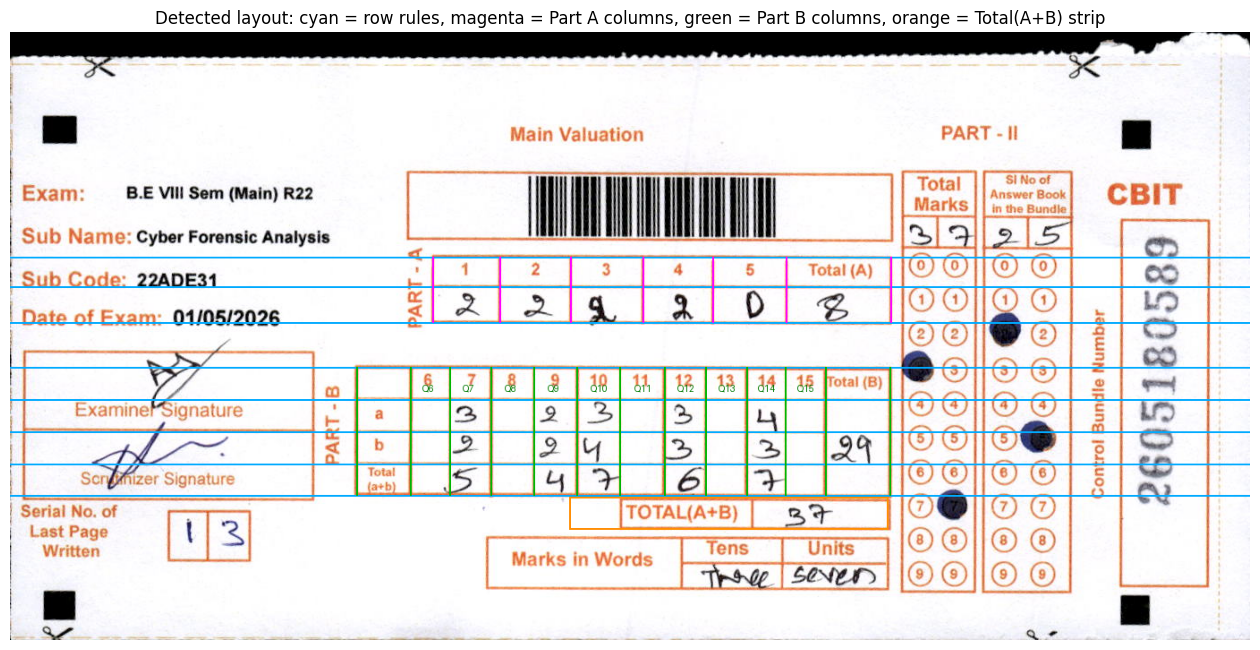

Part A row rules: [252, 285, 325] | boundaries: [472, 547, 626, 707, 785, 867, 984]
Part B row rules: [375, 411, 447, 483, 518] | boundaries: [387, 447, 491, 537, 585, 633, 681, 731, 777, 823, 866, 911, 983]
Total(A+B) strip: (625, 520, 981, 556)


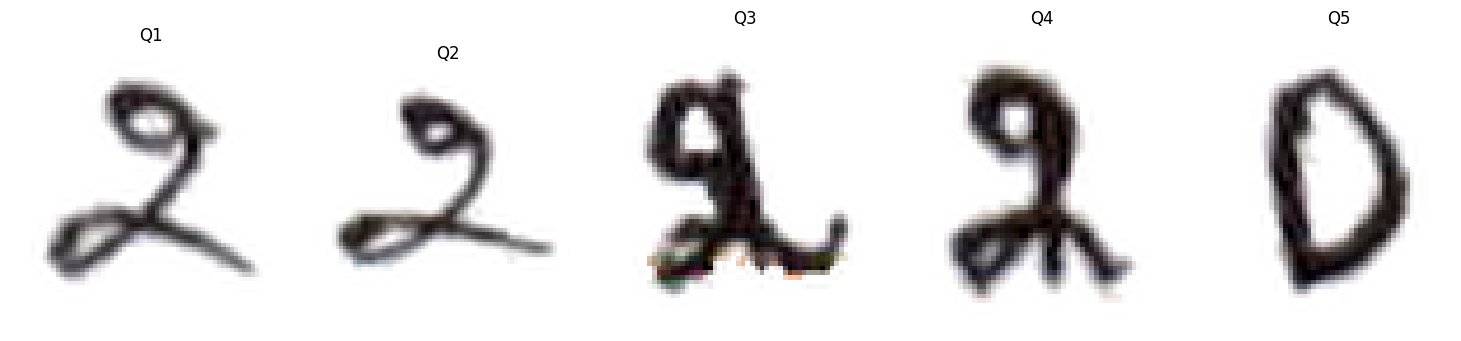

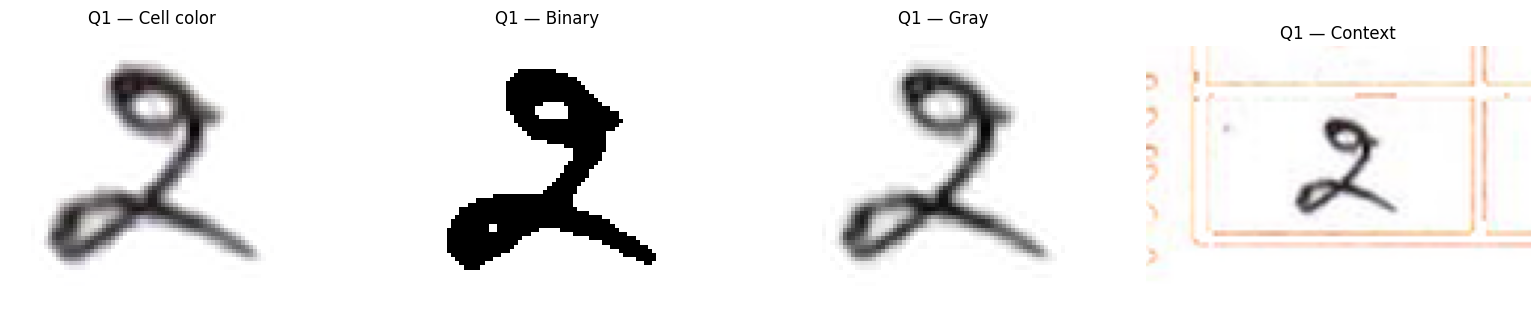

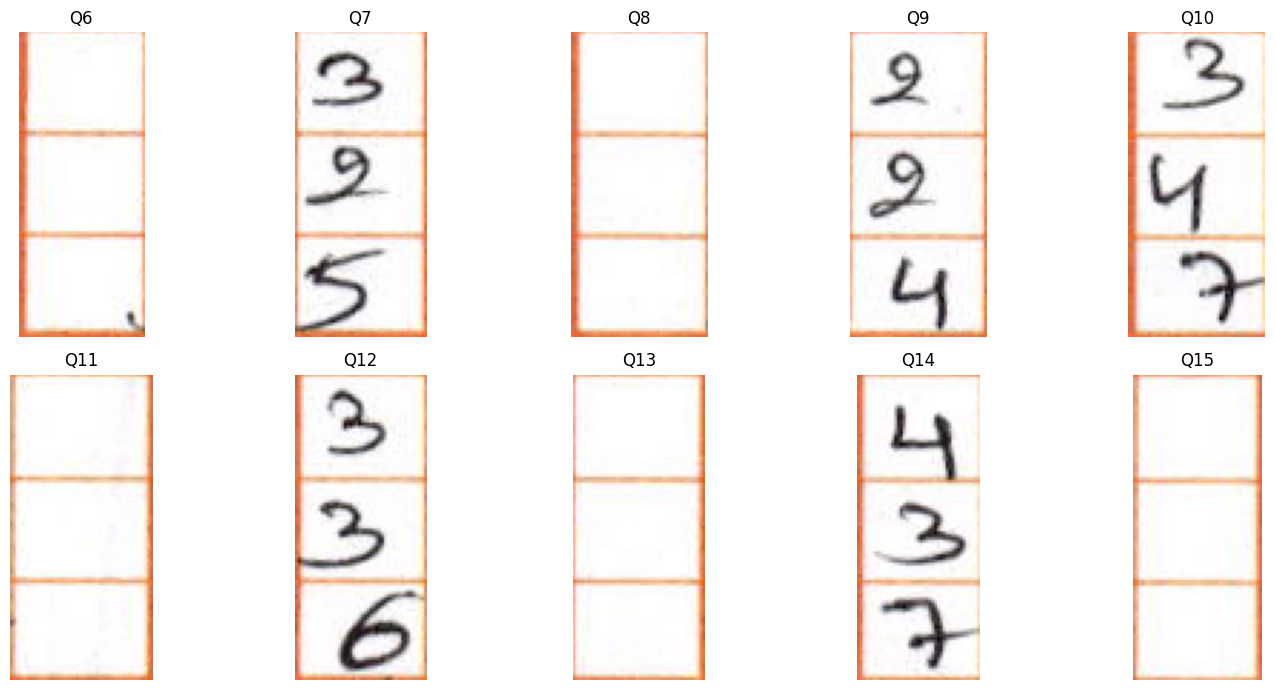

Q6 processed views:


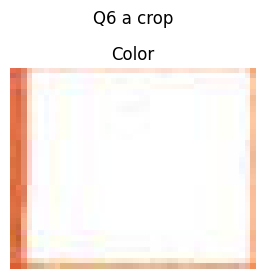

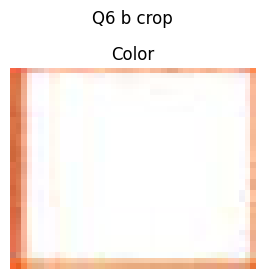

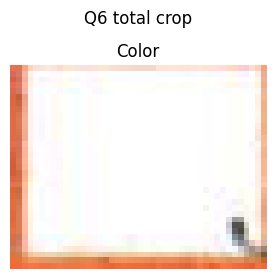

Total Marks: 37 | SI No: 25
Bubble diagnostics: {'digits': [3, 7, 2, 5], 'scores': [1.0, 1.0, 1.0, 1.0], 'total_marked': 37, 'si_marked': 25, 'notes': []}


In [5]:
# 4. REQUIRED: inspect dynamic alignment and crops BEFORE loading OCR models
import matplotlib.pyplot as plt
from PIL import ImageDraw

def inspect_sheet(path: str):
    im = load_image(path)
    print("Image after width normalization:", im.size)
    try:
        analysis = analyze_sheet(im)
    except ValueError as exc:
        print("DYNAMIC CALIBRATION FAILED:", exc)
        plt.figure(figsize=(14, 7))
        plt.imshow(im)
        plt.axis("off")
        plt.title("Full image - printed grid detection failed")
        plt.show()
        raise

    arr = analysis["arr"]
    det = analysis["det"]
    views = analysis["views"]
    A, B = det["A"], det["B"]

    # Overlay detected rules and vertical boundaries. These lines are diagnostic only.
    overlay = Image.fromarray(arr.copy())
    draw = ImageDraw.Draw(overlay)
    for y in A["hlines"]:
        draw.line((0, y, overlay.width - 1, y), fill=(0, 170, 255), width=2)
    for y in B["hlines"]:
        draw.line((0, y, overlay.width - 1, y), fill=(0, 170, 255), width=2)
    for x in A["v"]:
        draw.line((x, A["hlines"][0], x, A["hlines"][-1]), fill=(255, 0, 255), width=2)
    for x in B["v"]:
        draw.line((x, B["hlines"][0], x, B["hlines"][-1]), fill=(0, 180, 0), width=2)
    tx0, ty0, tx1, ty1 = det["totalab"]
    draw.rectangle((tx0, ty0, tx1, ty1), outline=(255, 140, 0), width=2)
    for i in range(10):
        if i + 2 < len(B["v"]):
            cx = (B["v"][i + 1] + B["v"][i + 2]) // 2
            draw.text((cx - 8, max(0, B["hlines"][1] - 18)), f"Q{i + 6}",
                      fill=(0, 120, 0))
    plt.figure(figsize=(16, 8))
    plt.imshow(overlay)
    plt.axis("off")
    plt.title("Detected layout: cyan = row rules, magenta = Part A columns, "
              "green = Part B columns, orange = Total(A+B) strip")
    plt.show()

    print("Part A row rules:", A["hlines"], "| boundaries:", A["v"])
    print("Part B row rules:", B["hlines"], "| boundaries:", B["v"])
    print("Total(A+B) strip:", det["totalab"])

    def cell_image(key):
        entry = views.get(key) or {}
        image = entry.get("color")
        if image is not None:
            return image
        cell = entry.get("cell")
        if not cell:
            return np.full((60, 80, 3), 255, np.uint8)
        x1, y1, x2, y2 = cell["x1"], cell["y1"], cell["x2"], cell["y2"]
        return arr[max(0, y1):max(1, y2), max(0, x1):max(1, x2)]

    # Part A question crops.
    part_a = [f"Q{i}" for i in range(1, 6)]
    fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
    for i, (ax, key) in enumerate(zip(axes, part_a)):
        ax.imshow(cell_image(key))
        ax.axis("off")
        ax.set_title(key)
    plt.tight_layout()
    plt.show()

    # Visual contrast check for the first Part A cell that contains ink.
    sample_key = next((key for key in part_a
                       if (views.get(key) or {}).get("has_ink")), part_a[0])
    sample_views = (views.get(sample_key) or {}).get("views") or {}
    contrast = [("Cell color", cell_image(sample_key))]
    for label, view_key in (("Binary", "binary"), ("Gray", "gray"),
                            ("Context", "context"), ("Expanded", "expanded")):
        view = sample_views.get(view_key)
        if view is not None:
            contrast.append((label, view))
    fig, axes = plt.subplots(1, len(contrast), figsize=(4 * len(contrast), 3.2))
    if len(contrast) == 1:
        axes = [axes]
    for ax, (label, image) in zip(axes, contrast):
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(f"{sample_key} — {label}")
    plt.tight_layout()
    plt.show()

    # Complete Part B question crops (a + b + total rows together).
    fig, axes = plt.subplots(2, 5, figsize=(15, 7))
    for i, ax in enumerate(axes.ravel()):
        if i >= 10:
            break
        x1, x2 = B["v"][i + 1], B["v"][i + 2]
        y1, y2 = B["hlines"][1], B["hlines"][4]
        ax.imshow(arr[max(0, y1):max(1, y2), max(0, x1):max(1, x2)])
        ax.axis("off")
        ax.set_title(f"Q{i + 6}")
    plt.tight_layout()
    plt.show()

    # Show the processed views for Q6 as a representative Part B cell.
    print("Q6 processed views:")
    for field in ("Q6_a", "Q6_b", "Q6_total"):
        entry = views.get(field) or {}
        entry_views = entry.get("views") or {}
        selected = [("Color", cell_image(field))]
        for label, view_key in (("Binary", "binary"), ("Gray", "gray"),
                                ("Context", "context"), ("Tall", "tall")):
            view = entry_views.get(view_key)
            if view is not None:
                selected.append((label, view))
        fig, axes = plt.subplots(1, len(selected), figsize=(3.2 * len(selected), 2.8))
        if len(selected) == 1:
            axes = [axes]
        for ax, (label, image) in zip(axes, selected):
            ax.imshow(image)
            ax.axis("off")
            ax.set_title(label)
        fig.suptitle(f"Q6 {field.split('_')[-1]} crop")
        plt.tight_layout()
        plt.show()

    print("Total Marks:", analysis["total_marks"],
          "| SI No:", analysis["si_no"])
    print("Bubble diagnostics:", analysis["bubbles"])

SAMPLE = str(image_files[0])
print("Inspecting:", SAMPLE)
inspect_sheet(SAMPLE)


### Check the dynamic calibration before running OCR

The overlay should place a boundary around each question column. The cyan lines are detected row rules, magenta lines are Part A columns, and green lines are Part B question columns. The individual crops include a small amount of padding around each printed cell so oversized handwriting is not clipped; the OCR preprocessing removes orange/red form lines.

If the overlay is misaligned on the first sheet, stop and inspect a few more sheets before running the full 49 GB folder. The first detected file is selected automatically; you can set `SAMPLE = str(image_files[index])` to inspect another image.


In [6]:
# 5. Load a two-stage PaddleOCR pipeline: Mobile first, Server fallback for uncertain cells
import time, os, gc
import paddle
from paddleocr import TextRecognition

# Colab: select Runtime > Change runtime type > T4 GPU (if available) for faster server fallback.
# PaddleOCR accepts device="gpu:0" or "cpu". If GPU is unavailable, use CPU.
try:
    HAS_GPU = bool(paddle.is_compiled_with_cuda() and paddle.device.cuda.device_count() > 0)
except Exception:
    HAS_GPU = False
DEVICE = "gpu:0" if HAS_GPU else "cpu"
paddle.set_device(DEVICE)

MOBILE_MODEL = "PP-OCRv5_mobile_rec"
SERVER_MODEL = "PP-OCRv5_server_rec"
print(f"Primary: {MOBILE_MODEL} | fallback: {SERVER_MODEL} | device: {DEVICE}")
if not HAS_GPU:
    print("WARNING: Paddle is using CPU. Processing may be much slower on a large collection.")
print("Server fallback is used when views disagree, cannot be parsed, or Part-B arithmetic is inconsistent.")
t0 = time.time()
recognizer = TextRecognition(model_name=MOBILE_MODEL, device=DEVICE)
server_recognizer = TextRecognition(model_name=SERVER_MODEL, device=DEVICE)
loaded = LoadedModel(recognizer, None, DEVICE, fallback_model=server_recognizer)
print(f"Both recognizers ready in {time.time()-t0:.1f}s")

# Smoke test (synthetic printed digit only checks model execution, not handwriting accuracy)
from PIL import Image, ImageDraw, ImageFont
test_img = Image.new("RGB", (180, 80), "white")
try:
    font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 56)
except Exception:
    font = ImageFont.load_default()
ImageDraw.Draw(test_img).text((55, 5), "7", fill=(20, 40, 180), font=font)
t0 = time.time()
print("Mobile smoke test:", repr(paddle_recognize(loaded, test_img)))
print("Server smoke test:", repr(paddle_recognize(loaded, test_img, use_fallback=True)))
print(f"Smoke tests took {time.time()-t0:.2f}s")


Checking connectivity to the model hosters, this may take a while. To bypass this check, set `PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK` to `True`.


Primary: PP-OCRv5_mobile_rec | fallback: PP-OCRv5_server_rec | device: cpu
Server fallback is used when views disagree, cannot be parsed, or Part-B arithmetic is inconsistent.


Using official model (PP-OCRv5_mobile_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv5_mobile_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Using official model (PP-OCRv5_server_rec), the model files will be automatically downloaded and saved in `/root/.paddlex/official_models/PP-OCRv5_server_rec`.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Both recognizers ready in 13.3s
Mobile smoke test: ''
Server smoke test: 'E'
Smoke tests took 0.62s


In [7]:
# 6. Pilot run on up to 5 sheets with per-view method diagnostics (does not modify source files)
import json, time

pilot_paths = image_files[:5]
print("Pilot images:")
for p in pilot_paths:
    print(" -", p.relative_to(DRIVE_FOLDER))
t0 = time.time()
pilot = []
for path in pilot_paths:
    try:
        rec = extract_record(loaded, str(path))
        rec.setdefault("path", str(path))
        pilot.append(rec)
    except Exception as exc:
        pilot.append({"file": path.name, "path": str(path), "answers": {}, "totals": {},
                      "repairs": [], "diagnostics": {}, "flags": [f"ERROR: {exc}"],
                      "crosscheck_flags": [], "valid": False})
print(f"Pilot time: {time.time()-t0:.1f}s")
for r in pilot:
    print("\nFILE:", r['file'], "| PATH:", r.get('path'))
    print("ANSWERS:", json.dumps(r.get('answers', {}), sort_keys=True))
    print("TOTALS:", json.dumps(r.get('totals', {}), sort_keys=True))
    # Show the raw recognition from each Part-A view and first/second-pass readings.
    for q, d in r.get("diagnostics", {}).get("part_a", {}).items():
        if not isinstance(d, dict): continue
        first = d.get("first") or {}
        second = d.get("second") or {}
        if first or second:
            print(f"  {q}: selected={d.get('value')} first_views={json.dumps(first.get('per_view', []), ensure_ascii=False)} second_views={json.dumps(second.get('per_view', []), ensure_ascii=False)}")
    for q, d in r.get("diagnostics", {}).get("part_b", {}).items():
        if not isinstance(d, dict): continue
        first, second = d.get("first") or {}, d.get("second") or {}
        if first or second:
            print(f"  {q}: first={json.dumps(first.get('per_row', []), ensure_ascii=False)} second={json.dumps(second.get('per_row', []), ensure_ascii=False)}")
    print("STATUS:", "OK" if r.get('valid') else "REVIEW")
    if r.get('flags'): print("FLAGS:", r['flags'])


Pilot images:
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751485.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751539.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE16__750272.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE16__750303.jpg
 - BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22BTE16__750305.jpg
Pilot time: 68.0s

FILE: BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751485.jpg | PATH: /content/drive/MyDrive/Random_Images_Sample/BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22ADE31__751485.jpg
ANSWERS: {"Q1": 2, "Q10_a": 3, "Q10_b": 4, "Q10_inked": true, "Q10_single": false, "Q10_total": 7, "Q10_total_read": 7, "Q11_a": null, "Q11_b": null, "Q11_single": false, "Q11_total": null, "Q11_total_read": null, "Q12_a": 3, "Q12_b": 3, "Q12_inked": true, "Q12_single": false, "Q12_total": 6, "Q12_total_read": 6, "Q13_a": null, "Q13_b": null, "Q13_single": false, "Q13_total": null, "Q13_total_read": n

In [8]:
# 6b. Optional: visualize detected bubble centers on pilot sheets (especially low-confidence/fallback grids)
import matplotlib.pyplot as plt
from PIL import ImageDraw
import numpy as np

def show_bubble_overlay(path):
    image = load_image(path)
    total_value, total_conf, total_diag = read_bubbles(image, "total")
    si_value, si_conf, si_diag = read_bubbles(image, "si")
    overlay = image.copy()
    draw = ImageDraw.Draw(overlay)
    for label, diag, color in (
        ("TOTAL", total_diag, (0, 150, 255)),
        ("SI", si_diag, (220, 0, 180)),
    ):
        centers = diag.get("centers", {})
        xs, ys, rs = centers.get("xs", []), centers.get("ys", []), centers.get("radii", [])
        cols = (0, 1) if label == "TOTAL" else (2, 3)
        for col in cols:
            if col >= len(xs):
                continue
            for row_idx, yy in enumerate(ys):
                rr = rs[row_idx] if row_idx < len(rs) else 10
                x = xs[col]
                draw.ellipse((x-rr, yy-rr, x+rr, yy+rr), outline=color, width=2)
                if row_idx in (0, 1, 2, 3, 4, 5, 6, 7, 8, 9):
                    draw.text((x-4, yy-5), str(row_idx), fill=color)
    plt.figure(figsize=(14, 7))
    plt.imshow(overlay)
    plt.axis("off")
    plt.title(
        f"{Path(path).name} | Total bubbles={total_value} (conf={total_conf:.3f}, grid={total_diag.get('grid_method')}) "
        f"| SI={si_value} (conf={si_conf:.3f}, grid={si_diag.get('grid_method')})"
    )
    plt.show()

# Uncomment to inspect a pilot image, e.g. one where SI confidence was low:
# show_bubble_overlay(pilot_paths[4])


In [9]:
# 7. Excel writer used after each image-containing folder finishes
from collections import defaultdict
import re

def write_excel(records: List[Dict], output_path: str, title: str = "Mark Sheet OCR Results"):
    wb = openpyxl.Workbook()
    summary_ws = wb.active
    summary_ws.title = "Summary"

    HEADER_FILL = PatternFill("solid", fgColor="1F4E78")
    HEADER_FONT = Font(name="Arial", bold=True, size=10, color="FFFFFF")
    OK_FILL = PatternFill("solid", fgColor="E2F0D9")
    FLAG_FILL = PatternFill("solid", fgColor="FFC7CE")
    WARN_FILL = PatternFill("solid", fgColor="FFF2CC")
    BORDER = Border(*([Side(style="thin", color="999999")] * 4))
    CENTER = Alignment(horizontal="center", vertical="center", wrap_text=True)
    NORMAL = Font(name="Arial", size=10)
    BOLD = Font(name="Arial", bold=True, size=10)

    cols = ["S.No", "Answer Book SI No", "Source File", "Source Relative Path"] + [f"Q{i}" for i in range(1, 6)]
    for i in range(6, 16): cols += [f"Q{i}(a)", f"Q{i}(b)", f"Q{i} Total (computed)", f"Q{i} Total (written)"]
    cols += ["Total(A)", "Total(B)", "Grand Total", "Total Marks (bubbles)",
             "Handwritten TOTAL(A+B)", "Counted Part-B Qs", "Alternative Selection Notes", "Status", "Cross-checks", "Warnings", "Repairs"]

    def source_relative_path(rec):
        raw_path = rec.get("path", "")
        if not raw_path:
            return rec.get("file", "")
        try:
            return str(Path(raw_path).relative_to(DRIVE_FOLDER))
        except Exception:
            return str(raw_path)

    def source_folder_key(rec):
        raw_path = rec.get("path", "")
        try:
            parent = Path(raw_path).parent.relative_to(DRIVE_FOLDER).as_posix()
            return "(images directly in root)" if parent in (".", "") else parent
        except Exception:
            return "(source folder unavailable)"

    def values_for(rec, serial):
        a = rec.get("answers", {})
        t = rec.get("totals", {})
        vals = [serial, t.get("ANSWER_BOOK_SI_NO"), rec.get("file"), source_relative_path(rec)]
        vals += [a.get(f"Q{i}") for i in range(1, 6)]
        for i in range(6, 16): vals += [a.get(f"Q{i}_a"), a.get(f"Q{i}_b"), a.get(f"Q{i}_total"), a.get(f"Q{i}_total_read")]
        vals += [t.get("TOTAL_A"), t.get("TOTAL_B"), t.get("GRAND_TOTAL_COMPUTED"),
                 t.get("PRINTED_TOTAL_MARKS"), t.get("TOTAL_AB_HANDWRITTEN"),
                 ", ".join(rec.get("counted", [])), "; ".join(rec.get("selection_notes", [])),
                 "OK" if rec.get("valid") else "REVIEW",
                 "; ".join(rec.get("crosscheck_flags", [])), "; ".join(rec.get("warnings", [])),
                 "; ".join(rec.get("repairs", []))]
        return vals

    widths = [6, 15, 28, 55] + [6] * 5 + [7, 7, 12, 12] * 10 + [10, 10, 12, 16, 18, 22, 65, 12, 65, 65, 80]

    def style_header_row(ws, row_num, headers):
        for c, h in enumerate(headers, 1):
            cell = ws.cell(row_num, c, h)
            cell.font = HEADER_FONT
            cell.fill = HEADER_FILL
            cell.alignment = CENTER
            cell.border = BORDER

    def write_results_sheet(ws, sheet_records, sheet_title):
        ws.merge_cells(start_row=1, start_column=1, end_row=1, end_column=len(cols))
        ws["A1"] = sheet_title
        ws["A1"].font = Font(name="Arial", bold=True, size=14)
        ws["A1"].alignment = CENTER
        style_header_row(ws, 3, cols)
        for ridx, rec in enumerate(sheet_records, 4):
            vals = values_for(rec, ridx - 3)
            for c, value in enumerate(vals, 1):
                cell = ws.cell(ridx, c, value)
                cell.alignment = CENTER
                cell.border = BORDER
                cell.font = BOLD if cols[c-1] in {"Total(A)", "Total(B)", "Grand Total"} else NORMAL
                if cols[c-1] == "Status":
                    cell.fill = OK_FILL if rec.get("valid") else FLAG_FILL
                if cols[c-1] in {"Cross-checks", "Warnings"} and value:
                    cell.fill = WARN_FILL
        for i, width in enumerate(widths, 1):
            ws.column_dimensions[get_column_letter(i)].width = width
        ws.freeze_panes = "D4"
        if sheet_records:
            ws.auto_filter.ref = f"A3:{get_column_letter(len(cols))}{len(sheet_records)+3}"

    # Group on the directory that directly contains each image (i.e., every leaf/image folder).
    groups = defaultdict(list)
    for rec in records:
        groups[source_folder_key(rec)].append(rec)
    for key in groups:
        groups[key].sort(key=lambda r: source_relative_path(r).lower())
    sorted_folder_keys = sorted(groups.keys(), key=lambda x: x.lower())

    # Sheet names must be <=31 chars, exclude Excel-reserved characters, and be unique.
    sheet_name_for_folder = {}
    used_names = {"Summary", "All Results", "Review Needed", "OCR Diagnostics", "Field Audit"}
    for idx, folder_key in enumerate(sorted_folder_keys, 1):
        leaf = "Root Images" if folder_key == "(images directly in root)" else Path(folder_key).name
        base = re.sub(r'[\\/*?:\[\]]', "_", f"F{idx:03d} - {leaf}").strip("' ")
        base = base[:31] or f"Folder {idx}"
        candidate = base
        suffix = 2
        while candidate in used_names:
            tail = f"_{suffix}"
            candidate = base[:31-len(tail)] + tail
            suffix += 1
        used_names.add(candidate)
        sheet_name_for_folder[folder_key] = candidate

    # Summary sheet: concise overview and a map from source folders to worksheet names.
    summary_ws.merge_cells("A1:E1")
    summary_ws["A1"] = title
    summary_ws["A1"].font = Font(name="Arial", bold=True, size=15)
    summary_ws["A1"].alignment = CENTER
    total_count = len(records)
    passed = sum(bool(r.get("valid")) for r in records)
    summary_ws.cell(3, 1, "Metric")
    summary_ws.cell(3, 2, "Value")
    style_header_row(summary_ws, 3, ["Metric", "Value"])
    summary_ws.cell(4, 1, "Images processed"); summary_ws.cell(4, 2, total_count)
    summary_ws.cell(5, 1, "Passed validation"); summary_ws.cell(5, 2, passed)
    summary_ws.cell(6, 1, "Needs review"); summary_ws.cell(6, 2, total_count - passed)
    summary_ws.cell(7, 1, "Image-containing source folders"); summary_ws.cell(7, 2, len(groups))
    folder_header_row = 9
    folder_headers = ["Worksheet", "Source folder (relative to Drive root)", "Images processed", "Passed", "Needs review"]
    style_header_row(summary_ws, folder_header_row, folder_headers)
    for folder_idx, folder_key in enumerate(sorted_folder_keys, folder_header_row + 1):
        folder_records = groups[folder_key]
        folder_pass = sum(bool(r.get("valid")) for r in folder_records)
        for col_idx, value in enumerate([sheet_name_for_folder[folder_key], folder_key, len(folder_records),
                                         folder_pass, len(folder_records)-folder_pass], 1):
            summary_ws.cell(folder_idx, col_idx, value)
    summary_ws.column_dimensions["A"].width = 31
    summary_ws.column_dimensions["B"].width = 65
    summary_ws.column_dimensions["C"].width = 20
    summary_ws.column_dimensions["D"].width = 14
    summary_ws.column_dimensions["E"].width = 16
    summary_ws.freeze_panes = "A10"
    summary_ws.auto_filter.ref = f"A{folder_header_row}:E{max(folder_header_row, folder_header_row + len(sorted_folder_keys))}"
    for row in summary_ws.iter_rows():
        for cell in row:
            if cell.value is not None:
                cell.alignment = Alignment(vertical="center", wrap_text=True)
                if cell.row not in (1, 3, folder_header_row): cell.border = BORDER

    # Combined master sheet.
    all_ws = wb.create_sheet("All Results")
    write_results_sheet(all_ws, records, title + " — All Folders")

    # One worksheet for every source folder that contains images.
    for folder_key in sorted_folder_keys:
        ws = wb.create_sheet(sheet_name_for_folder[folder_key])
        write_results_sheet(ws, groups[folder_key], f"Results — {folder_key}")

    # Human-review queue.
    ws2 = wb.create_sheet("Review Needed")
    review_headers = ["Source File", "Source Relative Path", "Answer Book SI No", "Reasons", "Repairs", "Cross-checks", "Warnings"]
    style_header_row(ws2, 1, review_headers)
    for rec in records:
        if not rec.get("valid"):
            ws2.append([rec.get("file"), source_relative_path(rec), rec.get("totals", {}).get("ANSWER_BOOK_SI_NO"),
                        "; ".join(rec.get("flags", [])), "; ".join(rec.get("repairs", [])),
                        "; ".join(rec.get("crosscheck_flags", [])), "; ".join(rec.get("warnings", []))])
    for col, width in zip("ABCDEFG", [30, 55, 18, 90, 90, 90, 90]):
        ws2.column_dimensions[col].width = width
    ws2.freeze_panes = "A2"
    if ws2.max_row >= 2: ws2.auto_filter.ref = f"A1:G{ws2.max_row}"

    # OCR diagnostics retained so uncertain readings can be audited.
    ws3 = wb.create_sheet("OCR Diagnostics")
    diag_headers = ["Source File", "Source Relative Path", "Question", "First Raw", "Second Raw", "Read a", "Read b", "Read total"]
    style_header_row(ws3, 1, diag_headers)
    for rec in records:
        for q, d in rec.get("diagnostics", {}).get("part_b", {}).items():
            if not isinstance(d, dict): continue
            second = d.get("second", {})
            ws3.append([rec.get("file"), source_relative_path(rec), q, d.get("raw", ""),
                        second.get("raw", "") if isinstance(second, dict) else "",
                        rec.get("answers", {}).get(f"{q}_a"), rec.get("answers", {}).get(f"{q}_b"),
                        rec.get("answers", {}).get(f"{q}_total_read")])
    for col, width in zip("ABCDEFGH", [30, 55, 10, 60, 60, 8, 8, 12]):
        ws3.column_dimensions[col].width = width
    ws3.freeze_panes = "A2"
    if ws3.max_row >= 2: ws3.auto_filter.ref = f"A1:H{ws3.max_row}"


    # Field-level audit: retain raw Mobile/Server readings and explicitly separate blanks from unreadable fields.
    audit_ws = wb.create_sheet("Field Audit")
    audit_headers = [
        "Source File", "Source Relative Path", "Question", "Field",
        "First Mobile Raw", "First Server Raw", "Second Mobile Raw", "Second Server Raw",
        "Selected Value", "Status", "Recognizer Disagreement", "Computed Total", "Written Total"
    ]
    style_header_row(audit_ws, 1, audit_headers)

    def row_for_field(attempt, field):
        if not isinstance(attempt, dict):
            return {}
        for item in attempt.get("per_row", []):
            if isinstance(item, dict) and item.get("field") == field:
                return item
        return {}

    def raw_views(attempt, model_key):
        if not isinstance(attempt, dict):
            return ""
        per_view = attempt.get("per_view", [])
        if per_view:
            return " | ".join(str(x.get(model_key) or "") for x in per_view if isinstance(x, dict))
        return ""

    for rec in records:
        path_value = source_relative_path(rec)
        ans = rec.get("answers", {})
        diags = rec.get("diagnostics", {})
        for q in PART_A_QUESTIONS:
            d = diags.get("part_a", {}).get(q, {})
            first, second = d.get("first") or {}, d.get("second") or {}
            selected = ans.get(q)
            if d.get("raw") == "BLANK_PRECHECK":
                status = "blank scored as 0"
            elif selected is None:
                status = "unreadable"
            elif first.get("recognizer_disagreement"):
                status = "Mobile/Server conflict; Server preferred"
            elif first.get("value") is not None and second.get("value") is not None and first.get("value") != second.get("value"):
                status = "pass conflict; first retained"
            else:
                status = "read"
            audit_ws.append([
                rec.get("file"), path_value, q, "mark",
                raw_views(first, "mobile_raw"),
                raw_views(first, "server_raw"),
                raw_views(second, "mobile_raw"),
                raw_views(second, "server_raw"),
                selected, status, status.startswith("pass conflict"),
                None, None
            ])

        for q in PART_B_QUESTIONS:
            d = diags.get("part_b", {}).get(q, {})
            first, second = d.get("first") or {}, d.get("second") or {}
            for field, answer_key in (("a", f"{q}_a"), ("b", f"{q}_b"), ("total", f"{q}_total_read")):
                fr = row_for_field(first, field)
                sr = row_for_field(second, field)
                selected = ans.get(answer_key)
                if ans.get(f"{q}_single") and field in ("a", "b"):
                    status = "not used (single 10-mark question)"
                elif d.get("raw") == "BLANK_PRECHECK":
                    status = "blank scored as 0"
                elif not fr.get("has_ink", True) and not sr.get("has_ink", False):
                    status = "blank scored as 0"
                elif selected is None:
                    status = "unreadable"
                elif (fr.get("mobile_value") is not None and fr.get("server_value") is not None
                      and fr.get("mobile_value") != fr.get("server_value")):
                    status = "Mobile/Server conflict; Server preferred"
                elif (fr.get("selected_value") is not None and sr.get("selected_value") is not None
                      and fr.get("selected_value") != sr.get("selected_value")):
                    status = "first/second conflict; first retained"
                else:
                    status = "read"
                disagreement = bool(fr.get("recognizer_disagreement") or sr.get("recognizer_disagreement")
                                    or status.endswith("conflict; first retained"))
                audit_ws.append([
                    rec.get("file"), path_value, q, field,
                    fr.get("mobile_raw", ""), fr.get("server_raw", ""),
                    sr.get("mobile_raw", ""), sr.get("server_raw", ""),
                    selected, status, disagreement,
                    ans.get(f"{q}_total") if field != "total" else None,
                    ans.get(f"{q}_total_read") if field == "total" else None
                ])

    for col, width in zip("ABCDEFGHIJKLM", [30, 55, 12, 10, 22, 22, 22, 22, 14, 34, 20, 15, 15]):
        audit_ws.column_dimensions[col].width = width
    audit_ws.freeze_panes = "A2"
    if audit_ws.max_row >= 2:
        audit_ws.auto_filter.ref = f"A1:M{audit_ws.max_row}"

    wb.save(output_path)
    print(f"Created workbook with {len(groups)} source-folder worksheet(s): {output_path}")
    print(f"Processed={total_count:,} | passed={passed:,} | review={total_count-passed:,}")


In [10]:
# 8. Resumable full-batch OCR from Google Drive, with one Excel report per folder
# Completed sheets are checkpointed to Drive. This versioned checkpoint starts fresh for v23 single-10-mark scoring; later reruns resume it.
# The input is Main / six folders / inner image folders. Each innermost image folder gets its own workbook as soon as it finishes.
import json, os, time
from pathlib import Path

CHECKPOINT_PATH = OUTPUT_DIR / "ocr_checkpoint_pilotfix_v25_audit.jsonl"
RESET_CHECKPOINT = False  # set True ONCE if you need to discard old results and rerun every sheet
FORCE_REBUILD_FOLDER_REPORTS = False  # set True to rewrite reports even when they already exist
if RESET_CHECKPOINT and CHECKPOINT_PATH.exists():
    CHECKPOINT_PATH.unlink()

FOLDER_REPORT_ROOT = OUTPUT_DIR
FOLDER_REPORT_ROOT.mkdir(parents=True, exist_ok=True)
print("Per-folder Excel reports are saved under:", FOLDER_REPORT_ROOT)

records_by_path = {}
if CHECKPOINT_PATH.exists():
    with CHECKPOINT_PATH.open("r", encoding="utf-8") as f:
        for line in f:
            try:
                item = json.loads(line)
                if item.get("path"):
                    records_by_path[item["path"]] = item
            except json.JSONDecodeError:
                # Ignore only an incomplete last line from an interrupted write.
                continue
print(f"Found {len(records_by_path):,} previously checkpointed sheet(s).")
print(f"Images to process: {len(image_files):,} | input: {DRIVE_FOLDER}")
print("Checkpoint:", CHECKPOINT_PATH)


def source_folder_key_for_path(path: Path) -> str:
    """Innermost image-containing folder, relative to DRIVE_FOLDER."""
    parent = path.relative_to(DRIVE_FOLDER).parent.as_posix()
    return "(images directly in root)" if parent in (".", "") else parent


def folder_report_path(folder_key: str) -> Path:
    """Save as OCR_Results/<top-level>/<inner-folder>.xlsx."""
    if folder_key == "(images directly in root)":
        return FOLDER_REPORT_ROOT / "_root_images.xlsx"
    relative_dir = Path(folder_key)
    if relative_dir.parent.as_posix() in (".", ""):
        # Images directly inside one of the six top-level folders.
        return FOLDER_REPORT_ROOT / f"{relative_dir.name}.xlsx"
    return FOLDER_REPORT_ROOT / relative_dir.parent / f"{relative_dir.name}.xlsx"


# Group in path order so each innermost image folder is processed as one contiguous unit.
folders = {}
for path in image_files:
    folders.setdefault(source_folder_key_for_path(path), []).append(path)
folder_keys = sorted(folders, key=lambda value: value.lower())
print(f"Image-containing folders: {len(folder_keys):,}")

t0 = time.time()
new_count = 0
with CHECKPOINT_PATH.open("a", encoding="utf-8") as checkpoint_file:
    for folder_index, folder_key in enumerate(folder_keys, 1):
        folder_paths = folders[folder_key]
        folder_new = 0

        for path in folder_paths:
            path_key = str(path)
            if path_key in records_by_path:
                continue
            try:
                rec = extract_record(loaded, path_key)
                rec.setdefault("path", path_key)
            except Exception as exc:
                rec = {"file": path.name, "path": path_key, "answers": {}, "totals": {},
                       "repairs": [], "diagnostics": {}, "flags": [f"ERROR: {exc}"],
                       "crosscheck_flags": [], "valid": False}
            records_by_path[path_key] = rec
            checkpoint_file.write(json.dumps(rec, ensure_ascii=False, default=str) + "\n")
            new_count += 1
            folder_new += 1
            if new_count % 10 == 0:
                checkpoint_file.flush()
                os.fsync(checkpoint_file.fileno())
                print(f"Checkpointed {len(records_by_path):,}/{len(image_files):,} sheets...")

        # Persist the folder's checkpoint records before creating its report.
        checkpoint_file.flush()
        os.fsync(checkpoint_file.fileno())

        folder_records = [records_by_path[str(path)] for path in folder_paths
                          if str(path) in records_by_path]
        report_path = folder_report_path(folder_key)

        try:
            report_path.parent.mkdir(parents=True, exist_ok=True)
            if report_path.exists() and not FORCE_REBUILD_FOLDER_REPORTS and folder_new == 0:
                report_status = "already exists"
            else:
                write_excel(folder_records, str(report_path),
                            title=f"Mark Sheet OCR Results — {folder_key}")
                report_status = "written"
            print(f"[folder {folder_index}/{len(folder_keys)}] {folder_key}: "
                  f"{len(folder_records):,} sheet(s), newly processed {folder_new:,}; "
                  f"report {report_status} -> {report_path}", flush=True)
        except Exception as exc:
            # A report failure must not stop the OCR run or lose checkpoint progress.
            print(f"[folder {folder_index}/{len(folder_keys)}] {folder_key}: "
                  f"report FAILED: {exc}", flush=True)

    checkpoint_file.flush()
    os.fsync(checkpoint_file.fileno())

records = list(records_by_path.values())
records.sort(key=lambda r: (r.get("totals", {}).get("ANSWER_BOOK_SI_NO") is None,
                            r.get("totals", {}).get("ANSWER_BOOK_SI_NO") or 0,
                            r.get("file", ""), r.get("path", "")))
elapsed = time.time() - t0
ok = sum(1 for r in records if r.get("valid"))
print(f"Processed/resumed {len(records):,} sheet(s); newly processed {new_count:,} in {elapsed/60:.1f} min")
print(f"Passed validation: {ok} / {len(records)}")
print(f"Needs review: {len(records)-ok} / {len(records)}")
print("Per-folder workbooks follow the source hierarchy under:", FOLDER_REPORT_ROOT)
print("If Colab disconnects, reconnect and rerun this cell; completed folders and sheets resume from the checkpoint.")


Per-folder Excel reports are saved under: /content/drive/MyDrive/Random_Images_Sample/OCR_Results_red
Found 0 previously checkpointed sheet(s).
Images to process: 185 | input: /content/drive/MyDrive/Random_Images_Sample
Checkpoint: /content/drive/MyDrive/Random_Images_Sample/OCR_Results_red/ocr_checkpoint_pilotfix_v25_audit.jsonl
Image-containing folders: 1
Checkpointed 10/185 sheets...
Checkpointed 20/185 sheets...
Checkpointed 30/185 sheets...
Checkpointed 40/185 sheets...
Checkpointed 50/185 sheets...
Checkpointed 60/185 sheets...
Checkpointed 70/185 sheets...
Checkpointed 80/185 sheets...
Checkpointed 90/185 sheets...
Checkpointed 100/185 sheets...
Checkpointed 110/185 sheets...
Checkpointed 120/185 sheets...
Checkpointed 130/185 sheets...
Checkpointed 140/185 sheets...
Checkpointed 150/185 sheets...
Checkpointed 160/185 sheets...
Checkpointed 170/185 sheets...
Checkpointed 180/185 sheets...
Created workbook with 1 source-folder worksheet(s): /content/drive/MyDrive/Random_Images_Sa

In [11]:
# 9. Optional: one combined workbook for all folders
# The per-folder workbooks are already written by cell 8. Leave this False for the 15,000-sheet run.
BUILD_FINAL_COMBINED_WORKBOOK = False

if BUILD_FINAL_COMBINED_WORKBOOK:
    if "records" not in globals():
        raise RuntimeError("Run cell 7 first so the per-folder records/checkpoint can be loaded.")
    OUTPUT_XLSX = str(OUTPUT_DIR / "Mark_Sheet_OCR_All_Folders_PilotFix_v6.xlsx")
    write_excel(records, OUTPUT_XLSX, title="Mark Sheet OCR Results — All Folders")
    print("Open the combined workbook from Google Drive:", OUTPUT_XLSX)
else:
    report_dir = globals().get("FOLDER_REPORT_ROOT", OUTPUT_DIR)
    print("Skipped the combined 15,000-sheet workbook.")
    print("Per-folder workbooks are under:", report_dir)


Skipped the combined 15,000-sheet workbook.
Per-folder workbooks are under: /content/drive/MyDrive/Random_Images_Sample/OCR_Results_red


In [12]:
# 10. OPTIONAL - accuracy check on the 10 supplied sheets (skips anything else)
# Ground truth = my transcription of the sheets; it reproduces each sheet's own written
# Total(B)/Total Marks. Two cells are genuinely hard to read and may be my error:
#   840030_294 Q10 (a=4, b=5 overwritten)   and   840030_758340 Q6 (a=3).
A2 = [2, 2, 2, 2, 2]
GT = {  # stem: (Part A, {question: (a, b)}, Total Marks, SI no)
 "840030_75R381": (A2, {6:(5,5), 8:(5,4), 10:(5,4), 12:(4,4), 14:(4,4)}, 54, 6),
 "840030_75R390": (A2, {6:(4,5), 8:(4,4), 10:(4,4), 12:(4,4), 14:(4,4)}, 51, 3),
 "840030_290":    (A2, {6:(4,5), 8:(4,4), 10:(4,4), 12:(4,4), 14:(3,4)}, 50, 1),
 "840030_291":    (A2, {6:(5,4), 8:(4,4), 10:(5,4), 13:(4,4), 15:(4,4)}, 52, 7),
 "840030_292":    (A2, {6:(4,4), 8:(5,4), 11:(4,4), 12:(3,4), 15:(4,4)}, 50, 5),
 "840030_293":    (A2, {6:(4,4), 8:(5,4), 10:(3,3), 13:(3,4), 14:(3,3)}, 46, 10),
 "840030_294":    (A2, {6:(4,5), 8:(5,5), 10:(4,5), 13:(4,4), 15:(4,4)}, 54, 3),
 "840030_758338": (A2, {6:(4,4), 7:(4,4), 9:(4,3), 10:(4,3), 11:(4,4), 13:(3,3), 14:(4,4), 15:(4,4)}, 47, 29),
 "840030_758339": ([2,1,1,1,1], {6:(4,4), 9:(4,3), 10:(3,2), 12:(1,2), 15:(2,2)}, 33, 13),
 "840030_758340": (A2, {6:(3,4), 9:(3,3), 10:(4,4), 13:(3,3), 14:(4,4)}, 45, 14),
}
from pathlib import Path
n_cells = n_ok = 0
for r in records:
    stem = Path(r["file"]).stem
    if stem not in GT:
        continue
    A, B, total, si = GT[stem]
    ans, tot = r["answers"], r["totals"]
    wrong = []
    for i, v in enumerate(A, 1):
        n_cells += 1
        if ans.get(f"Q{i}") == v: n_ok += 1
        else: wrong.append(f"Q{i}: got {ans.get(f'Q{i}')} want {v}")
    for q, (a, b) in B.items():
        for part, want in (("a", a), ("b", b)):
            n_cells += 1
            got = ans.get(f"Q{q}_{part}")
            if got == want: n_ok += 1
            else: wrong.append(f"Q{q}{part}: got {got} want {want}")
    for name, got, want in (("Total Marks", tot.get("PRINTED_TOTAL_MARKS"), total), ("SI no", tot.get("ANSWER_BOOK_SI_NO"), si)):
        n_cells += 1
        if got == want: n_ok += 1
        else: wrong.append(f"{name}: got {got} want {want}")
    print(f"{stem}: {'OK ' if not wrong else 'DIFF'} status={'valid' if r['valid'] else 'REVIEW'}", wrong if wrong else "")
if n_cells:
    print(f"\nCell accuracy on supplied sheets: {n_ok}/{n_cells} = {100*n_ok/n_cells:.1f}%")
else:
    print("None of the supplied sheets were in this batch - nothing to compare.")


None of the supplied sheets were in this batch - nothing to compare.


In [13]:
# 11. Show only sheets that still need human review
for r in [x for x in records if not x.get('valid')]:
    print('\n',r.get('file'))
    print('Flags:',r.get('flags'))
    print('Cross-checks:',r.get('crosscheck_flags'))
    print('Repairs:',r.get('repairs'))



 BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22CAE11__751632.jpg
Flags: ['Q9: a unreadable', 'computed grand total 40 != Total Marks 41', 'handwritten Total(B) 35 != computed 34']
Cross-checks: ['grand total 40 != Total Marks bubbles 41', 'Q10 written total mismatch', 'Q14 written total mismatch', 'handwritten Total(B) 35 != computed 34']
Repairs: ['computed Q10 Total(a+b)=6 (read total was 7)', 'computed Q14 Total(a+b)=7 (read total was 3)', 'adjusted Q15(b) to 3.0 from written Total(a+b)=7 (read 2.0)', 'inferred Part A Q5=0.0 from handwritten Total(A)=6', 'candidate search could not satisfy Total Marks constraint']

 BE_B.TECH VIII Sem (main) R22 -APRIL 2026 - Copy__22CIE16__752455.jpg
Flags: ['computed grand total 27 != Total Marks 33', 'handwritten Total(A) 8 and Total(B) 18 contradict the computed marks 6.0/21', 'bubble match required inventing a mark (Q10(5,1), Q14(4,5))', 'handwritten Total(A) 8 != computed 6.0', 'handwritten Total(B) 18 != computed 21']
Cross-checks: ['g

In [14]:
# 12. Cleanup
try:
    del recognizer, server_recognizer, loaded
except NameError:
    pass
gc.collect()
print("OCR models released.")


OCR models released.
